# NLP Group Assignment 2025/26
## Who Wants to Be a PoliMillionaire? Chatbot - Speech News

### Group members
- Hedieh Raeisi - hedieh.raeisi@mail.polimi.it
- Ghazal Sepehrirad - Ghazal.sepehrirad@mail.polimi.it
- Amin Sakhaei - amin.sakhaei@mail.polimi.it
- Amirhossein Sharifisadr - amirhossein.sharifisadr@mail.polimi.it

### Coding assistant statement
We used coding assistants to support debugging and making the notebook better.  
The final implementation, experiments, and analysis were done and reviewed by group members.

### Video Link: https://drive.google.com/file/d/1bc3AZTQ2ZKWZBqGYMKiSXBdV_oviNDIR/view?usp=sharing

## 1. Introduction

The goal of this notebook is to evaluate the **speech interface** of *Who Wants to Be a PoliMillionaire?* for the **News** competition.

The speech system has two stages:

1. transcribe the spoken question and spoken answer options with a local ASR model;
2. answer the resulting multiple-choice question with a local open-weight language model.

This makes the speech task harder than the text task because errors can come from either transcription or answer selection. This notebook mirrors the news text notebook: it keeps the same prompt families, uses competition `4`, adds speech-specific diagnostics, compares Whisper ASR sizes, compares local answer models, and includes optional RAG and prompt-ensemble experiments.


In [ ]:
# Initialize related files from the class tutorial.
from google.colab import drive
import sys
import os

drive.mount('/content/gdrive')

candidate_client_dirs = [
    "/content/gdrive/MyDrive/Colab Notebooks/NLP/millionaire_client",
    "/content/gdrive/MyDrive/NLP/millionaire_client",
]

client_package_dir = next((path for path in candidate_client_dirs if os.path.isdir(path)), None)

if client_package_dir is None:
    raise FileNotFoundError(
        "Could not find millionaire_client. Checked: " + ", ".join(candidate_client_dirs)
    )

package_parent_dir = os.path.dirname(client_package_dir)

if package_parent_dir not in sys.path:
    sys.path.append(package_parent_dir)

print("Client package directory:")
print(client_package_dir)

print("\nPackage parent directory added to sys.path:")
print(package_parent_dir)

print("\nFiles inside client package:")
print(os.listdir(client_package_dir))


Mounted at /content/gdrive
Client package directory:
/content/gdrive/MyDrive/NLP/millionaire_client

Package parent directory added to sys.path:
/content/gdrive/MyDrive/NLP

Files inside client package:
['base.py', 'client.py', 'models.py', 'leaderboard.py', '__init__.py', 'auth.py', 'exceptions.py', 'game.py', 'competitions.py', '__pycache__']


In [ ]:
import shutil
import importlib

source_package_dir = client_package_dir
target_package_dir = "/content/millionaire_client"

if os.path.exists(target_package_dir):
    shutil.rmtree(target_package_dir)

shutil.copytree(source_package_dir, target_package_dir)

if "/content" not in sys.path:
    sys.path.insert(0, "/content")

importlib.invalidate_caches()

print("Copied package to:", target_package_dir)
print("Files inside local package:")
print(os.listdir(target_package_dir))
print("sys.path first items:")
print(sys.path[:5])


Copied package to: /content/millionaire_client
Files inside local package:
['models.py', '__pycache__', 'leaderboard.py', '__init__.py', 'base.py', 'exceptions.py', 'auth.py', 'client.py', 'game.py', 'competitions.py']
sys.path first items:
['/content', '/env/python', '/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload']


In [ ]:
import subprocess
import sys

# Speech and local-model dependencies with explicit versions.
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "--upgrade",
    "transformers==4.53.2",
    "huggingface_hub==0.33.4",
    "accelerate==1.6.0",
    "sentencepiece",
    "faster-whisper",
    "soundfile",
    "jiwer",
    "pandas",
    "requests",
    "bitsandbytes",
    "safetensors>=0.5.3",
])

print("Dependencies installed. Restart the Colab runtime if any package was changed.")


Dependencies installed. Restart the Colab runtime if any package was changed.


In [ ]:
import json
import time
import re
import tempfile

import pandas as pd
from faster_whisper import WhisperModel
from millionaire_client import MillionaireClient


In [ ]:
import os
API_URL = "http://131.175.15.22:51111/"
username = os.environ.get("MILLIONAIRE_USERNAME") or input("Millionaire username: ")
password = os.environ.get("MILLIONAIRE_PASSWORD") or __import__("getpass").getpass("Millionaire password: ")

client = MillionaireClient(API_URL)

try:
    user = client.login(username, password)
    print(f"Welcome, {user.username}! Role: {user.role}")
except Exception as e:
    print(f"Login failed: {e}")



Welcome, <user>! Role: student


In [ ]:
#checking different competitions
competitions = client.competitions.list_all()

for comp in competitions:
    print(f"ID: {comp.id} | Name: {comp.name} | Questions: {comp.question_count}")

ID: 0 | Name: Entertainment | Questions: 840
ID: 1 | Name: Ancient History and Politics | Questions: 454
ID: 2 | Name: Science and Nature | Questions: 5347
ID: 3 | Name: Maths | Questions: 390
ID: 4 | Name: Philosophy and Psychology | Questions: 3248
ID: 5 | Name: News | Questions: 1860


In [ ]:
COMPETITION_ID = 5  # News competition.


In [ ]:
#load one model for testing -> here we used flan
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch


def load_answer_model(model_name="google/flan-t5-base"):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    return tokenizer, model, device, model_name


tokenizer, model, device, answer_model_name = load_answer_model("google/flan-t5-base")
print("Loaded answer model:", answer_model_name)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded answer model: google/flan-t5-base


In [ ]:
# Simple prompt for the first smoke test.
def build_prompt(question_text, option_texts):
    labels = ["A", "B", "C", "D"]

    options_block = "\n".join(
        [f"{labels[i]}. {option_texts[i]}" for i in range(len(option_texts))]
    )

    prompt = f"""
You are playing a News multiple-choice quiz.
Choose the single best answer.

Question:
{question_text}

Options:
{options_block}

Reply only with A, B, C, or D.
"""
    return prompt


In [ ]:
def local_llm_answer(question_text, option_texts):
    prompt = build_prompt(question_text, option_texts)
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=10,
        )

    raw_output = tokenizer.decode(outputs[0], skip_special_tokens=True)
    chosen_letter = extract_answer_letter(raw_output) if "extract_answer_letter" in globals() else None

    if chosen_letter is None:
        match = re.search(r"\b[A-D]\b", raw_output.upper())
        chosen_letter = match.group(0) if match else "A"

    return chosen_letter, raw_output


In [ ]:
#play one game to see everything works correctly
def play_text_game(competition_id, max_questions=15):
    game = client.game.start(competition_id=competition_id, mode="text")

    labels = ["A", "B", "C", "D"]
    logs = []

    while game.in_progress and len(logs) < max_questions:
        start_time = time.time()

        question = game.current_question
        question_text = question.text
        option_texts = [opt.text for opt in question.options]

        chosen_letter, raw_model_output = local_llm_answer(question_text, option_texts)

        chosen_index = labels.index(chosen_letter)
        chosen_option_id = question.options[chosen_index].id

        result = game.answer(chosen_option_id)

        elapsed = time.time() - start_time

        logs.append({
            "mode": "text",
            "level": question.level,
            "question": question_text,
            "options": option_texts,
            "model_output": raw_model_output,
            "chosen_letter": chosen_letter,
            "chosen_option_id": chosen_option_id,
            "correct": result.correct,
            "elapsed_seconds": elapsed,
            "earned_amount": result.earned_amount
        })

        print(f"Level {question.level}")
        print("Question:", question_text)
        print("Options:", option_texts)
        print("Model output:", raw_model_output)
        print("Chosen:", chosen_letter)
        print("Correct:", result.correct)
        print("Time:", round(elapsed, 2), "seconds")
        print("-" * 60)

        if result.game_over:
            break

    return pd.DataFrame(logs)

In [ ]:
text_results = play_text_game(COMPETITION_ID)
text_results

Level 0
Question: According to the report published on 2026-05-15, which tech company laid off 14% of its workforce while emphasizing the use of AI to reduce management layers?
Options: ['Coinbase', 'Meta', 'Amazon', 'Block']
Model output: C
Chosen: C
Correct: False
Time: 1.09 seconds
------------------------------------------------------------


,mode,level,question,options,model_output,chosen_letter,chosen_option_id,correct,elapsed_seconds,earned_amount
0,text,0,According to the report published on 2026-05-1...,"[Coinbase, Meta, Amazon, Block]",C,C,2,False,1.094201,0


In [ ]:

asr_model = WhisperModel(
    "base.en",
    device="cuda",
    compute_type="float16"
)

config.json: 0.00B [00:00, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.bin:   0%|          | 0.00/145M [00:00<?, ?B/s]

In [ ]:
# The API provides the audio as bytes, so we temporarily save it before transcription.
def transcribe_wav_bytes_with_metadata(audio_bytes):
    start_time = time.time()

    with tempfile.NamedTemporaryFile(suffix=".wav", delete=True) as f:
        f.write(audio_bytes)
        f.flush()

        segments, info = asr_model.transcribe(
            f.name,
            beam_size=3,
            language="en",
        )

        segments = list(segments)

    text = " ".join([segment.text.strip() for segment in segments]).strip()
    elapsed_seconds = time.time() - start_time

    avg_logprobs = [
        getattr(segment, "avg_logprob", None)
        for segment in segments
        if getattr(segment, "avg_logprob", None) is not None
    ]
    no_speech_probs = [
        getattr(segment, "no_speech_prob", None)
        for segment in segments
        if getattr(segment, "no_speech_prob", None) is not None
    ]

    return {
        "text": text,
        "asr_elapsed_seconds": elapsed_seconds,
        "asr_segment_count": len(segments),
        "asr_avg_logprob": sum(avg_logprobs) / len(avg_logprobs) if avg_logprobs else None,
        "asr_max_no_speech_prob": max(no_speech_probs) if no_speech_probs else None,
        "detected_language": getattr(info, "language", None),
        "audio_duration": getattr(info, "duration", None),
    }


def transcribe_wav_bytes(audio_bytes):
    return transcribe_wav_bytes_with_metadata(audio_bytes)["text"]


In [ ]:
# Fetch and transcribe one example speech question and its answer options.
game = client.game.start(competition_id=COMPETITION_ID, mode="speech")

In [ ]:
# Start a speech-mode game for a manual transcription check.
game = client.game.start(competition_id=COMPETITION_ID, mode="speech")

# Fetch the spoken question audio
question_audio = game.fetch_audio_question()
question_text = transcribe_wav_bytes(question_audio)

option_texts = []

for i in range(4):
   # Fetch each spoken answer option
    option_audio = game.fetch_audio_option_next()
    option_text = transcribe_wav_bytes(option_audio)
    option_texts.append(option_text)

print("Question:", question_text)
print("Options:", option_texts)

Question: In the 2026-0509 article, which episode of TechNow discussed how AI is being used to solve an art history mystery?
Options: ['Option A fixing fashion sizing problem', 'Option B, inside the high-tech insect form.', 'Option C, art mystery. Can AI solve it?', 'Topshundee meeting my avatar']


In [ ]:
def play_speech_game(competition_id, max_questions=15, asr_model_name="base.en", answer_model_name="flan_t5"):
    game = client.game.start(competition_id=competition_id, mode="speech")

    labels = ["A", "B", "C", "D"]
    logs = []

    while game.in_progress and len(logs) < max_questions:
        total_start_time = time.time()

        question_state = game.current_question
        reference_question_text = getattr(question_state, "text", None)
        reference_option_texts = [
            getattr(option, "text", None)
            for option in getattr(question_state, "options", [])
        ]

        question_audio = game.fetch_audio_question()
        question_asr = transcribe_wav_bytes_with_metadata(question_audio)
        question_text = question_asr["text"]

        option_texts = []
        option_asr_metadata = []

        for _ in range(4):
            option_audio = game.fetch_audio_option_next()
            option_asr = transcribe_wav_bytes_with_metadata(option_audio)
            option_texts.append(option_asr["text"])
            option_asr_metadata.append(option_asr)

        answer_start_time = time.time()
        chosen_letter, raw_model_output = local_llm_answer(question_text, option_texts)
        answer_elapsed_seconds = time.time() - answer_start_time

        chosen_index = labels.index(chosen_letter)
        chosen_option_id = game.current_question.options[chosen_index].id

        result = game.answer(chosen_option_id)
        total_elapsed_seconds = time.time() - total_start_time

        logs.append({
            "mode": "speech",
            "asr_model": asr_model_name,
            "answer_model": answer_model_name,
            "level": question_state.level if question_state else None,
            "question_reference": reference_question_text,
            "options_reference": json.dumps(reference_option_texts),
            "question_transcript": question_text,
            "options_transcript": json.dumps(option_texts),
            "question_asr_avg_logprob": question_asr["asr_avg_logprob"],
            "question_asr_max_no_speech_prob": question_asr["asr_max_no_speech_prob"],
            "question_asr_elapsed_seconds": question_asr["asr_elapsed_seconds"],
            "option_asr_metadata": json.dumps(option_asr_metadata),
            "model_output": raw_model_output,
            "chosen_letter": chosen_letter,
            "chosen_option_id": chosen_option_id,
            "correct": result.correct,
            "answer_elapsed_seconds": answer_elapsed_seconds,
            "elapsed_seconds": total_elapsed_seconds,
            "under_30_seconds": total_elapsed_seconds < 30,
            "earned_amount": result.earned_amount,
        })

        print("Question transcript:", question_text)
        print("Options transcript:", option_texts)
        print("Model output:", raw_model_output)
        print("Chosen:", chosen_letter)
        print("Correct:", result.correct)
        print("Total time:", round(total_elapsed_seconds, 2), "seconds")
        print("-" * 60)

        if result.game_over:
            break

    return pd.DataFrame(logs)


In [ ]:
speech_results = play_speech_game(COMPETITION_ID)
speech_results

Question transcript: What was the energy density achieved in the molecular solar thermal most? System described in the article published on 2026-05-07.
Options transcript: ['Option A, one megajoule per kilogram.', 'Option B, 0.5 megajoules per kilogram.', 'Option C 1.65 megajoules per kilogram', 'Topson D 2.5 megajoules per kilogram']
Model output: C
Chosen: C
Correct: True
Total time: 3.4 seconds
------------------------------------------------------------
Question transcript: According to the news article published on 2026-0511, which ship was the source of the the Hanavirus outbreak that killed three people and infected others?
Options transcript: ['Option A, M.S. Explorer.', 'Option B and the Hondias.', 'Option C, M-V, Harmony.', 'Tops and D and the Discovery.']
Model output: A
Chosen: A
Correct: False
Total time: 2.86 seconds
------------------------------------------------------------


,mode,asr_model,answer_model,level,question_reference,options_reference,question_transcript,options_transcript,question_asr_avg_logprob,question_asr_max_no_speech_prob,question_asr_elapsed_seconds,option_asr_metadata,model_output,chosen_letter,chosen_option_id,correct,answer_elapsed_seconds,elapsed_seconds,under_30_seconds,earned_amount
0,speech,base.en,flan_t5,0,None,"[null, null, null, null]",What was the energy density achieved in the mo...,"[""Option A, one megajoule per kilogram."", ""Opt...",-0.228394,0.001712,0.686071,"[{""text"": ""Option A, one megajoule per kilogra...",C,C,2,True,0.059834,3.402107,True,100
1,speech,base.en,flan_t5,0,None,"[null, null, null, null]",According to the news article published on 202...,"[""Option A, M.S. Explorer."", ""Option B and the...",-0.320841,0.334473,0.614290,"[{""text"": ""Option A, M.S. Explorer."", ""asr_ela...",A,A,0,False,0.069782,2.856494,True,100


In [ ]:
text_results.to_csv("text_results.csv", index=False)
speech_results.to_csv("speech_results.csv", index=False)

In [ ]:
combined_results = pd.concat([text_results, speech_results], ignore_index=True)

max_game_questions = globals().get("MAX_GAME_QUESTIONS", 15)

summary = combined_results.groupby("mode").agg(
    questions_answered=("correct", "count"),
    correct_answers=("correct", "sum"),
    average_time=("elapsed_seconds", "mean"),
    max_time=("elapsed_seconds", "max"),
)


summary["game_accuracy_out_of_15"] = summary["correct_answers"] / max_game_questions

summary


,questions_answered,correct_answers,average_time,max_time,game_accuracy_out_of_15
mode,,,,,
speech,2,1,3.129301,3.402107,0.066667
text,1,0,1.094201,1.094201,0.000000


In [ ]:
def load_asr_model(model_name):
    device = "cuda" if __import__("torch").cuda.is_available() else "cpu"
    compute_type = "float16" if device == "cuda" else "int8"

    return WhisperModel(
        model_name,
        device=device,
        compute_type=compute_type,
    )


In [ ]:
RUN_ASR_COMPARISON = True

if RUN_ASR_COMPARISON:
    asr_model = load_asr_model("tiny.en")
    speech_results_tiny = play_speech_game(COMPETITION_ID, asr_model_name="tiny.en")

    asr_model = load_asr_model("base.en")
    speech_results_base = play_speech_game(COMPETITION_ID, asr_model_name="base.en")

    asr_model = load_asr_model("small.en")
    speech_results_small = play_speech_game(COMPETITION_ID, asr_model_name="small.en")
else:
    print("ASR comparison is disabled. Set RUN_ASR_COMPARISON = True when ready.")


config.json: 0.00B [00:00, ?B/s]

model.bin:   0%|          | 0.00/75.5M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

Question transcript: On 2026-05-17, which organizations documents revealed that Port Kimblo was the preferred site for the Oculus Nuclear Submarine Base.
Options transcript: ['Option A Australian Defense Force', 'Option B, New South Wales Labor Government', 'Option C, Australian Federal Government.', 'Thompson D. New South Wales Liberal Government']
Model output: D
Chosen: D
Correct: True
Total time: 2.73 seconds
------------------------------------------------------------
Question transcript: According to the article published on 2026.05.04, what industry is experiencing a shortage of qualified instructors?
Options transcript: ['Option A, Reformer Pilates.', 'Option B Spinning', 'Option C, Yoga.', 'Thompson D CrossFit']
Model output: C.
Chosen: C
Correct: False
Total time: 2.78 seconds
------------------------------------------------------------
Question transcript: What is the name of the mascot introduced by Apple as reported on 20-26-05-13 which has become unofficially known as Lit

config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

model.bin:   0%|          | 0.00/484M [00:00<?, ?B/s]

Question transcript: According to the article published on 2026-0511, which area is seeing a resurgence in piracy, disrupting global shipping,
Options transcript: ['Option A, Gulf of Mexico.', 'option B red C', 'Option C, Somali coastline.', 'option d straight of hormones']
Model output: A
Chosen: A
Correct: False
Total time: 3.12 seconds
------------------------------------------------------------


In [ ]:
if all(name in globals() for name in ["speech_results_tiny", "speech_results_base", "speech_results_small"]):
    speech_results_tiny["asr_model"] = "tiny.en"
    speech_results_base["asr_model"] = "base.en"
    speech_results_small["asr_model"] = "small.en"

    asr_comparison = pd.concat([
        speech_results_tiny,
        speech_results_base,
        speech_results_small,
    ])

    max_game_questions = globals().get("MAX_GAME_QUESTIONS", 15)

    asr_summary = asr_comparison.groupby("asr_model").agg(
        questions_answered=("correct", "count"),
        correct_answers=("correct", "sum"),
        average_time=("elapsed_seconds", "mean"),
        max_time=("elapsed_seconds", "max"),
        under_30_seconds_rate=("under_30_seconds", "mean"),
        average_question_asr_time=("question_asr_elapsed_seconds", "mean"),
        average_question_asr_logprob=("question_asr_avg_logprob", "mean"),
    )

    # Game accuracy is correct answers divided by the full 15-question game length.
    asr_summary["game_accuracy_out_of_15"] = asr_summary["correct_answers"] / max_game_questions
else:
    asr_summary = pd.DataFrame()
    print("Run the optional ASR comparison first.")

asr_summary


,questions_answered,correct_answers,average_time,max_time,under_30_seconds_rate,average_question_asr_time,average_question_asr_logprob,game_accuracy_out_of_15
asr_model,,,,,,,,
base.en,2,1,3.067901,3.398437,1.0,0.612269,-0.290087,0.066667
small.en,1,0,3.121331,3.121331,1.0,0.667624,-0.227865,0.000000
tiny.en,2,1,2.753201,2.780855,1.0,0.481435,-0.485173,0.066667


In [ ]:
RUN_LARGE_ANSWER_MODEL = True

if RUN_LARGE_ANSWER_MODEL:
    tokenizer, model, device, answer_model_name = load_answer_model("google/flan-t5-large")
    print("Loaded larger answer model:", answer_model_name)
else:
    print("Keeping current answer model:", answer_model_name)


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.13G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded larger answer model: google/flan-t5-large


In [ ]:
question_text = "What is the capital of France?"
option_texts = ["Berlin", "Madrid", "Paris", "Rome"]

letter, raw = local_llm_answer(question_text, option_texts)

print("Raw output:", raw)
print("Chosen letter:", letter)

Raw output: C
Chosen letter: C


We use `AutoModelForSeq2SeqLM` instead of the Hugging Face pipeline so the same answer function can work with either `google/flan-t5-base` or `google/flan-t5-large`.

The larger model is optional because speech mode already spends extra time on ASR, so the best system must balance answer quality with the 30-second timeout.


In [ ]:
def extract_answer_letter(raw_output):
    raw_output = raw_output.upper()


    match = re.search(r"\b[A-D]\b", raw_output)
    if match:
        return match.group(0)


    if "OPTION A" in raw_output:
        return "A"
    if "OPTION B" in raw_output:
        return "B"
    if "OPTION C" in raw_output:
        return "C"
    if "OPTION D" in raw_output:
        return "D"

    # As a last fallback, choose option A
    return "A"

In [ ]:
print("Using active answer model:", answer_model_name)


Using active answer model: google/flan-t5-large


## Speech-specific diagnostics

The speech pipeline can fail for different reasons:

- the ASR model transcribes the spoken question incorrectly;
- the ASR model transcribes one or more options incorrectly;
- the answer model receives a good transcript but chooses the wrong option;
- the pipeline is accurate but too slow for the 30-second game limit.

The following cells add diagnostics for these cases.


In [ ]:
def add_speech_diagnostics(df):
    df = df.copy()

    if "question_transcript" in df.columns:
        df["question_transcript_length"] = df["question_transcript"].fillna("").str.split().str.len()
        df["empty_question_transcript"] = df["question_transcript"].fillna("").str.len() == 0

    if "question_asr_avg_logprob" in df.columns:
        df["low_asr_confidence"] = pd.to_numeric(
            df["question_asr_avg_logprob"],
            errors="coerce",
        ) < -1.0

    if "elapsed_seconds" in df.columns:
        df["near_timeout"] = df["elapsed_seconds"] > 25

    if "model_output" in df.columns:
        df["valid_answer_letter"] = df["chosen_letter"].isin(["A", "B", "C", "D"])

    return df


def summarise_speech_pipeline(df):
    df = add_speech_diagnostics(df)
    max_game_questions = globals().get("MAX_GAME_QUESTIONS", 15)

    aggregations = {
        "questions_answered": ("correct", "count"),
        "correct_answers": ("correct", "sum"),
        "average_total_time": ("elapsed_seconds", "mean"),
        "max_total_time": ("elapsed_seconds", "max"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
    }

    optional_columns = {
        "average_question_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "empty_transcripts": ("empty_question_transcript", "sum"),
        "low_asr_confidence_count": ("low_asr_confidence", "sum"),
        "near_timeout_count": ("near_timeout", "sum"),
    }

    for output_name, aggregation in optional_columns.items():
        if aggregation[0] in df.columns:
            aggregations[output_name] = aggregation

    group_columns = [
        column for column in ["mode", "asr_model", "answer_model"]
        if column in df.columns
    ]

    if not group_columns:
        group_columns = ["mode"]

    summary = df.groupby(group_columns).agg(**aggregations).reset_index()
    summary["game_accuracy_out_of_15"] = summary["correct_answers"] / max_game_questions
    return summary


In [ ]:
if "speech_results" in globals():
    speech_results_diagnostic = add_speech_diagnostics(speech_results)
    speech_pipeline_summary = summarise_speech_pipeline(speech_results_diagnostic)
else:
    speech_results_diagnostic = pd.DataFrame()
    speech_pipeline_summary = pd.DataFrame()
    print("Run the speech game first.")

speech_pipeline_summary


,mode,asr_model,answer_model,questions_answered,correct_answers,average_total_time,max_total_time,under_30_seconds_rate,average_question_asr_time,average_answer_time,empty_transcripts,low_asr_confidence_count,near_timeout_count,game_accuracy_out_of_15
0,speech,base.en,flan_t5,2,1,3.129301,3.402107,1.0,0.650181,0.064808,0,0,0,0.066667


In [ ]:
if "speech_results_diagnostic" in globals() and len(speech_results_diagnostic) > 0:
    speech_error_cases = speech_results_diagnostic[
        speech_results_diagnostic["correct"] == False
    ].copy()

    speech_error_columns = [
        "asr_model",
        "level",
        "question_transcript",
        "options_transcript",
        "question_asr_avg_logprob",
        "model_output",
        "chosen_letter",
        "elapsed_seconds",
        "low_asr_confidence",
        "near_timeout",
    ]
    speech_error_columns = [
        column for column in speech_error_columns
        if column in speech_error_cases.columns
    ]

    speech_error_cases[speech_error_columns]
else:
    pd.DataFrame()


In [ ]:
try:
    from jiwer import wer
except Exception:
    wer = None


def add_reference_wer_if_available(df):
    df = df.copy()

    if wer is None:
        df["question_wer"] = None
        return df

    if "question_reference" not in df.columns or "question_transcript" not in df.columns:
        df["question_wer"] = None
        return df

    def row_wer(row):
        reference = row.get("question_reference")
        hypothesis = row.get("question_transcript")

        if not isinstance(reference, str) or not reference.strip():
            return None
        if not isinstance(hypothesis, str):
            return None

        return wer(reference, hypothesis)

    df["question_wer"] = df.apply(row_wer, axis=1)
    return df


if "speech_results_diagnostic" in globals() and len(speech_results_diagnostic) > 0:
    speech_results_with_wer = add_reference_wer_if_available(speech_results_diagnostic)
    speech_results_with_wer[
        [
            column for column in [
                "question_reference",
                "question_transcript",
                "question_wer",
                "correct",
            ]
            if column in speech_results_with_wer.columns
        ]
    ].head()
else:
    speech_results_with_wer = pd.DataFrame()
    print("No speech results available for WER analysis.")


## Final speech result story



In [ ]:
available_speech_tables = []

if "summary" in globals() and isinstance(summary, pd.DataFrame):
    available_speech_tables.append(summary.reset_index())

if "speech_pipeline_summary" in globals() and len(speech_pipeline_summary) > 0:
    available_speech_tables.append(speech_pipeline_summary)

if "asr_summary" in globals() and len(asr_summary) > 0:
    available_speech_tables.append(asr_summary.reset_index())

if available_speech_tables:
    final_speech_summary = pd.concat(
        available_speech_tables,
        ignore_index=True,
        sort=False,
    )
else:
    final_speech_summary = pd.DataFrame()

final_speech_summary.to_csv("speech_final_summary.csv", index=False)

if "speech_results_diagnostic" in globals() and len(speech_results_diagnostic) > 0:
    speech_results_diagnostic.to_csv("speech_question_level_diagnostics.csv", index=False)

if "speech_error_cases" in globals() and len(speech_error_cases) > 0:
    speech_error_cases.to_csv("speech_error_cases.csv", index=False)

final_speech_summary


,mode,questions_answered,correct_answers,average_time,max_time,game_accuracy_out_of_15,asr_model,answer_model,average_total_time,max_total_time,under_30_seconds_rate,average_question_asr_time,average_answer_time,empty_transcripts,low_asr_confidence_count,near_timeout_count,average_question_asr_logprob
0,speech,2,1,3.129301,3.402107,0.066667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,text,1,0,1.094201,1.094201,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,speech,2,1,NaN,NaN,0.066667,base.en,flan_t5,3.129301,3.402107,1.0,0.650181,0.064808,0.0,0.0,0.0,NaN
3,NaN,2,1,3.067901,3.398437,0.066667,base.en,NaN,NaN,NaN,1.0,0.612269,NaN,NaN,NaN,NaN,-0.290087
4,NaN,1,0,3.121331,3.121331,0.000000,small.en,NaN,NaN,NaN,1.0,0.667624,NaN,NaN,NaN,NaN,-0.227865
5,NaN,2,1,2.753201,2.780855,0.066667,tiny.en,NaN,NaN,NaN,1.0,0.481435,NaN,NaN,NaN,NaN,-0.485173


## 2. Enhanced speech experiments matching the text notebook

This section mirrors the extra work from the News text notebook for the speech pipeline:

- the same prompt styles: baseline, short news prompt, news/current-affairs expert, elimination, few-shot, and short hidden reasoning;
- repeated prompt benchmarking;
- ASR-size comparison with Whisper `tiny.en`, `base.en`, and `small.en`;
- answer-model comparison across FLAN-T5, Qwen, Phi, DeepSeek, Gemma, and Llama
- speech-specific diagnostics, topic/error analysis, final model-comparison tables, optional RAG, and optional prompt ensemble.


In [ ]:
import gc
import json
import math
import os
import re
import sys
import time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM

try:
    from IPython.display import display
except Exception:
    display = print

LABELS = ["A", "B", "C", "D"]
MAX_GAME_QUESTIONS = 15
DEFAULT_DELAY_SECONDS = 1.5

# Optional dependencies for later sections.
INSTALL_OPTIONAL_SPEECH_DEPS = True

if INSTALL_OPTIONAL_SPEECH_DEPS:
    import subprocess
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "bitsandbytes",
        "safetensors>=0.5.3",
        "requests",
    ])
else:
    print("Optional enhanced dependencies are not installed by this cell. Set INSTALL_OPTIONAL_SPEECH_DEPS = True only if needed.")


def clear_memory():
    """Release GPU memory between large answer-model experiments."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


print("Enhanced speech setup ready. CUDA available:", torch.cuda.is_available())


Enhanced speech setup ready. CUDA available: True


### Speech prompt builders

The text notebook tests several News prompt formulations. The functions below adapt the same prompt families to speech transcripts, where answers are selected by letters `A` to `D` instead of directly returning numeric option IDs.


In [ ]:
def clean_transcript(text):
    text = "" if text is None else str(text)
    return re.sub(r"\s+", " ", text).strip()


def repair_speech_option_for_prompt(option_text):
    """Clean common Whisper/ASR mistakes before every answer prompt.

    This is intentionally applied globally, not only inside RAG. The speech News
    outputs showed that answer options often contain noisy names/numbers, so all
    prompt types should receive the repaired option text.
    """
    text = clean_transcript(option_text)

    # If the later Serper cell has been run, reuse its stronger option cleaner.
    serper_cleaner = globals().get("speech_serper_clean_option_text")
    if callable(serper_cleaner):
        try:
            text = serper_cleaner(text)
        except Exception:
            pass

    # Frequent ASR repairs observed in the Speech News
    replacements = [
        (r"\bkey is stoma\b", "Keir Starmer"),
        (r"\bRishi Suna\b", "Rishi Sunak"),
        (r"\bPolo to Meyer,?\s*Zilinski\b", "Volodymyr Zelenskyy"),
        (r"\bVolodymer Zelinski\b", "Volodymyr Zelenskyy"),
        (r"\bfact of million dollars\b", "five million dollars"),
        (r"\bTopson\b|\bTops and\b|\bTopshundi\b|\bThompson\b", ""),
    ]
    for pattern, replacement in replacements:
        text = re.sub(pattern, replacement, text, flags=re.IGNORECASE)

    return re.sub(r"\s+", " ", text).strip(" ,.;:-")


def repair_speech_question_for_prompt(question_text):
    text = clean_transcript(question_text)
    text = re.sub(r"\bAcoording\b|\bAcoording to\b", "According to", text, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", text).strip()


def format_speech_options(option_texts):
    option_texts = list(option_texts or [])[:4]
    option_texts = option_texts + [""] * (4 - len(option_texts))
    return "\n".join(
        f"{LABELS[i]}. {repair_speech_option_for_prompt(option_texts[i])}"
        for i in range(4)
    )


def build_speech_prompt_baseline(question_text, option_texts, rag_context=None):
    context_block = f"\nUseful context:\n{rag_context}\n" if rag_context else ""
    return f"""
You are playing a News multiple-choice quiz from speech transcripts.
{context_block}
Question:
{repair_speech_question_for_prompt(question_text)}

Options:
{format_speech_options(option_texts)}

Return only the letter A, B, C, or D.
""".strip()


def build_speech_prompt_news_short(question_text, option_texts, rag_context=None):
    context_block = f"\nContext:\n{rag_context}\n" if rag_context else ""
    return f"""
News quiz.
{context_block}
Question: {repair_speech_question_for_prompt(question_text)}
Options:
{format_speech_options(option_texts)}

Choose the most accurate current-affairs answer. Return only A, B, C, or D.
""".strip()


def build_speech_prompt_news_expert(question_text, option_texts, rag_context=None):
    context_block = f"\nRetrieved evidence:\n{rag_context}\n" if rag_context else ""
    return f"""
You are an expert in news and current affairs. The question and options were transcribed from audio, so tolerate small ASR mistakes in names, numbers, and dates.
{context_block}
Question:
{repair_speech_question_for_prompt(question_text)}

Options:
{format_speech_options(option_texts)}

Select the best option. Return only the letter A, B, C, or D.
""".strip()


def build_speech_prompt_elimination(question_text, option_texts, rag_context=None):
    context_block = f"\nEvidence to use if relevant:\n{rag_context}\n" if rag_context else ""
    return f"""
Answer this News multiple-choice question from speech transcripts.
{context_block}
Question:
{repair_speech_question_for_prompt(question_text)}

Options:
{format_speech_options(option_texts)}

Internally eliminate wrong options, but output only one letter: A, B, C, or D.
""".strip()


def build_speech_prompt_few_shot_news(question_text, option_texts, rag_context=None):
    context_block = f"\nRetrieved context:\n{rag_context}\n" if rag_context else ""
    return f"""
You are playing a News multiple-choice quiz. Choose the option best supported by the question, options, and any retrieved context.

Example:
Question: Which institution sets monetary policy for the euro area?
Options:
A. European Central Bank
B. World Health Organization
C. FIFA
D. NATO
Answer: A

Example:
Question: Article 5 is associated with which alliance?
Options:
A. NATO
B. OPEC
C. ASEAN
D. WTO
Answer: A

{context_block}
Now answer the real question.
Question:
{repair_speech_question_for_prompt(question_text)}

Options:
{format_speech_options(option_texts)}

Answer with only A, B, C, or D.
""".strip()


def build_speech_prompt_chain_of_thought(question_text, option_texts, rag_context=None):
    context_block = f"\nRelevant context:\n{rag_context}\n" if rag_context else ""
    return f"""
You are answering a News quiz question from speech transcripts.
{context_block}
Question:
{repair_speech_question_for_prompt(question_text)}

Options:
{format_speech_options(option_texts)}

Reason briefly internally, then return only the final letter A, B, C, or D.
""".strip()


SPEECH_PROMPT_TYPES = [
    "baseline",
    "news_short",
    "news_expert",
    "elimination",
    "few_shot_news",
    "chain_of_thought",
]

FAST_SPEECH_PROMPT_TYPES = [
    "news_short",
    "news_expert",
    "few_shot_news",
]

SPEECH_PROMPT_BUILDERS = {
    "baseline": build_speech_prompt_baseline,
    "news_short": build_speech_prompt_news_short,
    "news_expert": build_speech_prompt_news_expert,
    "elimination": build_speech_prompt_elimination,
    "few_shot_news": build_speech_prompt_few_shot_news,
    "chain_of_thought": build_speech_prompt_chain_of_thought,
}


def build_speech_prompt(question_text, option_texts, prompt_type="news_short", rag_context=None):
    builder = SPEECH_PROMPT_BUILDERS.get(prompt_type, build_speech_prompt_news_short)
    return builder(question_text, option_texts, rag_context=rag_context)


def parse_answer_letter(raw_output, valid_letters=None):
    valid_letters = valid_letters or LABELS
    raw_output = "" if raw_output is None else str(raw_output).upper()
    match = re.search(r"\b([ABCD])\b", raw_output)
    if match and match.group(1) in valid_letters:
        return match.group(1)
    compact = re.sub(r"[^ABCD]", "", raw_output)
    if compact and compact[0] in valid_letters:
        return compact[0]
    return None


def option_text_to_letter(raw_output, option_texts):
    raw_norm = re.sub(r"[^a-z0-9]+", " ", str(raw_output).lower()).strip()
    if not raw_norm:
        return None
    for index, option_text in enumerate(list(option_texts or [])[:4]):
        option_norm = re.sub(r"[^a-z0-9]+", " ", str(option_text).lower()).strip()
        if option_norm and (raw_norm == option_norm or raw_norm in option_norm or option_norm in raw_norm):
            return LABELS[index]
    return None


### Reusable answer-model loading and generation

This block is used to load and run the answer models for the speech pipeline. It supports both sequence-to-sequence models, such as FLAN-T5, and chat/causal models, such as Qwen, Phi, DeepSeek, Gemma, and Llama.




In [ ]:
ACTIVE_ANSWER_TOKENIZER = None
ACTIVE_ANSWER_MODEL = None
ACTIVE_ANSWER_MODEL_KIND = None
ACTIVE_ANSWER_MODEL_LABEL = None
ACTIVE_ANSWER_MODEL_ID = None
ACTIVE_ANSWER_DEVICE = None


PHI_MODEL_MARKERS = (
    "phi-3",
    "phi3",
    "phi_3",
    "microsoft/phi",
)


def is_phi_model_id(model_id):
    """Return True for Phi/Phi-3 family models that need safer generation settings."""
    model_id_text = str(model_id or "").lower()
    return any(marker in model_id_text for marker in PHI_MODEL_MARKERS)


def get_model_input_device(model):
    """Find a safe device for input tensors, including models loaded with device_map='auto'."""
    try:
        return next(model.parameters()).device
    except Exception:
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def unload_active_answer_model():
    global ACTIVE_ANSWER_TOKENIZER, ACTIVE_ANSWER_MODEL, ACTIVE_ANSWER_MODEL_KIND
    global ACTIVE_ANSWER_MODEL_LABEL, ACTIVE_ANSWER_MODEL_ID, ACTIVE_ANSWER_DEVICE

    ACTIVE_ANSWER_TOKENIZER = None
    ACTIVE_ANSWER_MODEL = None
    ACTIVE_ANSWER_MODEL_KIND = None
    ACTIVE_ANSWER_MODEL_LABEL = None
    ACTIVE_ANSWER_MODEL_ID = None
    ACTIVE_ANSWER_DEVICE = None
    clear_memory()


def load_speech_answer_model(
    model_id,
    model_label=None,
    model_kind="causal",
    use_4bit=False,
    trust_remote_code=None,
):
    """Load one answer model for speech experiments.

    model_kind:
    - "seq2seq" for FLAN-T5-style models;
    - "causal" for chat/instruct models.

    Phi note:
    - Phi-3/Phi-3.5 can fail with a DynamicCache/get_max_length error when the
      downloaded remote modeling code is used with newer Transformers versions.
    - For Phi we therefore prefer the native Transformers implementation
      (`trust_remote_code=False`), force eager attention, and later disable cache
      during generation.
    """
    global ACTIVE_ANSWER_TOKENIZER, ACTIVE_ANSWER_MODEL, ACTIVE_ANSWER_MODEL_KIND
    global ACTIVE_ANSWER_MODEL_LABEL, ACTIVE_ANSWER_MODEL_ID, ACTIVE_ANSWER_DEVICE

    unload_active_answer_model()

    model_label = model_label or model_id.split("/")[-1].replace("-", "_").lower()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32
    is_phi_model = is_phi_model_id(model_id)

    if trust_remote_code is None:
        trust_remote_code = False if is_phi_model else True

    quantization_config = None
    if use_4bit:
        try:
            from transformers import BitsAndBytesConfig
            quantization_config = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_compute_dtype=torch.float16,
                bnb_4bit_use_double_quant=True,
                bnb_4bit_quant_type="nf4",
            )
        except Exception as exc:
            raise RuntimeError(
                "4-bit loading needs bitsandbytes. Set INSTALL_OPTIONAL_SPEECH_DEPS = True and rerun setup."
            ) from exc

    tokenizer_local = AutoTokenizer.from_pretrained(
        model_id,
        trust_remote_code=trust_remote_code,
    )

    if tokenizer_local.pad_token_id is None and tokenizer_local.eos_token_id is not None:
        tokenizer_local.pad_token = tokenizer_local.eos_token

    # Left padding is safer for decoder-only chat models when batching/generating.
    if model_kind != "seq2seq":
        tokenizer_local.padding_side = "left"

    if model_kind == "seq2seq":
        model_local = AutoModelForSeq2SeqLM.from_pretrained(
            model_id,
            torch_dtype=dtype,
            trust_remote_code=trust_remote_code,
        ).to(device)
    else:
        model_kwargs = {
            "torch_dtype": dtype,
            "trust_remote_code": trust_remote_code,
        }


        if is_phi_model:
            model_kwargs["attn_implementation"] = "eager"

        if torch.cuda.is_available():
            model_kwargs["device_map"] = "auto"
        if quantization_config is not None:
            model_kwargs["quantization_config"] = quantization_config

        model_local = AutoModelForCausalLM.from_pretrained(model_id, **model_kwargs)

        if not torch.cuda.is_available():
            model_local = model_local.to(device)

    if hasattr(model_local, "generation_config"):
        model_local.generation_config.do_sample = False
        if is_phi_model:
            # This avoids the DynamicCache/get_max_length incompatibility
            model_local.generation_config.use_cache = False

    model_local.eval()

    ACTIVE_ANSWER_TOKENIZER = tokenizer_local
    ACTIVE_ANSWER_MODEL = model_local
    ACTIVE_ANSWER_MODEL_KIND = model_kind
    ACTIVE_ANSWER_MODEL_LABEL = model_label
    ACTIVE_ANSWER_MODEL_ID = model_id
    ACTIVE_ANSWER_DEVICE = device

    print(
        f"Loaded answer model: {model_label} ({model_id}) | "
        f"kind={model_kind} | device={device} | 4bit={use_4bit} | "
        f"trust_remote_code={trust_remote_code} | phi_safe_mode={is_phi_model}"
    )
    return tokenizer_local, model_local


def format_for_active_chat_model(prompt):
    tokenizer_local = ACTIVE_ANSWER_TOKENIZER
    if tokenizer_local is None:
        raise RuntimeError("Load an answer model first with load_speech_answer_model(...).")

    messages = [
        {
            "role": "system",
            "content": "You are a News quiz assistant. Return only one answer letter: A, B, C, or D.",
        },
        {"role": "user", "content": prompt},
    ]

    if getattr(tokenizer_local, "chat_template", None):
        return tokenizer_local.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )

    return "System: " + messages[0]["content"] + "\nUser: " + messages[1]["content"] + "\nAssistant:"


def safe_generate_causal_answer(inputs, token_budget):
    """Generate from the active causal model, with a Phi-specific cache fallback."""
    is_phi_model = is_phi_model_id(ACTIVE_ANSWER_MODEL_ID)

    generation_kwargs = {
        "max_new_tokens": token_budget,
        "do_sample": False,
        "pad_token_id": ACTIVE_ANSWER_TOKENIZER.pad_token_id or ACTIVE_ANSWER_TOKENIZER.eos_token_id,
        "eos_token_id": ACTIVE_ANSWER_TOKENIZER.eos_token_id,
    }

    # Phi fix: disable cache to avoid DynamicCache/get_max_length errors.
    if is_phi_model:
        generation_kwargs["use_cache"] = False
    else:
        generation_kwargs["use_cache"] = True

    try:
        return ACTIVE_ANSWER_MODEL.generate(**inputs, **generation_kwargs)
    except AttributeError as exc:
        message = str(exc)
        if "DynamicCache" in message and "get_max_length" in message:
            print("Phi cache compatibility issue detected; retrying with use_cache=False.")
            generation_kwargs["use_cache"] = False
            if hasattr(ACTIVE_ANSWER_MODEL, "generation_config"):
                ACTIVE_ANSWER_MODEL.generation_config.use_cache = False
            return ACTIVE_ANSWER_MODEL.generate(**inputs, **generation_kwargs)
        raise


def generate_active_speech_answer(
    question_text,
    option_texts,
    prompt_type="news_short",
    rag_context=None,
    max_new_tokens=None,
):
    """Generate an answer from the currently loaded speech answer model."""
    if ACTIVE_ANSWER_MODEL is None or ACTIVE_ANSWER_TOKENIZER is None:
        # Backward compatible fallback, use the original FLAN function if it exists.
        if "local_llm_answer" in globals():
            start_time = time.time()
            chosen_letter, raw_output = local_llm_answer(question_text, option_texts)
            response_time = time.time() - start_time
            parsed = parse_answer_letter(chosen_letter) or parse_answer_letter(raw_output) or option_text_to_letter(raw_output, option_texts)
            return {
                "prompt_type": prompt_type,
                "prompt": build_speech_prompt(question_text, option_texts, prompt_type, rag_context=rag_context),
                "raw_response": raw_output,
                "predicted_letter": parsed,
                "valid_output": parsed in LABELS,
                "response_time": response_time,
                "model_label": globals().get("answer_model_name", "original_flan_t5"),
            }
        raise RuntimeError("No active answer model is loaded and local_llm_answer is not available.")

    prompt = build_speech_prompt(question_text, option_texts, prompt_type=prompt_type, rag_context=rag_context)
    token_budget = max_new_tokens if max_new_tokens is not None else (80 if prompt_type == "chain_of_thought" else 16)

    start_time = time.time()

    if ACTIVE_ANSWER_MODEL_KIND == "seq2seq":
        inputs = ACTIVE_ANSWER_TOKENIZER(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=1024,
        ).to(get_model_input_device(ACTIVE_ANSWER_MODEL))

        with torch.no_grad():
            outputs = ACTIVE_ANSWER_MODEL.generate(
                **inputs,
                max_new_tokens=token_budget,
                do_sample=False,
                pad_token_id=ACTIVE_ANSWER_TOKENIZER.pad_token_id,
            )

        raw_output = ACTIVE_ANSWER_TOKENIZER.decode(outputs[0], skip_special_tokens=True).strip()
    else:
        formatted_prompt = format_for_active_chat_model(prompt)
        inputs = ACTIVE_ANSWER_TOKENIZER(
            formatted_prompt,
            return_tensors="pt",
            truncation=True,
            max_length=2048,
        ).to(get_model_input_device(ACTIVE_ANSWER_MODEL))

        with torch.no_grad():
            outputs = safe_generate_causal_answer(inputs, token_budget)

        generated_ids = outputs[0][inputs["input_ids"].shape[1]:]
        raw_output = ACTIVE_ANSWER_TOKENIZER.decode(generated_ids, skip_special_tokens=True).strip()

    response_time = time.time() - start_time
    parsed = parse_answer_letter(raw_output) or option_text_to_letter(raw_output, option_texts)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_output,
        "predicted_letter": parsed,
        "valid_output": parsed in LABELS,
        "response_time": response_time,
        "model_label": ACTIVE_ANSWER_MODEL_LABEL,
        "model_id": ACTIVE_ANSWER_MODEL_ID,
    }


# Backward-compatible alias for the benchmark functions below.
def active_speech_answer_fn(question_text, option_texts, prompt_type="news_short"):
    return generate_active_speech_answer(question_text, option_texts, prompt_type=prompt_type)


print("Reusable speech answer model utilities loaded. Phi safe mode is available.")


Reusable speech answer model utilities loaded. Phi safe mode is available.


### Optional Phi smoke test

Test this beacuse my phi crashed

In [ ]:
RUN_PHI_SMOKE_TEST = False

if RUN_PHI_SMOKE_TEST:
    load_speech_answer_model(
        model_id="microsoft/Phi-3.5-mini-instruct",
        model_label="phi_3_5_mini_speech_smoke_test",
        model_kind="causal",
        use_4bit=False,
    )

    phi_test = generate_active_speech_answer(
        question_text="Which gas do plants mainly take in during photosynthesis?",
        option_texts=["Oxygen", "Carbon dioxide", "Nitrogen", "Helium"],
        prompt_type="news_short",
    )

    print(phi_test)
    unload_active_answer_model()
else:
    print("Phi smoke test skipped. Set RUN_PHI_SMOKE_TEST = True to test Phi loading/generation.")


Phi smoke test skipped. Set RUN_PHI_SMOKE_TEST = True to test Phi loading/generation.



### Pluggable speech game loop

This is the speech equivalent of the text notebook's general game runner. It keeps the ASR stage fixed or variable, then passes the transcripts to any answer function.


In [ ]:
def safe_json_dumps(value):
    try:
        return json.dumps(value, ensure_ascii=False)
    except Exception:
        return json.dumps(str(value), ensure_ascii=False)


def play_speech_game_with_answer_fn(
    competition_id,
    answer_fn,
    prompt_type="news_short",
    system_name="speech_system",
    asr_model_name="small.en",
    max_questions=MAX_GAME_QUESTIONS,
    delay_seconds=DEFAULT_DELAY_SECONDS,
    run_id=1,
):
    """Run one full speech-mode game with a pluggable answer function."""
    game = client.game.start(competition_id=competition_id, mode="speech")

    logs = []
    questions_reached_this_run = 0

    print("Started speech game session:", getattr(game, "session_id", None))
    print("System:", system_name, "| prompt:", prompt_type, "| ASR:", asr_model_name)

    while getattr(game, "in_progress", True) and len(logs) < max_questions:
        total_start_time = time.time()
        question_state = game.current_question

        if question_state is None:
            print("No active speech question.")
            break

        api_level = getattr(game, "current_level", None)
        if api_level is None or api_level == 0:
            api_level = getattr(question_state, "level", None)
        level_before_answer = api_level or (questions_reached_this_run + 1)

        reference_question_text = getattr(question_state, "text", None)
        reference_option_texts = [
            getattr(option, "text", None)
            for option in getattr(question_state, "options", [])
        ]
        option_ids = [getattr(option, "id", None) for option in getattr(question_state, "options", [])]

        question_audio = game.fetch_audio_question()
        question_asr = transcribe_wav_bytes_with_metadata(question_audio)
        question_text = question_asr.get("text", "")

        option_texts = []
        option_asr_metadata = []
        option_asr_elapsed_total = 0.0

        for _ in range(4):
            option_audio = game.fetch_audio_option_next()
            option_asr = transcribe_wav_bytes_with_metadata(option_audio)
            option_texts.append(option_asr.get("text", ""))
            option_asr_metadata.append(option_asr)
            option_asr_elapsed_total += float(option_asr.get("asr_elapsed_seconds") or 0.0)

        prediction = answer_fn(question_text, option_texts, prompt_type=prompt_type)
        predicted_letter = prediction.get("predicted_letter")
        used_fallback = False

        if predicted_letter not in LABELS:
            used_fallback = True
            predicted_letter = "A"

        chosen_index = LABELS.index(predicted_letter)
        if chosen_index >= len(option_ids) or option_ids[chosen_index] is None:
            used_fallback = True
            chosen_index = 0
            predicted_letter = "A"

        chosen_option_id = option_ids[chosen_index]
        result = game.answer(chosen_option_id)
        total_elapsed_seconds = time.time() - total_start_time
        logged_prompt_type = prediction.get("prompt_type", prompt_type)
        questions_reached_this_run += 1

        log_row = {
            "mode": "speech",
            "run_id": run_id,
            "system_name": system_name,
            "model_label": prediction.get("model_label", system_name),
            "model_id": prediction.get("model_id"),
            "asr_model": asr_model_name,
            "prompt_type": logged_prompt_type,
            "level": getattr(question_state, "level", None),
            "level_before_answer": level_before_answer,
            "question_reference": reference_question_text,
            "options_reference": safe_json_dumps(reference_option_texts),
            "question_transcript": question_text,
            "options_transcript": safe_json_dumps(option_texts),
            "question_text": question_text,
            "option_texts": safe_json_dumps(option_texts),
            "prompt": prediction.get("prompt"),
            "raw_response": prediction.get("raw_response"),
            "rag_used": prediction.get("rag_used"),
            "rag_mode": prediction.get("rag_mode"),
            "rag_context": prediction.get("rag_context"),
            "rag_fallback_reason": prediction.get("rag_fallback_reason"),
            "rag_retrieval_score": prediction.get("rag_retrieval_score"),
            "rag_matched_terms": prediction.get("rag_matched_terms"),
            "rag_sources": prediction.get("rag_sources"),
            "rag_retrieved_docs": safe_json_dumps(prediction.get("rag_retrieved_docs", [])),
            "memory_hit": prediction.get("memory_hit"),
            "memory_match_score": prediction.get("memory_match_score"),
            "memory_option_score": prediction.get("memory_option_score"),
            "memory_source": prediction.get("memory_source"),
            "memory_answer_text": prediction.get("memory_answer_text"),
            "memory_fallback_prompt_type": prediction.get("memory_fallback_prompt_type"),
            "model_output": prediction.get("raw_response"),
            "chosen_letter": predicted_letter,
            "predicted_letter": predicted_letter,
            "valid_output": bool(prediction.get("valid_output", False)),
            "used_fallback": used_fallback,
            "chosen_option_id": chosen_option_id,
            "correct": bool(getattr(result, "correct", False)),
            "response_time": prediction.get("response_time"),
            "answer_elapsed_seconds": prediction.get("response_time"),
            "question_asr_avg_logprob": question_asr.get("asr_avg_logprob"),
            "question_asr_max_no_speech_prob": question_asr.get("asr_max_no_speech_prob"),
            "question_asr_elapsed_seconds": question_asr.get("asr_elapsed_seconds"),
            "option_asr_elapsed_seconds": option_asr_elapsed_total,
            "option_asr_metadata": safe_json_dumps(option_asr_metadata),
            "audio_duration": question_asr.get("audio_duration"),
            "elapsed_seconds": total_elapsed_seconds,
            "under_30_seconds": total_elapsed_seconds < 30,
            "near_timeout": total_elapsed_seconds > 25,
            "earned_amount": getattr(result, "earned_amount", None),
            "game_over": getattr(result, "game_over", False),
        }
        logs.append(log_row)

        print()
        print(f"Level {level_before_answer}")
        print("Question transcript:", question_text)
        print("Options transcript:", option_texts)
        print("Raw response:", prediction.get("raw_response"))
        print("Submitted:", predicted_letter, "| Correct:", getattr(result, "correct", None))
        print("ASR time:", round(float(question_asr.get("asr_elapsed_seconds") or 0.0) + option_asr_elapsed_total, 2), "seconds")
        print("Answer time:", round(float(prediction.get("response_time") or 0.0), 2), "seconds")
        print("Total time:", round(total_elapsed_seconds, 2), "seconds")
        print("-" * 70)

        if getattr(result, "game_over", False):
            break

        if delay_seconds:
            time.sleep(delay_seconds)

    return pd.DataFrame(logs)


def benchmark_speech_answer_fn(
    answer_fn,
    model_label,
    prompt_type="news_short",
    n_runs=3,
    competition_id=COMPETITION_ID,
    asr_model_name="small.en",
    max_questions=MAX_GAME_QUESTIONS,
    delay_seconds=DEFAULT_DELAY_SECONDS,
):
    run_dfs = []
    for run_id in range(1, n_runs + 1):
        print(f"\n=== Speech run {run_id}/{n_runs}: {model_label} | {prompt_type} | {asr_model_name} ===")
        df_run = play_speech_game_with_answer_fn(
            competition_id=competition_id,
            answer_fn=answer_fn,
            prompt_type=prompt_type,
            system_name=model_label,
            asr_model_name=asr_model_name,
            max_questions=max_questions,
            delay_seconds=delay_seconds,
            run_id=run_id,
        )
        df_run["model_label"] = model_label
        run_dfs.append(df_run)

    if not run_dfs:
        return pd.DataFrame()
    return pd.concat(run_dfs, ignore_index=True, sort=False)


def benchmark_speech_prompts(
    answer_fn,
    model_label,
    prompt_types=None,
    n_runs=3,
    competition_id=COMPETITION_ID,
    asr_model_name="small.en",
    max_questions=MAX_GAME_QUESTIONS,
    delay_seconds=DEFAULT_DELAY_SECONDS,
):
    prompt_types = prompt_types or SPEECH_PROMPT_TYPES
    results = []

    for prompt_type in prompt_types:
        df_prompt = benchmark_speech_answer_fn(
            answer_fn=answer_fn,
            model_label=model_label,
            prompt_type=prompt_type,
            n_runs=n_runs,
            competition_id=competition_id,
            asr_model_name=asr_model_name,
            max_questions=max_questions,
            delay_seconds=delay_seconds,
        )
        results.append(df_prompt)

    if not results:
        return pd.DataFrame()
    return pd.concat(results, ignore_index=True, sort=False)



### Shared speech summaries, topic analysis, and error analysis

These functions mirror the text notebook's summary tables, but add speech-specific failure categories such as low ASR confidence, empty transcripts, and timeout risk.


In [ ]:
def get_speech_run_count(df):
    if df.empty:
        return pd.DataFrame(columns=["model_label", "prompt_type", "asr_model", "runs"])
    group_cols = [c for c in ["model_label", "prompt_type", "asr_model"] if c in df.columns]
    if "run_id" in df.columns:
        return df.groupby(group_cols)["run_id"].nunique().reset_index(name="runs")
    return df.groupby(group_cols).size().reset_index(name="runs")


def make_speech_run_summary(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()

    df = df.copy()
    df["correct"] = df["correct"].astype(bool)

    for flag_column in ["used_fallback", "near_timeout", "under_30_seconds", "valid_output", "rag_used", "memory_hit"]:
        if flag_column in df.columns:
            df[flag_column] = df[flag_column].fillna(False).astype(bool)

    if "rag_retrieval_score" in df.columns:
        df["rag_retrieval_score"] = pd.to_numeric(df["rag_retrieval_score"], errors="coerce")

    group_cols = [c for c in ["model_label", "prompt_type", "asr_model", "run_id"] if c in df.columns]
    if not group_cols:
        group_cols = ["mode"]

    aggregations = {
        "questions_reached": ("correct", "count"),
        "correct_answers": ("correct", "sum"),
        "final_earned_amount": ("earned_amount", "max"),
        "average_total_time": ("elapsed_seconds", "mean"),
        "max_total_time": ("elapsed_seconds", "max"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "average_question_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "valid_output_rate": ("valid_output", "mean"),
        "fallback_rate": ("used_fallback", "mean"),
        "near_timeout_rate": ("near_timeout", "mean"),
    }

    if "rag_used" in df.columns:
        aggregations["rag_used_rate"] = ("rag_used", "mean")
    if "memory_hit" in df.columns:
        aggregations["memory_hit_rate"] = ("memory_hit", "mean")
    if "rag_retrieval_score" in df.columns:
        aggregations["average_rag_retrieval_score"] = ("rag_retrieval_score", "mean")

    summary = df.groupby(group_cols).agg(**aggregations).reset_index()
    summary["run_game_accuracy_out_of_15"] = summary["correct_answers"] / MAX_GAME_QUESTIONS

    return summary.sort_values(
        ["questions_reached", "correct_answers", "run_game_accuracy_out_of_15", "final_earned_amount"],
        ascending=False,
    ).reset_index(drop=True)


def make_speech_survival_summary(df):
    run_summary = make_speech_run_summary(df)
    if run_summary.empty:
        return run_summary

    group_cols = [c for c in ["model_label", "prompt_type", "asr_model"] if c in run_summary.columns]
    aggregations = {
        "runs": ("questions_reached", "count"),
        "average_questions_reached": ("questions_reached", "mean"),
        "best_questions_reached": ("questions_reached", "max"),
        "average_correct_answers_in_game": ("correct_answers", "mean"),
        "best_correct_answers_in_game": ("correct_answers", "max"),
        "average_game_accuracy_out_of_15": ("run_game_accuracy_out_of_15", "mean"),
        "best_game_accuracy_out_of_15": ("run_game_accuracy_out_of_15", "max"),
        "average_final_earned_amount": ("final_earned_amount", "mean"),
        "best_final_earned_amount": ("final_earned_amount", "max"),
        "average_total_time": ("average_total_time", "mean"),
        "max_total_time": ("max_total_time", "max"),
        "average_answer_time": ("average_answer_time", "mean"),
        "average_question_asr_time": ("average_question_asr_time", "mean"),
        "under_30_seconds_rate": ("under_30_seconds_rate", "mean"),
        "valid_output_rate": ("valid_output_rate", "mean"),
        "fallback_rate": ("fallback_rate", "mean"),
        "near_timeout_rate": ("near_timeout_rate", "mean"),
    }

    if "rag_used_rate" in run_summary.columns:
        aggregations["rag_used_rate"] = ("rag_used_rate", "mean")
    if "memory_hit_rate" in run_summary.columns:
        aggregations["memory_hit_rate"] = ("memory_hit_rate", "mean")
    if "average_rag_retrieval_score" in run_summary.columns:
        aggregations["average_rag_retrieval_score"] = ("average_rag_retrieval_score", "mean")

    summary = run_summary.groupby(group_cols).agg(**aggregations).reset_index()

    return summary.sort_values(
        ["average_questions_reached", "average_correct_answers_in_game", "average_game_accuracy_out_of_15", "under_30_seconds_rate"],
        ascending=False,
    ).reset_index(drop=True)

# We use this to categorize News questions.
PSYCHOLOGY_TOPIC_KEYWORDS = {
    "Cognitive news & memory": [
        "memory", "attention", "cognition", "cognitive", "thinking", "reasoning",
        "problem solving", "decision", "bias", "heuristic", "schema", "working memory",
        "episodic", "semantic", "procedural", "forgetting", "recall", "recognition",
        "perception", "language", "intelligence", "iq",
    ],
    "Learning & behavior": [
        "conditioning", "classical", "operant", "reinforcement", "punishment",
        "stimulus", "response", "behavior", "behaviour", "learning", "skinner",
        "pavlov", "watson", "reward", "habit", "extinction",
    ],
    "Social news": [
        "social", "conformity", "obedience", "group", "attitude", "persuasion",
        "prejudice", "stereotype", "attribution", "bystander", "milgram", "asch",
        "zimbardo", "groupthink", "cognitive dissonance", "influence",
    ],
    "Developmental news": [
        "development", "developmental", "child", "children", "adolescent", "adolescence",
        "piaget", "vygotsky", "attachment", "bowlby", "ainsworth", "parent", "infant",
        "lifespan", "stage", "moral development",
    ],
    "Clinical news & mental health": [
        "clinical", "therapy", "therapist", "disorder", "diagnosis", "anxiety",
        "depression", "phobia", "ocd", "schizophrenia", "bipolar", "personality",
        "psychoanalysis", "freud", "cbt", "cognitive behavioral", "mental health",
    ],
    "Neuroscience & perception": [
        "brain", "neuron", "neural", "nervous", "synapse", "neurotransmitter",
        "dopamine", "serotonin", "acetylcholine", "gaba", "vision", "auditory",
        "sensation", "gestalt", "perceptual", "amygdala", "hippocampus",
    ],
    "Ethics & political news": [
        "ethics", "ethical", "moral", "morality", "virtue", "utilitarian",
        "deontology", "kant", "duty", "consequence", "justice", "rights", "liberty",
        "equality", "political", "state", "contract", "rawls", "hobbes", "locke", "rousseau",
    ],
    "Logic, knowledge & metaphysics": [
        "logic", "argument", "valid", "sound", "premise", "conclusion", "fallacy",
        "knowledge", "belief", "justification", "epistemology", "skeptic", "sceptic",
        "metaphysics", "ontology", "reality", "being", "identity", "causation", "free will",
    ],
    "Philosophers & history of ideas": [
        "socrates", "plato", "aristotle", "descartes", "hume", "locke", "kant",
        "nietzsche", "sartre", "beauvoir", "mill", "bentham", "aquinas", "confucius",
        "buddha", "philosopher", "founded", "wrote", "republic", "meditations", "history",
    ],
}


# Function for question classification.
NEWS_SPEECH_TOPIC_KEYWORDS = {
    "Politics & government": [
        "election", "government", "parliament", "president", "prime minister", "coalition",
        "referendum", "opposition", "cabinet", "minister", "vote", "campaign",
    ],
    "International relations & conflict": [
        "united nations", "nato", "diplomacy", "sanctions", "treaty", "war", "conflict",
        "ceasefire", "refugee", "security council", "gaza", "ukraine", "russia", "israel",
    ],
    "Economy & finance": [
        "economy", "gdp", "inflation", "central bank", "interest rate", "recession",
        "unemployment", "market", "stock", "currency", "bank", "tax",
    ],
    "Business & technology": [
        "company", "business", "merger", "acquisition", "antitrust", "artificial intelligence",
        "cybersecurity", "privacy", "semiconductor", "technology", "platform",
    ],
    "Climate, energy & environment": [
        "climate", "emissions", "renewable", "energy", "oil", "gas", "nuclear",
        "cop", "greenhouse", "weather", "disaster", "environment",
    ],
    "Health & public policy": [
        "health", "pandemic", "vaccine", "disease", "who", "hospital", "outbreak",
        "public health", "virus", "medical",
    ],
    "Law, courts & rights": [
        "court", "law", "trial", "judge", "prosecutor", "supreme", "constitutional",
        "rights", "legal", "indictment", "appeal",
    ],
    "Media, culture & sports news": [
        "journalism", "media", "misinformation", "press", "news agency", "sports",
        "fifa", "olympics", "culture", "film", "music", "book",
    ],
}


def classify_speech_question_topic(question_text):
    text = clean_transcript(question_text).lower()
    scores = {}
    for topic, keywords in NEWS_SPEECH_TOPIC_KEYWORDS.items():
        score = 0
        for keyword in keywords:
            if keyword in text:
                score += 2 if " " in keyword else 1
        if score:
            scores[topic] = score
    if not scores:
        return "Other news/current affairs"
    return max(scores, key=scores.get)


def add_reference_wer_column(df):
    df = df.copy()
    if "question_wer" in df.columns:
        return df

    try:
        from jiwer import wer
    except Exception:
        df["question_wer"] = np.nan
        return df

    def row_wer(row):
        reference = row.get("question_reference")
        transcript = row.get("question_transcript")
        if not isinstance(reference, str) or not reference.strip():
            return np.nan
        if not isinstance(transcript, str):
            return np.nan
        try:
            return wer(reference, transcript)
        except Exception:
            return np.nan

    df["question_wer"] = df.apply(row_wer, axis=1)
    return df


def classify_speech_error_type(row):
    if bool(row.get("correct", False)):
        return "correct"
    if not bool(row.get("valid_output", True)) or bool(row.get("used_fallback", False)):
        return "invalid_or_unparsed_model_output"
    if bool(row.get("empty_question_transcript", False)):
        return "empty_question_transcript"
    if bool(row.get("low_asr_confidence", False)):
        return "possible_asr_error_low_confidence"
    if pd.notna(row.get("question_wer", np.nan)) and float(row.get("question_wer")) > 0.35:
        return "possible_asr_error_high_wer"
    if bool(row.get("near_timeout", False)):
        return "timeout_risk"
    if bool(row.get("rag_used", False)):
        return "rag_used_but_wrong"
    rag_fallback_reason = row.get("rag_fallback_reason")
    if isinstance(rag_fallback_reason, str) and rag_fallback_reason.strip():
        return "rag_fallback_then_wrong"
    return "answer_model_or_news_knowledge_error"


def prepare_speech_question_level_analysis(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()

    df = df.copy()
    df = add_reference_wer_column(df)

    if "question_transcript" in df.columns:
        df["question_transcript_length"] = df["question_transcript"].fillna("").str.split().str.len()
        df["empty_question_transcript"] = df["question_transcript"].fillna("").str.len() == 0
    else:
        df["empty_question_transcript"] = False

    if "question_asr_avg_logprob" in df.columns:
        df["low_asr_confidence"] = pd.to_numeric(df["question_asr_avg_logprob"], errors="coerce") < -1.0
    else:
        df["low_asr_confidence"] = False

    if "elapsed_seconds" in df.columns:
        df["near_timeout"] = pd.to_numeric(df["elapsed_seconds"], errors="coerce") > 25
    else:
        df["near_timeout"] = False

    if "valid_output" not in df.columns:
        df["valid_output"] = df.get("chosen_letter", pd.Series(index=df.index, dtype=object)).isin(LABELS)
    if "used_fallback" not in df.columns:
        df["used_fallback"] = False
    if "under_30_seconds" not in df.columns:
        df["under_30_seconds"] = pd.to_numeric(df.get("elapsed_seconds", np.nan), errors="coerce") < 30
    if "rag_used" in df.columns:
        df["rag_used"] = df["rag_used"].fillna(False).astype(bool)
    if "rag_retrieval_score" in df.columns:
        df["rag_retrieval_score"] = pd.to_numeric(df["rag_retrieval_score"], errors="coerce")

    if "model_label" not in df.columns:
        df["model_label"] = df.get("answer_model", "unknown_model")
    if "prompt_type" not in df.columns:
        df["prompt_type"] = "unknown_prompt"
    if "asr_model" not in df.columns:
        df["asr_model"] = "unknown_asr"
    if "run_id" not in df.columns:
        df["run_id"] = 1

    text_for_topic = df.get("question_reference", df.get("question_transcript", ""))
    df["topic"] = text_for_topic.fillna(df.get("question_transcript", "")).apply(classify_speech_question_topic)
    df["correct"] = df["correct"].astype(bool)
    df["error_type"] = df.apply(classify_speech_error_type, axis=1)
    df["run_key"] = (
        df["model_label"].astype(str) + "__" +
        df["prompt_type"].astype(str) + "__" +
        df["asr_model"].astype(str) + "__" +
        df["run_id"].astype(str)
    )
    return df


def analyse_speech_runs(df, output_prefix="speech_analysis"):
    prepared = prepare_speech_question_level_analysis(df)
    if prepared.empty:
        print("No speech rows available for analysis.")
        return {}

    survival = make_speech_survival_summary(prepared)
    run_summary = make_speech_run_summary(prepared)

    topic_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "topic"]).agg(
        questions=("correct", "count"),
        correct_answers=("correct", "sum"),
        topic_correct_rate=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        average_question_wer=("question_wer", "mean"),
        low_asr_confidence_count=("low_asr_confidence", "sum"),
    ).reset_index().sort_values(["model_label", "topic_correct_rate"], ascending=[True, False])

    error_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "error_type"]).size().reset_index(name="count")

    timing_aggregations = {
        "average_total_time": ("elapsed_seconds", "mean"),
        "average_question_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "average_option_asr_time": ("option_asr_elapsed_seconds", "mean"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "near_timeout_rate": ("near_timeout", "mean"),
    }
    if "rag_used" in prepared.columns:
        timing_aggregations["rag_used_rate"] = ("rag_used", "mean")
    if "memory_hit" in prepared.columns:
        timing_aggregations["memory_hit_rate"] = ("memory_hit", "mean")
    if "rag_retrieval_score" in prepared.columns:
        timing_aggregations["average_rag_retrieval_score"] = ("rag_retrieval_score", "mean")

    timing_summary = prepared.groupby(["model_label", "prompt_type", "asr_model"]).agg(**timing_aggregations).reset_index()

    prepared.to_csv(f"{output_prefix}_question_level.csv", index=False)
    survival.to_csv(f"{output_prefix}_survival_summary.csv", index=False)
    run_summary.to_csv(f"{output_prefix}_run_summary.csv", index=False)
    topic_summary.to_csv(f"{output_prefix}_topic_summary.csv", index=False)
    error_summary.to_csv(f"{output_prefix}_error_summary.csv", index=False)
    timing_summary.to_csv(f"{output_prefix}_timing_summary.csv", index=False)

    print("Saved analysis CSV files with prefix:", output_prefix)
    display(survival)

    return {
        "question_level": prepared,
        "survival_summary": survival,
        "run_summary": run_summary,
        "topic_summary": topic_summary,
        "error_summary": error_summary,
        "timing_summary": timing_summary,
    }



### Repeated speech prompt benchmark

This is the speech counterpart of the text notebook's repeated prompt benchmark. It keeps the ASR model fixed and tests the prompt styles several times using the active answer model.


In [ ]:

RUN_SPEECH_PROMPT_BENCHMARK = True
SPEECH_PROMPT_BENCHMARK_RUNS = 5
SPEECH_PROMPT_BENCHMARK_ASR = "small.en"
SPEECH_PROMPT_BENCHMARK_PROMPTS = SPEECH_PROMPT_TYPES



if RUN_SPEECH_PROMPT_BENCHMARK:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_PROMPT_BENCHMARK_ASR)

    if ACTIVE_ANSWER_MODEL is None and "model" in globals() and "tokenizer" in globals():
        print("Using the original active FLAN model through local_llm_answer.")

    df_speech_prompt_benchmark = benchmark_speech_prompts(
        answer_fn=active_speech_answer_fn,
        model_label=ACTIVE_ANSWER_MODEL_LABEL or globals().get("answer_model_name", "original_flan_t5"),
        prompt_types=SPEECH_PROMPT_BENCHMARK_PROMPTS,
        n_runs=SPEECH_PROMPT_BENCHMARK_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_PROMPT_BENCHMARK_ASR,
        max_questions=MAX_GAME_QUESTIONS,
    )

    speech_prompt_benchmark_analysis = analyse_speech_runs(
        df_speech_prompt_benchmark,
        output_prefix="speech_prompt_benchmark",
    )
else:
    df_speech_prompt_benchmark = pd.DataFrame()
    speech_prompt_benchmark_analysis = {}
    print("Speech prompt benchmark is disabled. Set RUN_SPEECH_PROMPT_BENCHMARK = True when ready.")


Using the original active FLAN model through local_llm_answer.

=== Speech run 1/5: google/flan-t5-large | baseline | small.en ===
Started speech game session: 346421
System: google/flan-t5-large | prompt: baseline | ASR: small.en

Level 1
Question transcript: As reported on 2026-0518, which organization recorded a significant increase in drone attacks from 61 in 2024 to 333 in 2025?
Options transcript: ['Option A, Human Rights Watch.', "Option B, Columbia's Ministry of Defense.", 'Option C, back hold.', 'option d met sans song frontier']
Raw response: A
Submitted: A | Correct: False
ASR time: 4.86 seconds
Answer time: 0.23 seconds
Total time: 5.63 seconds
----------------------------------------------------------------------

=== Speech run 2/5: google/flan-t5-large | baseline | small.en ===
Started speech game session: 346423
System: google/flan-t5-large | prompt: baseline | ASR: small.en

Level 1
Question transcript: On 2026-0515, which band's members made their first appearance on 

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_correct_answers_in_game,best_correct_answers_in_game,average_game_accuracy_out_of_15,best_game_accuracy_out_of_15,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,memory_hit_rate,average_rag_retrieval_score
0,google/flan-t5-large,few_shot_news,small.en,5,1.8,3,0.8,2,0.053333,0.133333,...,7.526065,0.118956,0.643695,1.0,1.0,0.0,0.0,0.0,0.0,NaN
1,google/flan-t5-large,news_expert,small.en,5,1.8,3,0.8,2,0.053333,0.133333,...,3.860384,0.115006,0.624324,1.0,1.0,0.0,0.0,0.0,0.0,NaN
2,google/flan-t5-large,chain_of_thought,small.en,5,1.6,4,0.6,3,0.040000,0.200000,...,6.373323,0.109936,0.705793,1.0,1.0,0.0,0.0,0.0,0.0,NaN
3,google/flan-t5-large,baseline,small.en,5,1.2,2,0.2,1,0.013333,0.066667,...,6.997437,0.254110,1.171276,1.0,1.0,0.0,0.0,0.0,0.0,NaN
4,google/flan-t5-large,elimination,small.en,5,1.0,1,0.0,0,0.000000,0.000000,...,3.806414,0.125990,0.664070,1.0,1.0,0.0,0.0,0.0,0.0,NaN
5,google/flan-t5-large,news_short,small.en,5,1.0,1,0.0,0,0.000000,0.000000,...,7.974164,0.115308,0.914065,1.0,1.0,0.0,0.0,0.0,0.0,NaN



### Whisper ASR comparison with the same answer model

This repeats the speech game while changing the transcription model. It answers the project question: does a larger ASR model improve final game performance enough to justify the extra runtime?


In [ ]:

RUN_ENHANCED_ASR_COMPARISON = True
ENHANCED_ASR_MODELS = ["tiny.en", "base.en", "small.en"]
ENHANCED_ASR_COMPARISON_RUNS = 5
ENHANCED_ASR_COMPARISON_PROMPT = "news_short"

if RUN_ENHANCED_ASR_COMPARISON:
    enhanced_asr_results = []

    for asr_name in ENHANCED_ASR_MODELS:
        print("\nLoading ASR model:", asr_name)
        asr_model = load_asr_model(asr_name)

        df_asr = benchmark_speech_answer_fn(
            answer_fn=active_speech_answer_fn,
            model_label=ACTIVE_ANSWER_MODEL_LABEL or globals().get("answer_model_name", "original_flan_t5"),
            prompt_type=ENHANCED_ASR_COMPARISON_PROMPT,
            n_runs=ENHANCED_ASR_COMPARISON_RUNS,
            competition_id=COMPETITION_ID,
            asr_model_name=asr_name,
            max_questions=MAX_GAME_QUESTIONS,
        )
        enhanced_asr_results.append(df_asr)

    df_speech_asr_comparison = pd.concat(enhanced_asr_results, ignore_index=True, sort=False)
    speech_asr_comparison_analysis = analyse_speech_runs(
        df_speech_asr_comparison,
        output_prefix="speech_asr_model_comparison",
    )
else:
    df_speech_asr_comparison = pd.DataFrame()
    speech_asr_comparison_analysis = {}
    print("Enhanced ASR comparison is disabled. Set RUN_ENHANCED_ASR_COMPARISON = True when ready.")



Loading ASR model: tiny.en

=== Speech run 1/5: google/flan-t5-large | news_short | tiny.en ===
Started speech game session: 346498
System: google/flan-t5-large | prompt: news_short | ASR: tiny.en

Level 1
Question transcript: According to the article published on 2026-0517, what strategic city is Ukraine's 93rd Brigade defending?
Options transcript: ['Option A.', 'Option B, Civiliansk.', 'Option C. Costan T. Neathka.', "Top's in D. Donbass."]
Raw response: D
Submitted: D | Correct: False
ASR time: 5.8 seconds
Answer time: 0.32 seconds
Total time: 6.74 seconds
----------------------------------------------------------------------

=== Speech run 2/5: google/flan-t5-large | news_short | tiny.en ===
Started speech game session: 346500
System: google/flan-t5-large | prompt: news_short | ASR: tiny.en

Level 1
Question transcript: According to the article published on 2026-0517, which North Korean women's football club arrived in South Korea for the AFC Women's Champions League semi-final?

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_correct_answers_in_game,best_correct_answers_in_game,average_game_accuracy_out_of_15,best_game_accuracy_out_of_15,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,memory_hit_rate,average_rag_retrieval_score
0,google/flan-t5-large,news_short,small.en,5,2.2,4,1.2,3,0.080000,0.200000,...,3.755979,0.122081,0.698635,1.0,1.0,0.0,0.0,0.0,0.0,NaN
1,google/flan-t5-large,news_short,tiny.en,5,1.6,3,0.6,2,0.040000,0.133333,...,6.742351,0.258986,0.873696,1.0,1.0,0.0,0.0,0.0,0.0,NaN
2,google/flan-t5-large,news_short,base.en,5,1.4,2,0.4,1,0.026667,0.066667,...,3.581103,0.131295,0.594395,1.0,1.0,0.0,0.0,0.0,0.0,NaN



### Speech answer-model comparison

This is the direct speech-mode equivalent of the text notebook's model-family comparison. It keeps the same speech game and ASR process, then swaps the answer model.


In [ ]:

SPEECH_ANSWER_MODEL_SPECS = [
    {
        "model_id": "google/flan-t5-base",
        "model_label": "flan_t5_base_speech",
        "model_kind": "seq2seq",
        "use_4bit": False,
        "prompt_types": SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "google/flan-t5-large",
        "model_label": "flan_t5_large_speech",
        "model_kind": "seq2seq",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "model_label": "qwen_1_5b_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        "model_label": "deepseek_r1_1_5b_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "google/gemma-2-2b-it",
        "model_label": "gemma_2_2b_it_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_label": "llama_3_8b_speech_4bit",
        "model_kind": "causal",
        "use_4bit": True,
        "prompt_types": ["news_short", "news_expert"],
    },
]

RUN_SPEECH_ANSWER_MODEL_COMPARISON = True
SPEECH_ANSWER_MODEL_COMPARISON_RUNS = 5
SPEECH_ANSWER_MODEL_COMPARISON_ASR = "small.en"
SKIP_GATED_SPEECH_MODELS = False
GATED_MODEL_MARKERS = ["gemma", "llama"]

if RUN_SPEECH_ANSWER_MODEL_COMPARISON:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_ANSWER_MODEL_COMPARISON_ASR)

    answer_model_results = []

    for spec in SPEECH_ANSWER_MODEL_SPECS:
        if SKIP_GATED_SPEECH_MODELS and any(marker.lower() in spec["model_id"].lower() for marker in GATED_MODEL_MARKERS):
            print("Skipping gated model by default:", spec["model_id"])
            continue

        print("\n" + "=" * 80)
        print("Loading answer model:", spec["model_label"])

        try:
            load_speech_answer_model(
                model_id=spec["model_id"],
                model_label=spec["model_label"],
                model_kind=spec["model_kind"],
                use_4bit=spec.get("use_4bit", False),
            )

            df_model = benchmark_speech_prompts(
                answer_fn=active_speech_answer_fn,
                model_label=spec["model_label"],
                prompt_types=spec.get("prompt_types", FAST_SPEECH_PROMPT_TYPES),
                n_runs=SPEECH_ANSWER_MODEL_COMPARISON_RUNS,
                competition_id=COMPETITION_ID,
                asr_model_name=SPEECH_ANSWER_MODEL_COMPARISON_ASR,
                max_questions=MAX_GAME_QUESTIONS,
            )
            answer_model_results.append(df_model)
            df_model.to_csv(f"speech_{spec['model_label']}_question_level.csv", index=False)

        except Exception as exc:
            print("Could not run", spec["model_label"], "because:", repr(exc))
        finally:
            unload_active_answer_model()

    if answer_model_results:
        df_speech_answer_model_comparison = pd.concat(answer_model_results, ignore_index=True, sort=False)
        speech_answer_model_comparison_analysis = analyse_speech_runs(
            df_speech_answer_model_comparison,
            output_prefix="speech_answer_model_comparison",
        )
    else:
        df_speech_answer_model_comparison = pd.DataFrame()
        speech_answer_model_comparison_analysis = {}
else:
    df_speech_answer_model_comparison = pd.DataFrame()
    speech_answer_model_comparison_analysis = {}
    print("Speech answer-model comparison is disabled. Set RUN_SPEECH_ANSWER_MODEL_COMPARISON = True when ready.")



Loading answer model: flan_t5_base_speech
Loaded answer model: flan_t5_base_speech (google/flan-t5-base) | kind=seq2seq | device=cuda | 4bit=False | trust_remote_code=True | phi_safe_mode=False

=== Speech run 1/5: flan_t5_base_speech | baseline | small.en ===
Started speech game session: 346555
System: flan_t5_base_speech | prompt: baseline | ASR: small.en

Level 1
Question transcript: On 2026-05-112, which vaccine safety study was withdrawn after being accepted by the journal Drug Safety?
Options transcript: ['Option A, COVID-19 vaccine.', 'Option B. Influenza vaccine.', 'Option C, Shingrix vaccine.', 'Topshin D Measles vaccine.']
Raw response: B
Submitted: B | Correct: False
ASR time: 2.62 seconds
Answer time: 0.15 seconds
Total time: 3.19 seconds
----------------------------------------------------------------------

=== Speech run 2/5: flan_t5_base_speech | baseline | small.en ===
Started speech game session: 346558
System: flan_t5_base_speech | prompt: baseline | ASR: small.en



tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question transcript: According to the news article published on Tuggeno 2605-18, who painted a gnome for the auction at the Chelsea Flower Show, choosing pink and glitter to decorate it?
Options transcript: ['Option A. King Charles?', 'Option B, Alan Titchmarsh.', 'Option C, Bill Bailey.', 'Topson D, David Beckham.']
Raw response: Okay, so I need to figure out who painted a gnome for the Chelsea Flower
Submitted: A | Correct: False
ASR time: 3.51 seconds
Answer time: 0.57 seconds
Total time: 4.54 seconds
----------------------------------------------------------------------

=== Speech run 5/5: deepseek_r1_1_5b_speech | few_shot_news | small.en ===
Started speech game session: 347095
System: deepseek_r1_1_5b_speech | prompt: few_shot_news | ASR: small.en


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question transcript: According to the news report published on 2026-0517, which organization declared the Ebola outbreak a public health emergency?
Options transcript: ['option a unicef', 'Option B, CDC.', 'option C, UNESCO', 'option D who']
Raw response: Okay, so I need to figure out which organization declared the Ebola outbreak a public
Submitted: A | Correct: False
ASR time: 2.73 seconds
Answer time: 0.56 seconds
Total time: 3.72 seconds
----------------------------------------------------------------------

Loading answer model: gemma_2_2b_it_speech
Could not run gemma_2_2b_it_speech because: OSError('You are trying to access a gated repo.\nMake sure to have access to it at https://huggingface.co/google/gemma-2-2b-it.\n401 Client Error. (Request ID: Root=1-6a1dfeb0-37bb099227e351e772841c1b;c4252363-a6de-4f58-a521-ffc60f918c6d)\n\nCannot access gated repo for url https://huggingface.co/google/gemma-2-2b-it/resolve/main/config.json.\nAccess to model google/gemma-2-2b-it is 

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_correct_answers_in_game,best_correct_answers_in_game,average_game_accuracy_out_of_15,best_game_accuracy_out_of_15,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,memory_hit_rate,average_rag_retrieval_score
0,phi_3_5_mini_speech,elimination,small.en,5,3.6,12,2.6,11,0.173333,0.733333,...,6.870886,1.818245,0.746501,1.0,1.0,0.0,0.0,0.0,0.0,NaN
1,flan_t5_base_speech,elimination,small.en,5,2.4,4,1.4,3,0.093333,0.200000,...,9.457906,0.113000,0.931457,1.0,1.0,0.0,0.0,0.0,0.0,NaN
2,qwen_1_5b_speech,few_shot_news,small.en,5,2.4,3,1.4,2,0.093333,0.133333,...,4.414493,0.086420,0.743544,1.0,1.0,0.0,0.0,0.0,0.0,NaN
3,qwen_1_5b_speech,elimination,small.en,5,2.0,3,1.0,2,0.066667,0.133333,...,3.807954,0.087928,0.681914,1.0,1.0,0.0,0.0,0.0,0.0,NaN
4,qwen_3b_speech,news_short,small.en,5,2.0,3,1.0,2,0.066667,0.133333,...,4.340991,0.123207,0.738810,1.0,1.0,0.0,0.0,0.0,0.0,NaN
5,deepseek_r1_1_5b_speech,news_short,small.en,5,1.8,3,0.8,2,0.053333,0.133333,...,5.059614,0.596134,0.756009,1.0,1.0,0.0,0.0,0.0,0.0,NaN
6,phi_3_5_mini_speech,few_shot_news,small.en,5,1.8,3,0.8,2,0.053333,0.133333,...,7.254780,1.587015,0.677998,1.0,1.0,0.0,0.0,0.0,0.0,NaN
7,flan_t5_base_speech,news_expert,small.en,5,1.6,3,0.6,2,0.040000,0.133333,...,3.479440,0.069778,0.625952,1.0,1.0,0.0,0.0,0.0,0.0,NaN
8,phi_3_5_mini_speech,chain_of_thought,small.en,5,1.6,2,0.6,1,0.040000,0.066667,...,15.390712,9.912015,0.780985,1.0,1.0,0.0,0.0,0.0,0.0,NaN
9,phi_3_5_mini_speech,news_expert,small.en,5,1.6,3,0.6,2,0.040000,0.133333,...,5.244416,0.913381,0.696077,1.0,1.0,0.0,0.0,0.0,0.0,NaN


### Speech News RAG experiment with retrieval-quality fallback

This is the speech version of the RAG work from the NLP News text notebook. The retriever uses the transcribed question and transcribed answer options as the query.

The default mode is `news_static`, because it is stable and reproducible. Optional `web_live`, `hybrid`, and `exact_news` retrieval are included for exploration but disabled by default, just like the final News text notebook keeps unstable live retrieval away from the main leaderboard system.


In [ ]:
from datetime import datetime, timedelta
from difflib import SequenceMatcher
from functools import lru_cache
from html import unescape
from urllib.parse import quote

try:
    import requests
except ImportError:
    requests = None


SPEECH_NEWS_RAG_TOP_K = 5
SPEECH_NEWS_RAG_CONTEXT_MAX_CHARS = 560
SPEECH_NEWS_RAG_MIN_RETRIEVAL_SCORE = 0.22
SPEECH_NEWS_RAG_MIN_MATCHED_TERMS = 2
SPEECH_NEWS_RAG_RETRIEVAL_MODE = "news_static"
RUN_SPEECH_NEWS_LIVE_WEB_RAG = True
RUN_SPEECH_EXACT_NEWS_RAG = True


NEWS_RAG_STOPWORDS = {
    "the", "and", "or", "of", "to", "in", "a", "an", "is", "are", "was", "were",
    "which", "what", "who", "when", "where", "why", "how", "following", "best",
    "describes", "describe", "option", "answer", "question", "news", "current", "affairs",
    "does", "do", "did", "from", "with", "that", "this", "these", "those", "for",
    "into", "about", "most", "least", "called", "known", "used", "using", "audio",
    "transcript", "transcribed",
}


TRUSTED_SPEECH_NEWS_RAG_SOURCE_TABLE = pd.DataFrame(
    [
        {
            "mode": "news_static",
            "source": "Curated news/current-affairs static corpus inside this notebook",
            "changes_between_runs": "No",
            "best_use": "Main report comparison because it is reproducible.",
        },
        {
            "mode": "web_live",
            "source": "Wikipedia search and summaries",
            "changes_between_runs": "Yes",
            "best_use": "Optional extension for broad current-affairs context.",
        },
        {
            "mode": "exact_news",
            "source": "Optional GDELT article search plus article text extraction",
            "changes_between_runs": "Yes",
            "best_use": "Exploratory article-level RAG for date-specific News questions.",
        },
        {
            "mode": "hybrid",
            "source": "Static corpus plus optional live summaries",
            "changes_between_runs": "Partly",
            "best_use": "Exploratory comparison.",
        },
    ]
)

display(TRUSTED_SPEECH_NEWS_RAG_SOURCE_TABLE)


NEWS_RAG_DOCUMENTS = [
    {
        "title": "United Nations and Security Council",
        "support": "The United Nations is an international organization founded after World War II. The Security Council handles international peace and security and has five permanent members: China, France, Russia, the United Kingdom, and the United States.",
        "url": "https://en.wikipedia.org/wiki/United_Nations_Security_Council",
    },
    {
        "title": "European Union institutions",
        "support": "The European Union has institutions including the European Commission, European Parliament, European Council, Council of the European Union, Court of Justice of the European Union, and European Central Bank.",
        "url": "https://en.wikipedia.org/wiki/Institutions_of_the_European_Union",
    },
    {
        "title": "NATO",
        "support": "NATO is a military alliance based on collective defense. Article 5 states that an attack against one member is considered an attack against all members.",
        "url": "https://en.wikipedia.org/wiki/NATO",
    },
    {
        "title": "World Health Organization",
        "support": "The World Health Organization is a United Nations agency responsible for international public health. It coordinates responses to health emergencies, disease outbreaks, vaccination campaigns, and public health guidance.",
        "url": "https://en.wikipedia.org/wiki/World_Health_Organization",
    },
    {
        "title": "International Monetary Fund and World Bank",
        "support": "The International Monetary Fund focuses on financial stability, exchange rates, and balance-of-payments support. The World Bank focuses on development finance, poverty reduction, and infrastructure projects.",
        "url": "https://en.wikipedia.org/wiki/Bretton_Woods_system",
    },
    {
        "title": "Elections and government",
        "support": "Elections choose political representatives or decide public questions. Common terms in political news include incumbent, opposition, coalition, parliament, cabinet, prime minister, president, turnout, referendum, and runoff election.",
        "url": "https://en.wikipedia.org/wiki/Election",
    },
    {
        "title": "Central banks and inflation",
        "support": "Central banks use monetary policy tools such as policy interest rates and asset purchases. Higher interest rates are often used to reduce inflation, while lower rates can stimulate borrowing and spending.",
        "url": "https://en.wikipedia.org/wiki/Central_bank",
    },
    {
        "title": "Economic indicators",
        "support": "GDP measures the total value of goods and services produced in an economy. Inflation measures rising prices, unemployment measures people actively seeking work without jobs, and recession often means a significant decline in economic activity.",
        "url": "https://en.wikipedia.org/wiki/Economic_indicator",
    },
    {
        "title": "Financial markets",
        "support": "Financial news often covers stock markets, bonds, currencies, commodities, interest rates, earnings reports, mergers, acquisitions, and market indexes such as the S&P 500, Nasdaq Composite, Dow Jones Industrial Average, FTSE 100, and Nikkei 225.",
        "url": "https://en.wikipedia.org/wiki/Financial_market",
    },
    {
        "title": "Climate change and COP summits",
        "support": "Climate news often discusses greenhouse gases, global warming, emissions, renewable energy, extreme weather, adaptation, mitigation, and United Nations climate conferences known as COP meetings.",
        "url": "https://en.wikipedia.org/wiki/United_Nations_Climate_Change_conference",
    },
    {
        "title": "Diplomacy, sanctions, and conflict",
        "support": "International news often discusses diplomacy, treaties, ceasefires, sanctions, refugees, territorial disputes, peacekeeping, humanitarian aid, and international law. Sanctions are penalties or restrictions used to pressure states or organizations.",
        "url": "https://en.wikipedia.org/wiki/International_sanctions",
    },
    {
        "title": "Journalism and media",
        "support": "Journalism reports and verifies information for the public. Common media-news terms include press freedom, censorship, misinformation, disinformation, source verification, editorial independence, public broadcaster, and news agency.",
        "url": "https://en.wikipedia.org/wiki/Journalism",
    },
    {
        "title": "Technology news and regulation",
        "support": "Technology news covers artificial intelligence, cybersecurity, privacy, data protection, semiconductors, platform regulation, antitrust cases, digital markets, and consumer technology companies.",
        "url": "https://en.wikipedia.org/wiki/Technology_journalism",
    },
    {
        "title": "Public health news",
        "support": "Public health news covers epidemics, pandemics, vaccines, health agencies, clinical trials, disease prevention, health policy, and emergency preparedness. COVID-19 is a major recent example.",
        "url": "https://en.wikipedia.org/wiki/Public_health",
    },
    {
        "title": "Energy news",
        "support": "Energy news often covers oil, gas, electricity, renewables, nuclear power, OPEC, energy security, sanctions, pipelines, grids, fuel prices, and the transition away from high-carbon energy sources.",
        "url": "https://en.wikipedia.org/wiki/Energy_policy",
    },
    {
        "title": "Migration and humanitarian news",
        "support": "Migration news often concerns refugees, asylum seekers, border policy, displacement, humanitarian corridors, international protection, and organizations such as UNHCR and the International Organization for Migration.",
        "url": "https://en.wikipedia.org/wiki/Refugee",
    },
    {
        "title": "Courts and legal news",
        "support": "Legal news covers trials, appeals, indictments, constitutional courts, supreme courts, prosecutors, judges, civil cases, criminal cases, antitrust law, human rights law, and international courts.",
        "url": "https://en.wikipedia.org/wiki/Law",
    },
    {
        "title": "Global sports governance",
        "support": "News sometimes covers international sports organizations and major events. FIFA governs association football worldwide, the IOC oversees the Olympic Games, and WADA is linked to anti-doping rules.",
        "url": "https://en.wikipedia.org/wiki/Sports_governing_body",
    },
]


def news_rag_terms(text):
    return {
        token
        for token in re.findall(r"[a-zA-Z][a-zA-Z0-9\-]+", str(text).lower())
        if len(token) > 2 and token not in NEWS_RAG_STOPWORDS
    }


def shorten_news_rag_text(text, max_chars=SPEECH_NEWS_RAG_CONTEXT_MAX_CHARS):
    text = re.sub(r"\s+", " ", str(text or "")).strip()
    if len(text) <= max_chars:
        return text
    return text[: max_chars - 3].rstrip() + "..."


NEWS_RAG_TOPIC_HINTS = {
    "Politics & government": "election government parliament president prime minister coalition referendum opposition cabinet policy",
    "International relations & conflict": "united nations nato diplomacy sanctions treaty war conflict ceasefire refugee security council",
    "Economy & finance": "economy gdp inflation central bank interest rates recession unemployment market stock currency",
    "Business & technology": "business company merger acquisition antitrust artificial intelligence cybersecurity privacy semiconductor",
    "Climate, energy & environment": "climate emissions renewable energy oil gas nuclear cop greenhouse weather disaster environment",
    "Health & public policy": "health public health pandemic vaccine disease who hospital policy emergency",
    "Law, courts & rights": "court law trial judge prosecutor supreme constitutional rights legal indictment appeal",
    "Media, culture & sports news": "journalism media misinformation press freedom news agency sports fifa olympics culture",
    "Other news/current affairs": "news current affairs world politics economy technology health climate law media sports",
}


def speech_news_rag_query_text(question_text, option_texts):
    option_block = " ".join(clean_transcript(option) for option in list(option_texts or []))
    query_base = f"{clean_transcript(question_text)} {option_block}".strip()
    topic = classify_speech_question_topic(query_base) if "classify_speech_question_topic" in globals() else "Other news/current affairs"
    topic_hint = NEWS_RAG_TOPIC_HINTS.get(topic, "")
    return f"{query_base} {topic_hint}".strip(), topic


@lru_cache(maxsize=4)
def load_news_speech_rag_corpus():
    documents = []
    for row_id, document in enumerate(NEWS_RAG_DOCUMENTS):
        title = str(document.get("title", "")).strip()
        support = str(document.get("support", "")).strip()
        if not support:
            continue
        retrieval_text = " ".join([title, support])
        documents.append(
            {
                "source": f"news_static row {row_id}",
                "source_type": "news_static",
                "title": title,
                "support": support,
                "url": document.get("url", ""),
                "terms": news_rag_terms(retrieval_text),
            }
        )
    print(f"Loaded {len(documents)} news/current-affairs support passages for speech RAG retrieval.")
    return documents


def retrieve_static_news_context_for_speech(question_text, option_texts, top_k=SPEECH_NEWS_RAG_TOP_K):
    query_text, topic = speech_news_rag_query_text(question_text, option_texts)
    option_texts_lower = [clean_transcript(option).lower() for option in list(option_texts or [])]
    query_terms = news_rag_terms(query_text)

    if not query_terms:
        return []

    scored_docs = []
    for document in load_news_speech_rag_corpus():
        overlap = query_terms & document["terms"]
        if not overlap:
            continue

        query_coverage = len(overlap) / max(1, len(query_terms))
        document_focus = len(overlap) / max(1, len(document["terms"]))
        support_lower = f"{document['title']} {document['support']}".lower()
        option_phrase_bonus = 0.22 if any(option_text and option_text in support_lower for option_text in option_texts_lower) else 0.0
        title_overlap_bonus = 0.12 * len(news_rag_terms(document["title"]) & query_terms)
        score = query_coverage + 0.35 * document_focus + option_phrase_bonus + title_overlap_bonus

        scored_docs.append(
            {
                "source": document["source"],
                "source_type": document["source_type"],
                "title": document["title"],
                "support": document["support"],
                "url": document["url"],
                "score": float(score),
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(scored_docs, key=lambda item: item["score"], reverse=True)[:top_k]


@lru_cache(maxsize=256)
def search_wikipedia_titles_for_news_speech_rag(query, limit=5):
    if requests is None:
        return tuple()

    search_url = "https://en.wikipedia.org/w/api.php"
    headers = {"User-Agent": "speech-news-rag-notebook/1.0 student project"}
    params = {
        "action": "query",
        "list": "search",
        "srsearch": query,
        "srlimit": limit,
        "format": "json",
        "origin": "*",
    }
    response = requests.get(search_url, headers=headers, params=params, timeout=10)
    response.raise_for_status()
    results = response.json().get("query", {}).get("search", [])
    return tuple(result.get("title", "") for result in results if result.get("title"))


@lru_cache(maxsize=256)
def fetch_wikipedia_summary_for_news_speech_rag(title):
    if requests is None:
        return {}

    url = f"https://en.wikipedia.org/api/rest_v1/page/summary/{quote(title, safe='')}"
    headers = {"User-Agent": "speech-news-rag-notebook/1.0 student project"}
    response = requests.get(url, headers=headers, timeout=10)
    response.raise_for_status()
    payload = response.json()
    return {
        "title": payload.get("title", title),
        "support": payload.get("extract", ""),
        "url": payload.get("content_urls", {}).get("desktop", {}).get("page", url),
    }


def retrieve_live_web_news_context_for_speech(question_text, option_texts, top_k=SPEECH_NEWS_RAG_TOP_K):
    query_text, topic = speech_news_rag_query_text(question_text, option_texts)
    query_terms = sorted(news_rag_terms(query_text))
    compact_query = " ".join(query_terms[:10]) or clean_transcript(question_text)

    retrieved_docs = []
    try:
        titles = search_wikipedia_titles_for_news_speech_rag(compact_query, limit=max(5, top_k))
    except Exception as error:
        print("Live web speech News RAG search failed:", repr(error))
        return []

    for title in titles:
        try:
            summary = fetch_wikipedia_summary_for_news_speech_rag(title)
        except Exception:
            continue

        support = summary.get("support", "")
        if not support:
            continue

        overlap = news_rag_terms(f"{summary.get('title', '')} {support}") & set(query_terms)
        score = len(overlap) / max(1, len(query_terms))
        retrieved_docs.append(
            {
                "source": "Wikipedia live summary",
                "source_type": "web_live",
                "title": summary.get("title", title),
                "support": support,
                "url": summary.get("url"),
                "score": float(score),
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(retrieved_docs, key=lambda item: item["score"], reverse=True)[:top_k]


def extract_speech_news_dates(text):
    text = clean_transcript(text)
    dates = []
    for match in re.finditer(r"\b(20\d{2})[-/](\d{1,2})[-/](\d{1,2})\b", text):
        year, month, day = map(int, match.groups())
        try:
            dates.append(datetime(year, month, day))
        except ValueError:
            pass
    for match in re.finditer(r"\b(\d{1,2})[-/](\d{1,2})[-/](20\d{2})\b", text):
        day, month, year = map(int, match.groups())
        try:
            dates.append(datetime(year, month, day))
        except ValueError:
            pass
    return dates


def parse_speech_news_question_format(question_text):
    text = clean_transcript(question_text)
    dates = extract_speech_news_dates(text)
    publication_date = dates[0] if dates else None
    core_question = re.sub(r"\baccording to (?:the )?(?:news )?(?:article|report)\b", " ", text, flags=re.I)
    core_question = re.sub(r"\bpublished on\b|\bas reported on\b|\breported on\b|\breport from\b|\barticle dated\b", " ", core_question, flags=re.I)
    core_question = re.sub(r"\b20\d{2}[-/]\d{1,2}[-/]\d{1,2}\b", " ", core_question)
    core_question = re.sub(r"\b\d{1,2}[-/]\d{1,2}[-/]20\d{2}\b", " ", core_question)
    core_question = re.sub(r"\s+", " ", core_question).strip()
    return {"publication_date": publication_date, "core_question": core_question}


def speech_news_exact_query(question_text, option_texts):
    parsed = parse_speech_news_question_format(question_text)
    option_terms = " ".join(news_rag_terms(" ".join(option_texts or [])))
    core_terms = " ".join(list(news_rag_terms(parsed["core_question"]))[:12])
    query = f"{core_terms} {option_terms}".strip()
    return query or clean_transcript(question_text), parsed


@lru_cache(maxsize=128)
def gdelt_article_search_for_speech_news(query, date_string=None, max_records=5):
    if requests is None or not RUN_SPEECH_EXACT_NEWS_RAG:
        return tuple()

    params = {
        "query": query,
        "mode": "ArtList",
        "format": "json",
        "maxrecords": max_records,
        "sort": "HybridRel",
    }
    if date_string:
        center = datetime.strptime(date_string, "%Y-%m-%d")
        start = center - timedelta(days=2)
        end = center + timedelta(days=2)
        params["startdatetime"] = start.strftime("%Y%m%d%H%M%S")
        params["enddatetime"] = end.strftime("%Y%m%d%H%M%S")

    url = "https://api.gdeltproject.org/api/v2/doc/doc"
    headers = {"User-Agent": "speech-news-exact-rag-notebook/1.0 student project"}
    response = requests.get(url, params=params, headers=headers, timeout=12)
    response.raise_for_status()
    articles = response.json().get("articles", [])
    return tuple(
        {
            "title": article.get("title", ""),
            "url": article.get("url", ""),
            "domain": article.get("domain", ""),
            "seendate": article.get("seendate", ""),
        }
        for article in articles
        if article.get("url")
    )


@lru_cache(maxsize=128)
def fetch_article_text_for_speech_news(url):
    if requests is None or not RUN_SPEECH_EXACT_NEWS_RAG:
        return ""
    headers = {"User-Agent": "speech-news-exact-rag-notebook/1.0 student project"}
    response = requests.get(url, headers=headers, timeout=12)
    response.raise_for_status()
    html = response.text
    html = re.sub(r"(?is)<(script|style|noscript).*?</\1>", " ", html)
    html = re.sub(r"(?is)<[^>]+>", " ", html)
    text = unescape(html)
    text = re.sub(r"\s+", " ", text).strip()
    return text[:6000]


def retrieve_exact_news_context_for_speech(question_text, option_texts, top_k=SPEECH_NEWS_RAG_TOP_K):
    query, parsed = speech_news_exact_query(question_text, option_texts)
    date_string = parsed["publication_date"].date().isoformat() if parsed.get("publication_date") else None
    query_terms = news_rag_terms(f"{question_text} {' '.join(option_texts or [])}")
    retrieved_docs = []

    try:
        articles = gdelt_article_search_for_speech_news(query, date_string=date_string, max_records=max(5, top_k))
    except Exception as error:
        print("Exact speech News RAG search failed:", repr(error))
        return []

    for article in articles:
        try:
            article_text = fetch_article_text_for_speech_news(article["url"])
        except Exception:
            article_text = ""
        if not article_text:
            continue
        overlap = news_rag_terms(f"{article.get('title', '')} {article_text}") & query_terms
        score = len(overlap) / max(1, len(query_terms))
        retrieved_docs.append(
            {
                "source": article.get("url", ""),
                "source_type": "exact_news",
                "title": article.get("title", "Retrieved news article"),
                "support": article_text,
                "url": article.get("url", ""),
                "score": float(score),
                "matched_terms": sorted(overlap),
                "topic_hint": "article-level news",
            }
        )

    return sorted(retrieved_docs, key=lambda item: item["score"], reverse=True)[:top_k]


def retrieve_speech_news_rag_context(question_text, option_texts, mode=SPEECH_NEWS_RAG_RETRIEVAL_MODE, top_k=SPEECH_NEWS_RAG_TOP_K):
    if mode == "news_static":
        return retrieve_static_news_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "web_live":
        return retrieve_live_web_news_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "exact_news":
        return retrieve_exact_news_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "hybrid":
        docs = retrieve_static_news_context_for_speech(question_text, option_texts, top_k=top_k)
        if RUN_SPEECH_NEWS_LIVE_WEB_RAG:
            docs += retrieve_live_web_news_context_for_speech(question_text, option_texts, top_k=top_k)
        return sorted(docs, key=lambda item: item["score"], reverse=True)[:top_k]
    raise ValueError(f"Unknown speech News RAG retrieval mode: {mode}")


def should_use_speech_news_rag(retrieved_docs, min_score=SPEECH_NEWS_RAG_MIN_RETRIEVAL_SCORE, min_matched_terms=SPEECH_NEWS_RAG_MIN_MATCHED_TERMS):
    if not retrieved_docs:
        return False
    best_doc = retrieved_docs[0]
    best_score = pd.to_numeric(best_doc.get("score"), errors="coerce")
    if pd.isna(best_score):
        best_score = 0.0
    matched_terms = best_doc.get("matched_terms", []) or []
    strong_score = float(best_score) >= float(min_score)
    enough_terms = len(matched_terms) >= int(min_matched_terms)
    return (strong_score and enough_terms) or float(best_score) >= 0.45


def format_speech_news_rag_context(retrieved_docs):
    if not retrieved_docs:
        return "No highly related retrieval passage was found. Use general news and current-affairs knowledge."

    lines = []
    for rank, doc in enumerate(retrieved_docs, start=1):
        matched = ", ".join(doc.get("matched_terms", [])[:5]) or "general"
        lines.append(
            f"[{rank}] ({doc['source_type']}) {doc.get('title', 'News source')}: "
            f"{shorten_news_rag_text(doc.get('support', ''))} "
            f"[matched: {matched}]"
        )
    return "\n".join(lines)


def split_speech_news_rag_prompt_type(prompt_type):
    for mode in ["news_static", "web_live", "hybrid", "exact_news"]:
        prefix = mode + "_"
        if str(prompt_type).startswith(prefix):
            return mode, str(prompt_type)[len(prefix):]
    return SPEECH_NEWS_RAG_RETRIEVAL_MODE, prompt_type


def speech_news_rag_metadata(retrieved_docs, rag_used, rag_mode, fallback_reason=None):
    best_doc = retrieved_docs[0] if retrieved_docs else {}
    return {
        "rag_used": bool(rag_used),
        "rag_mode": rag_mode,
        "rag_fallback_reason": fallback_reason,
        "rag_retrieval_score": best_doc.get("score"),
        "rag_matched_terms": ", ".join(best_doc.get("matched_terms", [])[:10]) if best_doc else "",
        "rag_sources": "; ".join(
            f"{doc.get('source_type')}:{doc.get('title', doc.get('source', ''))}"
            for doc in retrieved_docs
        ),
        "rag_retrieved_docs": retrieved_docs,
    }


def build_speech_news_rag_fallback_prediction(base_result, rag_mode, base_prompt_type, retrieved_docs):
    wrapped = dict(base_result)
    wrapped["prompt_type"] = f"{rag_mode}_{base_prompt_type}_fallback_to_base"
    wrapped["raw_response"] = safe_json_dumps(
        {
            "rag_used": False,
            "fallback_reason": "retrieval_below_quality_gate",
            "quality_gate": {
                "min_score": SPEECH_NEWS_RAG_MIN_RETRIEVAL_SCORE,
                "min_matched_terms": SPEECH_NEWS_RAG_MIN_MATCHED_TERMS,
            },
            "retrieved_docs": retrieved_docs,
            "base_model_raw_response": base_result.get("raw_response"),
        }
    )
    wrapped.update(
        speech_news_rag_metadata(
            retrieved_docs,
            rag_used=False,
            rag_mode=rag_mode,
            fallback_reason="retrieval_below_quality_gate",
        )
    )
    return wrapped


def generate_active_speech_news_rag_answer(question_text, option_texts, prompt_type="news_static_news_short"):
    rag_mode, base_prompt_type = split_speech_news_rag_prompt_type(prompt_type)
    retrieved_docs = retrieve_speech_news_rag_context(question_text, option_texts, mode=rag_mode)

    if not should_use_speech_news_rag(retrieved_docs):
        base_result = generate_active_speech_answer(
            question_text,
            option_texts,
            prompt_type=base_prompt_type,
            rag_context=None,
        )
        return build_speech_news_rag_fallback_prediction(
            base_result,
            rag_mode=rag_mode,
            base_prompt_type=base_prompt_type,
            retrieved_docs=retrieved_docs,
        )

    rag_context = format_speech_news_rag_context(retrieved_docs)
    result = generate_active_speech_answer(
        question_text,
        option_texts,
        prompt_type=base_prompt_type,
        rag_context=rag_context,
    )
    result["prompt_type"] = f"{rag_mode}_{base_prompt_type}"
    result["rag_context"] = rag_context
    result.update(speech_news_rag_metadata(retrieved_docs, rag_used=True, rag_mode=rag_mode))
    result["model_label"] = (result.get("model_label") or ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_speech_news_rag"
    return result


def active_speech_news_rag_answer_fn(question_text, option_texts, prompt_type="news_static_news_short"):
    return generate_active_speech_news_rag_answer(question_text, option_texts, prompt_type=prompt_type)


,mode,source,changes_between_runs,best_use
0,news_static,Curated news/current-affairs static corpus ins...,No,Main report comparison because it is reproduci...
1,web_live,Wikipedia search and summaries,Yes,Optional extension for broad current-affairs c...
2,exact_news,Optional GDELT article search plus article tex...,Yes,Exploratory article-level RAG for date-specifi...
3,hybrid,Static corpus plus optional live summaries,Partly,Exploratory comparison.


### Serper date-window Speech News RAG

This cell adds the same Serper date-window RAG used in the text News notebook, adapted for speech transcripts. It searches the exact article date first, then one day before and after, falls back to whole-search and option-aware queries when needed, chunks retrieved pages, reranks evidence, and direct-answers when the retrieved article clearly supports one option.


In [ ]:
# Serper date-window Speech News RAG

import os
import json
import re
import time
import unicodedata
from collections import defaultdict
from datetime import datetime, timedelta
from html import unescape
from urllib.parse import urlparse

try:
    import requests
except ImportError:
    requests = None

RUN_SPEECH_NEWS_LIVE_WEB_RAG = False
RUN_SPEECH_EXACT_NEWS_RAG = False
RUN_SPEECH_SERPER_DATE_RAG = True

SPEECH_SERPER_API_KEY = os.environ.get("SERPER_API_KEY", "9ebb24d10b8a8c874e11a1d9fd243677deb079bb").strip()
SPEECH_SERPER_SEARCH_ENDPOINT = "https://google.serper.dev/search"
SPEECH_SERPER_REQUEST_METHOD = "POST"
SPEECH_SERPER_GL = "us"
SPEECH_SERPER_HL = "en"
SPEECH_SERPER_RESULTS_PER_QUERY = 10
SPEECH_SERPER_TIMEOUT_SECONDS = 12
SPEECH_SERPER_QUERY_MAX_TERMS = 12
SPEECH_SERPER_DATE_RAG_CACHE_PATH = "speech_serper_date_rag_cache.json"
SPEECH_SERPER_DATE_RAG_CACHE_SAVE_EVERY = 3
SPEECH_SERPER_MIN_DOC_SCORE = 0.18
SPEECH_SERPER_SEARCH_DATE_OFFSETS = [0, -1, 1]
SPEECH_SERPER_ENABLE_WHOLE_SEARCH_FALLBACK = True
SPEECH_SERPER_ENABLE_OPTION_AWARE_FALLBACK = True
SPEECH_SERPER_MIN_DOCS_BEFORE_FALLBACK = 2
SPEECH_SERPER_FETCH_RESULT_PAGES = True
SPEECH_SERPER_FETCH_RESULT_LIMIT = 3
SPEECH_SERPER_CHUNK_MAX_CHARS = 900
SPEECH_SERPER_CHUNK_OVERLAP_CHARS = 140
SPEECH_SERPER_RERANK_TOP_CHUNKS = 7
SPEECH_SERPER_USE_LLM_QUERY_REWRITE = True
SPEECH_SERPER_ENABLE_DIRECT_ANSWER = False
SPEECH_SERPER_DIRECT_MIN_SCORE = 8.00
SPEECH_SERPER_DIRECT_MIN_MARGIN = 3.00
SPEECH_SERPER_DIRECT_MARGIN_RATIO = 1.35
SPEECH_SERPER_DIRECT_MIN_POSITIVE_HITS = 1
SPEECH_SERPER_DIRECT_MIN_SUPPORTING_DOCS = 2
SPEECH_SERPER_DATE_RAG_CACHE = {}
SPEECH_SERPER_DATE_RAG_UNSAVED_WRITES = 0
SPEECH_SERPER_LLM_QUERY_CACHE = {}
SPEECH_SERPER_FETCH_CACHE = {}
SPEECH_SERPER_DATE_RAG_STATS = {
    "serper_requests": 0,
    "serper_cache_hits": 0,
    "serper_errors": 0,
    "exact_date_searches": 0,
    "exact_date_hits": 0,
    "fallback_date_searches": 0,
    "fallback_date_hits": 0,
    "empty_serper_retrievals": 0,
    "direct_evidence_answers": 0,
}

SPEECH_SERPER_LOW_VALUE_DOMAINS = {
    "facebook.com", "instagram.com", "youtube.com", "youtu.be", "tiktok.com",
    "reddit.com", "x.com", "twitter.com", "linkedin.com", "threads.com",
}
SPEECH_SERPER_TRUSTED_NEWS_DOMAIN_HINTS = {
    "bbc.", "reuters.", "apnews.", "theguardian.", "nytimes.", "ft.com",
    "dw.com", "aljazeera.", "politico.", "npr.org", "nbcnews.", "abcnews.",
    "cnn.com", "espn.com", "si.com", "yahoo.com", "who.int", "cdc.gov", "gov.uk", "ons.gov.uk",
}

SPEECH_SERPER_SOURCE_TABLE = pd.DataFrame(
    [
        {
            "mode": "serper_date_news",
            "source": "Serper / Google Search exact-date window plus fetched article chunks",
            "changes_between_runs": "Yes, but cached locally in speech_serper_date_rag_cache.json",
            "best_use": "Leaderboard-oriented Speech News RAG for dated article questions.",
        }
    ]
)
display(SPEECH_SERPER_SOURCE_TABLE)

SPEECH_SERPER_MONTHS = {
    "jan": 1, "january": 1,
    "feb": 2, "february": 2,
    "mar": 3, "march": 3,
    "apr": 4, "april": 4,
    "may": 5,
    "jun": 6, "june": 6,
    "jul": 7, "july": 7,
    "aug": 8, "august": 8,
    "sep": 9, "sept": 9, "september": 9,
    "oct": 10, "october": 10,
    "nov": 11, "november": 11,
    "dec": 12, "december": 12,
}

SPEECH_SERPER_POSITIVE_CUES = {
    "won", "wins", "winner", "victory", "takes", "control", "secured", "defeated",
    "said", "says", "stated", "told", "warned", "suggested", "proposed", "announced",
    "released", "published", "issued", "reported", "revealed", "showed", "confirmed",
    "awarded", "given", "received", "offered", "selected", "designed", "operator",
    "responsible", "behind", "organized", "organised", "opened", "based", "headquartered",
    "killed", "died", "dead", "death", "deaths", "loss", "lost", "substituted",
    "population", "people", "living", "risk", "increases", "increased",
    "serve", "serves", "serving", "appointed", "appoint", "partner", "partnering",
    "partners", "predicted", "predicts", "projected", "projects", "worth", "valued",
    "resigned", "quit", "trialling", "trialing", "testing", "test",
}
SPEECH_SERPER_NEGATIVE_CUES = {
    "defeat", "defeated", "lost", "loses", "loss", "ousted", "dislodge",
    "opposition", "rival", "challenger", "against", "crushing", "capacity", "requirements",
    "succeeding", "succeeded", "successor", "predecessor", "current", "outgoing",
    "whose term", "term ends", "replaces", "replaced", "joining", "joined", "voting",
    "voted", "support", "supporting", "not", "no", "without", "instead", "rather",
    "will not", "did not", "does not",
}

SPEECH_SERPER_OPTION_STOP_TERMS = set(NEWS_RAG_STOPWORDS) | {
    "the", "a", "an", "by", "of", "to", "for", "and", "or", "in", "on", "vs", "v",
    "with", "without", "from", "which", "what", "who", "where", "when", "use", "using",
    "based", "main", "reason", "lack", "insufficient", "option", "opt", "choice", "answer",
    "tops", "topson", "topshundi", "thompson", "pops", "letter", "they", "them", "their", "ve",
    "it", "its", "can", "could", "would", "will", "shall", "help", "helps", "helped",
    "people", "person", "persons", "citizens", "one", "two", "three", "four", "five", "six", "seven", "eight",
    "said", "say", "says", "responded", "response", "proposal", "proposals", "talk", "talks",
    "accepted", "rejected", "immediately", "further", "communicate", "communicating",
    "coal", "mine", "mining", "colliery", "site", "former", "energy", "renewable", "hub",
    "strike", "strikes", "fire", "plant", "nuclear", "generator", "military", "event", "target",
    "future", "worried", "survival", "favor", "favour", "against", "reported", "published",
    "northern", "ireland", "irish", "environment", "agency", "department", "rural", "affairs", "agriculture",
}
SPEECH_SERPER_OPTION_PREFIX_RE = re.compile(
    r"^\s*(?:(?:option|opt|ops)\s*(?:and\s*)?[abcd]\b|(?:topshundee|topshundi|thompson|topson|tops|pops)\s*(?:and\s*)?[abcd]?\b|[abcd]\s*[\.,:;\-])\s*[\.,:;\-]?\s*",
    flags=re.I,
)
SPEECH_SERPER_FRACTION_ORDINALS = {
    "two": "half", "three": "third", "four": "fourth", "five": "fifth", "six": "sixth",
    "seven": "seventh", "eight": "eighth", "nine": "ninth", "ten": "tenth",
}
SPEECH_SERPER_OPTION_SYNONYMS = {
    "crypto": {"crypto", "cryptocurrency", "blockchain", "polymarket", "prediction", "markets"},
    "anonymous": {"anonymous", "anonymity", "unidentified"},
    "platforms": {"platform", "platforms", "markets", "market", "polymarket"},
    "regulations": {"regulation", "regulations", "regulated"},
}
SPEECH_SERPER_NUMERIC_PERCENT_WORDS = {"percent", "percentage", "risk", "increases", "increased", "increase", "higher", "by"}
SPEECH_SERPER_NUMERIC_POPULATION_WORDS = {"population", "people", "living", "inhabitants", "residents", "town"}
SPEECH_SERPER_NUMERIC_DEATH_WORDS = {"dead", "died", "death", "deaths", "killed", "fatalities"}
SPEECH_SERPER_NUMBER_WORD_TO_DIGIT = {
    "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5",
    "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10", "eleven": "11",
    "twelve": "12", "thirteen": "13", "fourteen": "14", "fifteen": "15", "sixteen": "16",
    "seventeen": "17", "eighteen": "18", "nineteen": "19", "twenty": "20",
}
SPEECH_SERPER_DIGIT_TO_NUMBER_WORD = {value: key for key, value in SPEECH_SERPER_NUMBER_WORD_TO_DIGIT.items()}


def speech_serper_load_cache(path=SPEECH_SERPER_DATE_RAG_CACHE_PATH):
    if not os.path.exists(path):
        return {}
    try:
        with open(path, "r", encoding="utf-8") as handle:
            payload = json.load(handle)
        return payload if isinstance(payload, dict) else {}
    except Exception:
        return {}


def speech_serper_save_cache(path=SPEECH_SERPER_DATE_RAG_CACHE_PATH):
    try:
        with open(path, "w", encoding="utf-8") as handle:
            json.dump(SPEECH_SERPER_DATE_RAG_CACHE, handle, ensure_ascii=False, indent=2, sort_keys=True)
    except Exception as error:
        print("Could not save speech Serper cache:", repr(error))


SPEECH_SERPER_DATE_RAG_CACHE = speech_serper_load_cache()


def speech_serper_clean_transcript(text):
    return clean_transcript(text) if "clean_transcript" in globals() else re.sub(r"\s+", " ", str(text or "")).strip()


def speech_serper_strip_accents(text):
    return "".join(
        char for char in unicodedata.normalize("NFKD", str(text))
        if not unicodedata.combining(char)
    )


def speech_serper_normalize_text(text):
    text = speech_serper_strip_accents(text).lower().replace("&", " and ")
    text = re.sub(r"[^a-z0-9£$€%]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def speech_serper_normalize_number_token(text):
    text = speech_serper_normalize_text(text)
    text = re.sub(r"(?<=\d)\s+(?=\d{3}\b)", "", text)
    text = re.sub(r"(?<=\d),(?=\d{3}\b)", "", text)
    return text


def speech_serper_clean_artifacts(text):
    text = str(text or "")
    text = re.sub(r"\bMissing:\s*[^|.\n]+", " ", text, flags=re.I)
    text = re.sub(r"\bShow results with:\s*[^|.\n]+", " ", text, flags=re.I)
    text = re.sub(r"\bSearch instead for\b.*", " ", text, flags=re.I)
    text = re.sub(r"\bADVERTISEMENT\b", " ", text, flags=re.I)
    return re.sub(r"\s+", " ", text).strip()


def speech_serper_terms(text):
    normalized = speech_serper_normalize_text(text)
    stopwords = set(NEWS_RAG_STOPWORDS) | {"according", "article", "report", "published", "reported", "speech", "transcript"}
    return {
        token for token in re.findall(r"[a-z0-9][a-z0-9%\-]+", normalized)
        if len(token) > 1 and token not in stopwords
    }



def speech_serper_ordered_terms(text, max_terms=SPEECH_SERPER_QUERY_MAX_TERMS):
    normalized = speech_serper_normalize_text(text)
    stopwords = set(NEWS_RAG_STOPWORDS) | {"according", "article", "report", "published", "reported", "speech", "transcript"}
    seen = []
    for token in re.findall(r"[a-z0-9][a-z0-9%\-]+", normalized):
        if len(token) <= 1 or token in stopwords or token in seen:
            continue
        seen.append(token)
        if len(seen) >= max_terms:
            break
    return seen


def speech_serper_key_numeric_phrases(text):
    phrases = []
    raw = speech_serper_clean_transcript(text)
    for match in re.finditer(r"\$?\b\d+(?:\.\d+)?\s*(?:trillion|billion|million|percent|%)\b", raw, flags=re.I):
        phrase = re.sub(r"\s+", " ", match.group(0).replace("$", "")).strip()
        if phrase and phrase.lower() not in [item.lower() for item in phrases]:
            phrases.append(phrase)
    return phrases[:3]

def speech_serper_safe_date(year, month, day):
    try:
        return datetime(int(year), int(month), int(day))
    except (TypeError, ValueError):
        return None


def speech_serper_extract_dates(text):
    text = speech_serper_clean_transcript(text)
    dates = []

    def add_date(year, month, day):
        parsed = speech_serper_safe_date(year, month, day)
        if parsed is not None:
            dates.append(parsed)

    # Clean dates from text questions: 2026-05-15, 15/05/2026, 2026 05 15.
    for match in re.finditer(r"\b(20\d{2})[-/](\d{1,2})[-/](\d{1,2})\b", text):
        add_date(*match.groups())
    for match in re.finditer(r"\b(\d{1,2})[-/](\d{1,2})[-/](20\d{2})\b", text):
        day, month, year = match.groups()
        add_date(year, month, day)
    for match in re.finditer(r"\b(20\d{2})\s+(\d{1,2})\s+(\d{1,2})\b", text):
        add_date(*match.groups())

    # Speech ASR often collapses May 15 into 0515 or inserts filler: 2026-0515, 20260515,
    # "2026 was a 5-17", "2026 Symptom 5-18".
    for match in re.finditer(r"\b(20\d{2})[-/\s]*(\d{2})(\d{2})\b", text):
        add_date(*match.groups())
    for match in re.finditer(r"\b(20\d{2})(?:\D{0,24})(\d{1,2})[-/](\d{1,2})\b", text):
        add_date(*match.groups())

    month_pattern = "|".join(sorted(SPEECH_SERPER_MONTHS, key=len, reverse=True))
    for match in re.finditer(rf"\b({month_pattern})\s+(\d{{1,2}}),?\s+(20\d{{2}})\b", text, flags=re.I):
        month_word, day, year = match.groups()
        add_date(year, SPEECH_SERPER_MONTHS[month_word.lower()], day)
    for match in re.finditer(rf"\b(\d{{1,2}})\s+({month_pattern})\s+(20\d{{2}})\b", text, flags=re.I):
        day, month_word, year = match.groups()
        add_date(year, SPEECH_SERPER_MONTHS[month_word.lower()], day)

    deduped = []
    seen = set()
    for date_value in dates:
        key = date_value.date().isoformat()
        if key not in seen:
            deduped.append(date_value)
            seen.add(key)
    return deduped


def speech_serper_remove_dates(text):
    text = speech_serper_clean_transcript(text)
    month_pattern = "|".join(sorted(SPEECH_SERPER_MONTHS, key=len, reverse=True))
    text = re.sub(r"\b20\d{2}[-/]\d{1,2}[-/]\d{1,2}\b", " ", text)
    text = re.sub(r"\b\d{1,2}[-/]\d{1,2}[-/]20\d{2}\b", " ", text)
    text = re.sub(r"\b20\d{2}\s+\d{1,2}\s+\d{1,2}\b", " ", text)
    text = re.sub(r"\b20\d{2}[-/\s]*\d{4}\b", " ", text)
    text = re.sub(r"\b20\d{2}(?:\D{0,24})\d{1,2}[-/]\d{1,2}\b", " ", text)
    text = re.sub(rf"\b(?:{month_pattern})\s+\d{{1,2}},?\s+20\d{{2}}\b", " ", text, flags=re.I)
    text = re.sub(rf"\b\d{{1,2}}\s+(?:{month_pattern})\s+20\d{{2}}\b", " ", text, flags=re.I)
    return re.sub(r"\s+", " ", text).strip()


def speech_serper_clean_query_output(text):
    text = str(text or "").strip()
    text = re.sub(r"(?is)^.*?(?:query|search)\s*[:\-]", "", text).strip()
    text = text.split("\n", 1)[0]
    text = text.strip(" `\"'")
    text = speech_serper_remove_dates(text)
    text = re.sub(r"\baccording to (?:the )?(?:news )?(?:article|report)\b", " ", text, flags=re.I)
    text = re.sub(r"\bpublished on\b|\bas reported on\b|\breported on\b|\breport from\b", " ", text, flags=re.I)
    text = re.sub(r"[^A-Za-z0-9£$€% .,'’\-]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()[:180]



def speech_serper_clean_option_text(option_text):
    text = speech_serper_clean_transcript(option_text)
    text = re.sub(r"\btopshund(?:i|ee)\b", "option d", text, flags=re.I)
    text = SPEECH_SERPER_OPTION_PREFIX_RE.sub("", text).strip()
    text = SPEECH_SERPER_OPTION_PREFIX_RE.sub("", text).strip()

    # Common ASR repairs for names/organizations that appear in the speech leaderboard.
    text = re.sub(r"\bKevin\s+(?:Morris|Walsh|Wash)\b", "Kevin Warsh", text, flags=re.I)
    text = re.sub(r"\bMac\s*Kenzie\b|\bMackenzie\b|\bMc\s*Kenzie\b", "McKinsey", text, flags=re.I)
    text = re.sub(r"\bAll[-\s]?Star\s+Wildlife\b", "Ulster Wildlife", text, flags=re.I)
    text = re.sub(r"\bWest\s+Reading\b.*", "Wes Streeting", text, flags=re.I)
    text = re.sub(r"\bKia\s+Stommer\b", "Keir Starmer", text, flags=re.I)
    text = re.sub(r"\bnasal\s+for\s+us\b", "Nigel Farage", text, flags=re.I)
    text = re.sub(r"\bon\s+Tony\s+Okosta\b", "Antonio Costa", text, flags=re.I)
    text = re.sub(r"\bPolo\s+to\s+Meyer,?\s+Zilinski\b", "Volodymyr Zelenskyy", text, flags=re.I)

    text = re.sub(r"\bgreen\s+lynn\b", "Greenland", text, flags=re.I)
    text = re.sub(r"\bnewton\s+grange\b", "Newtongrange", text, flags=re.I)
    text = re.sub(r"\bcollery\b", "Colliery", text, flags=re.I)
    text = re.sub(r"\bbaraka\b", "Barakah", text, flags=re.I)
    text = re.sub(r"\bman\s+mohan\b", "Manmohan", text, flags=re.I)
    for denominator in SPEECH_SERPER_NUMBER_WORD_TO_DIGIT:
        if denominator == "one":
            continue
        text = re.sub(rf"\bone\s+(?:and|n)\s+{denominator}\b", f"one in {denominator}", text, flags=re.I)
    text = re.sub(r"\.{2,}", " ", text)
    text = re.sub(r"\s+", " ", text).strip(" ,.;:-")
    return text

def speech_serper_heuristic_query(question_text, option_texts=None):
    core = speech_serper_remove_dates(question_text)
    core = re.sub(r"\baccording to (?:the )?(?:news )?(?:article|report)\b", " ", core, flags=re.I)
    core = re.sub(r"\bpublished on\b|\bas reported on\b|\breported on\b|\breport from\b", " ", core, flags=re.I)
    terms = speech_serper_ordered_terms(core, max_terms=SPEECH_SERPER_QUERY_MAX_TERMS)
    if len(terms) < 5 and option_texts:
        for term in speech_serper_ordered_terms(" ".join(speech_serper_clean_option_text(option) for option in option_texts), max_terms=6):
            if term not in terms:
                terms.append(term)
            if len(terms) >= SPEECH_SERPER_QUERY_MAX_TERMS:
                break
    return " ".join(terms) or speech_serper_clean_transcript(core)


def speech_serper_generate_query_with_local_llm(question_text, option_texts=None):
    if not SPEECH_SERPER_USE_LLM_QUERY_REWRITE:
        return ""
    if "ACTIVE_ANSWER_MODEL" not in globals() or "ACTIVE_ANSWER_TOKENIZER" not in globals():
        return ""
    if ACTIVE_ANSWER_MODEL is None or ACTIVE_ANSWER_TOKENIZER is None:
        return ""
    cache_key = (speech_serper_clean_transcript(question_text), tuple(speech_serper_clean_transcript(x) for x in (option_texts or [])))
    if cache_key in SPEECH_SERPER_LLM_QUERY_CACHE:
        return SPEECH_SERPER_LLM_QUERY_CACHE[cache_key]

    prompt = f"""
Rewrite this noisy speech-transcribed news quiz question as a short Google News search query.
Remove dates and answer-option letters. Keep names, places, organizations, events, and the key requested fact.
Return only the query, no explanation.

Question transcript: {speech_serper_clean_transcript(question_text)}
Options transcript: {' | '.join(speech_serper_clean_transcript(x) for x in (option_texts or []))}
Search query:
""".strip()
    try:
        if ACTIVE_ANSWER_MODEL_KIND == "seq2seq":
            inputs = ACTIVE_ANSWER_TOKENIZER(prompt, return_tensors="pt", truncation=True, max_length=512).to(get_model_input_device(ACTIVE_ANSWER_MODEL))
            with torch.no_grad():
                outputs = ACTIVE_ANSWER_MODEL.generate(**inputs, max_new_tokens=32, do_sample=False)
            raw_query = ACTIVE_ANSWER_TOKENIZER.decode(outputs[0], skip_special_tokens=True)
        else:
            formatted = format_for_active_chat_model(prompt) if "format_for_active_chat_model" in globals() else prompt
            inputs = ACTIVE_ANSWER_TOKENIZER(formatted, return_tensors="pt", truncation=True, max_length=1024).to(get_model_input_device(ACTIVE_ANSWER_MODEL))
            with torch.no_grad():
                if "safe_generate_causal_answer" in globals():
                    outputs = safe_generate_causal_answer(inputs, 32)
                else:
                    outputs = ACTIVE_ANSWER_MODEL.generate(**inputs, max_new_tokens=32, do_sample=False)
            raw_query = ACTIVE_ANSWER_TOKENIZER.decode(outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        query = speech_serper_clean_query_output(raw_query)
    except Exception:
        query = ""
    SPEECH_SERPER_LLM_QUERY_CACHE[cache_key] = query
    return query



def speech_serper_subject_query(question_text, option_texts=None):
    llm_query = speech_serper_generate_query_with_local_llm(question_text, option_texts)
    heuristic = speech_serper_heuristic_query(question_text, option_texts)
    combined = []
    numeric_phrases = speech_serper_key_numeric_phrases(question_text)
    decimal_tail_tokens = {match.group(2) for match in re.finditer(r"\b(\d+)\.(\d+)\b", speech_serper_clean_transcript(question_text))}
    for phrase in numeric_phrases:
        if phrase not in combined:
            combined.append(phrase)
    for source in [llm_query, heuristic]:
        for term in speech_serper_ordered_terms(source, max_terms=SPEECH_SERPER_QUERY_MAX_TERMS + 3):
            if term in decimal_tail_tokens and numeric_phrases:
                continue
            if term not in combined:
                combined.append(term)
    return " ".join(combined[:SPEECH_SERPER_QUERY_MAX_TERMS + 3]) or heuristic

def speech_serper_tbs_for_single_day(date_value):
    return f"cdr:1,cd_min:{date_value.month}/{date_value.day}/{date_value.year},cd_max:{date_value.month}/{date_value.day}/{date_value.year}"


def speech_serper_payload_for_date(query, date_value=None):
    payload = {
        "q": query,
        "num": SPEECH_SERPER_RESULTS_PER_QUERY,
        "gl": SPEECH_SERPER_GL,
        "hl": SPEECH_SERPER_HL,
    }
    if date_value is not None:
        payload["tbs"] = speech_serper_tbs_for_single_day(date_value)
    return payload


def speech_serper_cache_key(payload):
    return json.dumps(payload, ensure_ascii=False, sort_keys=True)


def speech_serper_call_api(payload):
    if requests is None:
        raise RuntimeError("requests is not available for Serper Speech RAG")
    if not SPEECH_SERPER_API_KEY:
        raise RuntimeError("Set SERPER_API_KEY before running Serper Speech RAG")
    if SPEECH_SERPER_REQUEST_METHOD.upper() == "GET":
        params = dict(payload)
        params["apiKey"] = SPEECH_SERPER_API_KEY
        response = requests.get(SPEECH_SERPER_SEARCH_ENDPOINT, params=params, timeout=SPEECH_SERPER_TIMEOUT_SECONDS)
    else:
        response = requests.post(
            SPEECH_SERPER_SEARCH_ENDPOINT,
            headers={"X-API-KEY": SPEECH_SERPER_API_KEY, "Content-Type": "application/json"},
            json=payload,
            timeout=SPEECH_SERPER_TIMEOUT_SECONDS,
        )
    response.raise_for_status()
    return response.json()


def speech_serper_search_cached(payload):
    global SPEECH_SERPER_DATE_RAG_UNSAVED_WRITES
    key = speech_serper_cache_key(payload)
    if key in SPEECH_SERPER_DATE_RAG_CACHE:
        SPEECH_SERPER_DATE_RAG_STATS["serper_cache_hits"] += 1
        return SPEECH_SERPER_DATE_RAG_CACHE[key]
    try:
        SPEECH_SERPER_DATE_RAG_STATS["serper_requests"] += 1
        payload_json = speech_serper_call_api(payload)
        SPEECH_SERPER_DATE_RAG_CACHE[key] = payload_json
        SPEECH_SERPER_DATE_RAG_UNSAVED_WRITES += 1
        if SPEECH_SERPER_DATE_RAG_UNSAVED_WRITES >= SPEECH_SERPER_DATE_RAG_CACHE_SAVE_EVERY:
            speech_serper_save_cache()
            SPEECH_SERPER_DATE_RAG_UNSAVED_WRITES = 0
        return payload_json
    except Exception as error:
        SPEECH_SERPER_DATE_RAG_STATS["serper_errors"] += 1
        print("Serper Speech RAG search failed:", repr(error))
        return {}


def speech_serper_iter_items(payload_json):
    if not isinstance(payload_json, dict):
        return
    for collection_name in ["organic", "news", "topStories", "places", "knowledgeGraph"]:
        value = payload_json.get(collection_name)
        if isinstance(value, list):
            for item in value:
                if isinstance(item, dict):
                    yield collection_name, item
        elif isinstance(value, dict):
            yield collection_name, value


def speech_serper_result_link(item):
    for key in ["link", "url"]:
        value = item.get(key)
        if value:
            return str(value)
    return ""


def speech_serper_result_support_text(item):
    attrs = item.get("attributes", {})
    attrs_text = " ".join(f"{key}: {value}" for key, value in attrs.items()) if isinstance(attrs, dict) else ""
    parts = [item.get("snippet", ""), item.get("description", ""), item.get("summary", ""), attrs_text]
    return speech_serper_clean_artifacts(" ".join(str(part) for part in parts if part))


def speech_serper_domain_bonus(url):
    domain = urlparse(str(url)).netloc.lower()
    if domain.startswith("www."):
        domain = domain[4:]
    if any(domain.endswith(low_domain) or low_domain in domain for low_domain in SPEECH_SERPER_LOW_VALUE_DOMAINS):
        return -1.20
    if any(hint in domain for hint in SPEECH_SERPER_TRUSTED_NEWS_DOMAIN_HINTS):
        return 0.18
    return 0.0


def speech_serper_parse_absolute_date(text):
    text = str(text or "")
    for pattern in [r"\b([A-Z][a-z]{2,8})\s+(\d{1,2}),?\s+(20\d{2})\b", r"\b(\d{1,2})\s+([A-Z][a-z]{2,8})\s+(20\d{2})\b"]:
        match = re.search(pattern, text)
        if not match:
            continue
        parts = match.groups()
        if parts[0].isdigit():
            day, month_word, year = parts
        else:
            month_word, day, year = parts
        month = SPEECH_SERPER_MONTHS.get(month_word.lower()[:3], SPEECH_SERPER_MONTHS.get(month_word.lower()))
        if month:
            try:
                return datetime(int(year), month, int(day))
            except ValueError:
                return None
    return None


def speech_serper_date_alignment_bonus(doc, target_date=None):
    label = doc.get("serper_date_label", "")
    if label == "exact_question_date":
        return 0.30
    if label in {"one_day_before", "one_day_after"}:
        return 0.12
    if target_date is None:
        return 0.0
    parsed = speech_serper_parse_absolute_date(doc.get("serper_result_date", ""))
    if parsed is None:
        return 0.0
    delta = abs((parsed.date() - target_date.date()).days)
    if delta == 0:
        return 0.25
    if delta == 1:
        return 0.10
    return -0.06 * min(delta, 5)


def speech_serper_score_result(question_text, option_texts, item):
    title = str(item.get("title", ""))
    support = speech_serper_result_support_text(item)
    query_terms = speech_serper_terms(speech_serper_remove_dates(question_text))
    option_terms = speech_serper_terms(" ".join(speech_serper_clean_option_text(option) for option in (option_texts or [])))
    doc_terms = speech_serper_terms(f"{title} {support}")
    overlap = doc_terms & query_terms
    option_overlap = doc_terms & option_terms
    score = (len(overlap) / max(1, len(query_terms))) + 0.10 * min(len(option_overlap), 5)
    return float(score), sorted(overlap | set(list(option_overlap)[:5]))


def speech_serper_results_to_docs(question_text, option_texts, payload_json, search_date, search_label, base_query):
    docs = []
    seen_links = set()
    for collection_name, item in speech_serper_iter_items(payload_json):
        link = speech_serper_result_link(item)
        if not link or link in seen_links:
            continue
        seen_links.add(link)
        title = str(item.get("title", "Serper result"))
        support = speech_serper_result_support_text(item)
        if not support and not title:
            continue
        score, matched_terms = speech_serper_score_result(question_text, option_texts, item)
        score += speech_serper_domain_bonus(link)
        docs.append(
            {
                "source": "Serper organic result",
                "source_type": "serper_date_news",
                "title": title,
                "support": support,
                "url": link,
                "score": float(score),
                "matched_terms": matched_terms,
                "serper_date": search_date.date().isoformat() if search_date is not None else "no_explicit_date",
                "serper_date_label": search_label,
                "serper_result_date": str(item.get("date", "")),
                "query": base_query,
                "serper_collection": collection_name,
            }
        )
    return docs


def speech_serper_should_fetch_url(url):
    domain = urlparse(str(url)).netloc.lower()
    if not url or any(domain.endswith(low_domain) or low_domain in domain for low_domain in SPEECH_SERPER_LOW_VALUE_DOMAINS):
        return False
    return True


def speech_serper_extract_text_from_html(html):
    html = re.sub(r"(?is)<(script|style|noscript|svg|canvas|form|header|footer|nav).*?</\1>", " ", str(html or ""))
    html = re.sub(r"(?is)<[^>]+>", " ", html)
    text = unescape(html)
    text = re.sub(r"\s+", " ", text).strip()
    return speech_serper_clean_artifacts(text[:9000])


def speech_serper_fetch_url_text(url):
    if requests is None or not url:
        return ""
    if url in SPEECH_SERPER_FETCH_CACHE:
        return SPEECH_SERPER_FETCH_CACHE[url]
    try:
        response = requests.get(url, headers={"User-Agent": "speech-serper-rag-notebook/1.0"}, timeout=SPEECH_SERPER_TIMEOUT_SECONDS)
        response.raise_for_status()
        text = speech_serper_extract_text_from_html(response.text)
    except Exception:
        text = ""
    SPEECH_SERPER_FETCH_CACHE[url] = text
    return text


def speech_serper_full_text_for_doc(doc, fetch_allowed=True):
    snippet = speech_serper_clean_artifacts(" ".join(str(part) for part in [doc.get("title", ""), doc.get("support", "")] if part))
    if not fetch_allowed or not SPEECH_SERPER_FETCH_RESULT_PAGES:
        return snippet
    url = str(doc.get("url", ""))
    if not speech_serper_should_fetch_url(url):
        return snippet
    article_text = speech_serper_fetch_url_text(url)
    if article_text and len(article_text) > len(snippet):
        return f"{snippet} {article_text}"
    return snippet


def speech_serper_chunk_text(text, max_chars=SPEECH_SERPER_CHUNK_MAX_CHARS, overlap=SPEECH_SERPER_CHUNK_OVERLAP_CHARS):
    text = re.sub(r"\s+", " ", str(text or "")).strip()
    if not text:
        return []
    if len(text) <= max_chars:
        return [text]
    chunks = []
    start = 0
    while start < len(text):
        end = min(len(text), start + max_chars)
        if end < len(text):
            boundary = max(text.rfind(". ", start, end), text.rfind("; ", start, end), text.rfind("! ", start, end), text.rfind("? ", start, end))
            if boundary > start + int(max_chars * 0.55):
                end = boundary + 1
        chunks.append(text[start:end].strip())
        if end >= len(text):
            break
        start = max(0, end - overlap)
    return chunks


def speech_serper_rerank_docs(question_text, option_texts, docs, target_date=None):
    query_terms = speech_serper_terms(speech_serper_remove_dates(question_text))
    option_terms = speech_serper_terms(" ".join(speech_serper_clean_option_text(option) for option in (option_texts or [])))
    reranked = []
    for doc in docs:
        support_terms = speech_serper_terms(f"{doc.get('title', '')} {doc.get('support', '')}")
        overlap = support_terms & query_terms
        option_overlap = support_terms & option_terms
        base_score = float(doc.get("score", 0.0))
        score = base_score + 0.12 * len(overlap) + 0.05 * min(len(option_overlap), 5) + speech_serper_date_alignment_bonus(doc, target_date)
        updated = dict(doc)
        updated["score"] = float(score)
        updated["matched_terms"] = sorted(set(doc.get("matched_terms", [])) | overlap | set(list(option_overlap)[:5]))
        reranked.append(updated)
    return sorted(reranked, key=lambda item: item.get("score", 0.0), reverse=True)


def speech_serper_score_chunk(question_text, option_texts, doc, chunk):
    query_terms = speech_serper_terms(speech_serper_remove_dates(question_text))
    option_terms = speech_serper_terms(" ".join(speech_serper_clean_option_text(option) for option in (option_texts or [])))
    chunk_terms = speech_serper_terms(f"{doc.get('title', '')} {chunk}")
    overlap = chunk_terms & query_terms
    option_overlap = chunk_terms & option_terms
    score = float(doc.get("score", 0.0)) + 0.20 * len(overlap) + 0.08 * min(len(option_overlap), 8)
    return float(score), sorted(overlap | set(list(option_overlap)[:8]))


def speech_serper_build_chunks(question_text, option_texts, docs, top_k=SPEECH_NEWS_RAG_TOP_K):
    chunk_docs = []
    fetch_remaining = SPEECH_SERPER_FETCH_RESULT_LIMIT
    for doc in docs[: max(SPEECH_SERPER_RERANK_TOP_CHUNKS, top_k, SPEECH_SERPER_FETCH_RESULT_LIMIT)]:
        fetch_allowed = fetch_remaining > 0 and speech_serper_should_fetch_url(str(doc.get("url", "")))
        if fetch_allowed:
            fetch_remaining -= 1
        full_text = speech_serper_full_text_for_doc(doc, fetch_allowed=fetch_allowed)
        for chunk_id, chunk in enumerate(speech_serper_chunk_text(full_text)):
            score, matched_terms = speech_serper_score_chunk(question_text, option_texts, doc, chunk)
            chunk_doc = dict(doc)
            chunk_doc.update(
                {
                    "source": "Serper organic result chunk",
                    "support": chunk,
                    "score": score,
                    "matched_terms": matched_terms,
                    "chunk_id": chunk_id,
                }
            )
            chunk_docs.append(chunk_doc)
    return sorted(chunk_docs, key=lambda item: item.get("score", 0.0), reverse=True)[:SPEECH_SERPER_RERANK_TOP_CHUNKS]


def speech_serper_answer_number_variants(text):
    raw = str(text or "")
    norm = speech_serper_normalize_number_token(raw)
    variants = set()
    for match in re.finditer(r"\b\d{1,3}(?:[,\s]\d{3})+\b|\b\d+(?:\.\d+)?\b", raw):
        value = match.group(0).replace(",", "").replace(" ", "")
        variants.add(value)
        variants.add(f"{value}%")
        variants.add(f"{value} percent")
        if value in SPEECH_SERPER_DIGIT_TO_NUMBER_WORD:
            variants.add(SPEECH_SERPER_DIGIT_TO_NUMBER_WORD[value])
    for word, digit in SPEECH_SERPER_NUMBER_WORD_TO_DIGIT.items():
        if re.search(rf"\b{re.escape(word)}\b", norm):
            variants.add(word)
            variants.add(digit)
            variants.add(f"{digit}%")
            variants.add(f"{digit} percent")
    return {speech_serper_normalize_number_token(value) for value in variants if value}


def speech_serper_numeric_context_hits(support, number_variants, question_terms, window_size=10):
    if not number_variants:
        return 0.0
    text_norm = speech_serper_normalize_number_token(speech_serper_clean_artifacts(support))
    tokens = re.findall(r"[a-z0-9£$€%]+", text_norm)
    variant_set = {speech_serper_normalize_number_token(value) for value in number_variants}
    score = 0.0
    asks_percent = bool(question_terms & {"risk", "increased", "increase", "percent", "percentage"})
    asks_population = "population" in question_terms
    asks_deaths = bool(question_terms & SPEECH_SERPER_NUMERIC_DEATH_WORDS)
    asks_confirmed = "confirmed" in question_terms

    for index, token in enumerate(tokens):
        token_norm = SPEECH_SERPER_NUMBER_WORD_TO_DIGIT.get(token, token)
        token_values = {token, token_norm}
        if token.endswith("%"):
            token_values.add(token[:-1])
            token_values.add(f"{token[:-1]} percent")
        if index + 1 < len(tokens) and tokens[index + 1] in {"percent", "percentage"}:
            token_values.add(f"{token_norm} percent")
            token_values.add(f"{token_norm}%")
        if not (token_values & variant_set):
            continue

        before = tokens[max(0, index - window_size): index]
        after = tokens[index + 1: index + window_size + 1]
        near_before = before[-5:]
        near_after = after[:5]
        window = before + [token] + after
        near_window = near_before + [token] + near_after
        window_terms = set(window)
        near_terms = set(near_window)

        if asks_confirmed and "confirmed" not in window_terms:
            continue
        if asks_deaths and not (window_terms & SPEECH_SERPER_NUMERIC_DEATH_WORDS):
            continue
        if asks_percent and not (window_terms & SPEECH_SERPER_NUMERIC_PERCENT_WORDS):
            continue
        if asks_population and not (window_terms & SPEECH_SERPER_NUMERIC_POPULATION_WORDS):
            continue

        local = 1.0 + 0.20 * len(question_terms & window_terms)
        if asks_population:
            if "capacity" in near_terms or "requirements" in near_terms:
                local *= 0.08
            if "spiesen" in near_terms and not ({"alone", "just"} & near_terms):
                local *= 0.20
            if "but" in after[:4] and "alone" in after[:8]:
                local *= 0.04
            if {"alone", "just"} & near_terms:
                local *= 3.2
            if "elversberg" in near_terms and ({"people", "living", "inhabitants", "residents"} & set(after[:7])):
                local *= 2.6
        score += local
    return score



def speech_serper_fraction_aliases(text):
    norm = speech_serper_normalize_text(text)
    aliases = set()
    digit_to_word = SPEECH_SERPER_DIGIT_TO_NUMBER_WORD
    for match in re.finditer(r"\b(?:one|1)\s+in\s+([a-z]+|\d{1,2})\b", norm):
        denominator = match.group(1)
        denominator_word = digit_to_word.get(denominator, denominator)
        denominator_digit = SPEECH_SERPER_NUMBER_WORD_TO_DIGIT.get(denominator_word, denominator)
        aliases.update({
            f"one in {denominator_word}",
            f"one in {denominator_digit}",
            f"1 in {denominator_word}",
            f"1 in {denominator_digit}",
        })
        ordinal = SPEECH_SERPER_FRACTION_ORDINALS.get(denominator_word)
        if ordinal:
            aliases.update({ordinal, f"a {ordinal}", f"around a {ordinal}"})
    return aliases


def speech_serper_option_aliases(option_text):
    raw = speech_serper_clean_option_text(option_text)
    norm = speech_serper_normalize_text(raw)
    aliases = set()
    if norm:
        aliases.add(norm)
        aliases.add(re.sub(r"^(?:a|an|the)\s+", "", norm).strip())
        aliases.update(speech_serper_fraction_aliases(norm))

    matchup = re.split(r"\b(?:vs|v|versus)\.?\b", raw, flags=re.I)
    if len(matchup) == 2:
        left = speech_serper_normalize_text(matchup[0])
        right = speech_serper_normalize_text(matchup[1])
        if left and right:
            aliases.add(f"{left} {right}")
            aliases.add(f"{left} vs {right}")
            aliases.add(right)

    paren_values = re.findall(r"\(([^)]+)\)", raw)
    before_paren = re.sub(r"\s*\([^)]*\)", "", raw).strip()
    before_norm = speech_serper_normalize_text(before_paren)
    if before_norm:
        aliases.add(before_norm)
        acronym = "".join(word[0] for word in re.findall(r"[A-Za-z]+", before_paren) if word)
        if 2 <= len(acronym) <= 6:
            aliases.add(acronym.lower())
    for value in paren_values:
        value_norm = speech_serper_normalize_text(value)
        if value_norm:
            aliases.add(value_norm)

    cleaned_aliases = set()
    for alias in aliases:
        alias = re.sub(r"\s+", " ", alias).strip()
        if not alias or len(alias) < 2:
            continue
        parts = alias.split()
        if len(parts) == 1 and parts[0] in SPEECH_SERPER_OPTION_STOP_TERMS:
            continue
        if len(parts) == 1 and parts[0].isdigit() and len(parts[0]) <= 2:
            continue
        cleaned_aliases.add(alias)
    return cleaned_aliases

def speech_serper_phrase_window(text, start, end, radius=90):
    return text[max(0, start - radius): min(len(text), end + radius)]


def speech_serper_count_cues(window, cues):
    return sum(1 for cue in cues if re.search(rf"\b{re.escape(cue)}\b", window))



def speech_serper_score_option_alias_mentions(option_text, support_text, doc_score):
    support_norm = speech_serper_normalize_text(speech_serper_clean_artifacts(support_text))
    aliases = speech_serper_option_aliases(option_text)
    score = 0.0
    positive_hits = 0
    negative_hits = 0
    matched_aliases = []
    for alias in aliases:
        pattern = rf"\b{re.escape(alias)}\b"
        for match in re.finditer(pattern, support_norm):
            window = speech_serper_phrase_window(support_norm, match.start(), match.end())
            positives = speech_serper_count_cues(window, SPEECH_SERPER_POSITIVE_CUES)
            negatives = speech_serper_count_cues(window, SPEECH_SERPER_NEGATIVE_CUES)
            local = max(0.15, doc_score)
            if negatives > 0 and negatives >= positives:
                local *= 0.06
                negative_hits += 1
            elif positives > 0:
                local *= 1.0 + 0.75 * positives
                positive_hits += 1
            else:
                # Exact mentions are useful context, but without an answer-role cue they are not direct evidence.
                local *= 0.12 if len(alias.split()) >= 2 else 0.05
            if len(alias.split()) == 1 and speech_serper_normalize_text(option_text) != alias:
                local *= 0.50
            score += local
            matched_aliases.append(alias)
    return score, positive_hits, negative_hits, sorted(set(matched_aliases))[:5]

def speech_serper_expanded_option_terms(option_text):
    option_norm = speech_serper_normalize_text(speech_serper_clean_option_text(option_text))
    terms = {term for term in option_norm.split() if len(term) > 2 and term not in SPEECH_SERPER_OPTION_STOP_TERMS}
    expanded = set(terms)
    expanded.update(alias for alias in speech_serper_fraction_aliases(option_norm) if " " in alias)
    for term in terms:
        expanded.update(SPEECH_SERPER_OPTION_SYNONYMS.get(term, {term}))
    return expanded

def speech_serper_score_option_semantic_overlap(option_text, support_text, question_terms, doc_score):
    support_norm = speech_serper_normalize_text(speech_serper_clean_artifacts(support_text))
    support_terms = set(support_norm.split())
    option_terms = speech_serper_expanded_option_terms(option_text)
    hits = {term for term in option_terms if (term in support_terms or (" " in term and term in support_norm))}
    if not hits:
        return 0.0, 0, []
    question_overlap = question_terms & support_terms
    min_hits = 2 if len(option_terms) >= 3 else 1
    if len(hits) < min_hits and len(question_overlap) < 3:
        return 0.0, 0, []
    local = max(0.15, doc_score) * (0.38 * len(hits) + 0.08 * len(question_overlap))
    positive = 1 if len(hits) >= min_hits else 0
    return local, positive, sorted(hits)[:6]




def speech_serper_option_negative_context_hits(option_text, support_text):
    support_norm = speech_serper_normalize_text(speech_serper_clean_artifacts(support_text))
    hits = 0
    candidates = set(speech_serper_option_aliases(option_text))
    candidates.update(term for term in speech_serper_expanded_option_terms(option_text) if len(term) > 3 and " " not in term)
    for alias in candidates:
        for match in re.finditer(rf"\b{re.escape(alias)}\b", support_norm):
            window = speech_serper_phrase_window(support_norm, match.start(), match.end())
            if speech_serper_count_cues(window, SPEECH_SERPER_NEGATIVE_CUES) > 0:
                hits += 1
    return hits



def speech_serper_compute_option_evidence_scores(question_text, option_texts, retrieved_docs):
    scores = {}
    question_terms = speech_serper_terms(speech_serper_remove_dates(question_text))
    for option_id, option_text in enumerate(list(option_texts or [])[:4]):
        clean_option_text = speech_serper_clean_option_text(option_text)
        option_number_variants = speech_serper_answer_number_variants(clean_option_text)
        total_score = 0.0
        positive_hits = 0
        negative_hits = 0
        supporting_docs = set()
        matched_aliases = set()
        for doc in retrieved_docs:
            support = speech_serper_clean_artifacts(f"{doc.get('title', '')} {doc.get('support', '')}")
            doc_score = float(doc.get("score", 1.0))
            relation_negatives = speech_serper_option_negative_context_hits(clean_option_text, support)
            mention_score, pos, neg, aliases = speech_serper_score_option_alias_mentions(clean_option_text, support, doc_score)
            semantic_score, semantic_pos, semantic_hits = speech_serper_score_option_semantic_overlap(clean_option_text, support, question_terms, doc_score)
            if relation_negatives:
                semantic_score *= 0.08
                if semantic_pos and relation_negatives >= semantic_pos:
                    semantic_pos = 0
                neg += relation_negatives
            number_hits = 0.0
            if option_number_variants:
                mention_score *= 0.12
                pos = 0
                number_hits = speech_serper_numeric_context_hits(support, option_number_variants, question_terms)
                if number_hits > 0:
                    mention_score += 1.15 * max(0.20, doc_score) * number_hits
                    pos += 1
            combined = mention_score + semantic_score
            if combined > 0:
                total_score += combined
                positive_hits += pos + semantic_pos
                negative_hits += neg
                matched_aliases.update(aliases)
                matched_aliases.update(semantic_hits)
                if pos > 0 or semantic_pos > 0 or number_hits > 0:
                    supporting_docs.add(doc.get("title", "Serper chunk"))
        scores[str(option_id)] = {
            "option_text": option_text,
            "normalized_option_text": clean_option_text,
            "evidence_score": float(total_score),
            "positive_hits": int(positive_hits),
            "negative_hits": int(negative_hits),
            "supporting_docs": int(len(supporting_docs)),
            "matched_aliases": sorted(matched_aliases)[:8],
            "matched_sources": sorted(supporting_docs)[:3],
        }
    return scores

def speech_serper_has_positive_option_evidence(option_scores):
    return any(float(values.get("evidence_score", 0.0)) > 0 and int(values.get("positive_hits", 0)) > 0 for values in option_scores.values())



def speech_serper_best_direct_option(retrieved_docs):
    """Return a direct Serper answer only when explicitly enabled.

    The earlier output showed that mention-frequency evidence can be unsafe for
    negated questions such as "who was not present". By default, Serper is now
    used as retrieved evidence for the language model, not as a direct answer
    rule. Set SPEECH_SERPER_ENABLE_DIRECT_ANSWER = True only for diagnostics.
    """
    if not globals().get("SPEECH_SERPER_ENABLE_DIRECT_ANSWER", False):
        return None
    if not retrieved_docs:
        return None
    option_scores = retrieved_docs[0].get("option_evidence_scores", {})
    if not option_scores:
        return None
    ranked = sorted(
        ((int(option_id), values) for option_id, values in option_scores.items()),
        key=lambda item: float(item[1].get("evidence_score", 0.0)),
        reverse=True,
    )
    if not ranked:
        return None
    best_id, best_values = ranked[0]
    best_score = float(best_values.get("evidence_score", 0.0))
    second_score = float(ranked[1][1].get("evidence_score", 0.0)) if len(ranked) > 1 else 0.0
    margin = best_score - second_score
    positive_hits = int(best_values.get("positive_hits", 0))
    negative_hits = int(best_values.get("negative_hits", 0))
    if positive_hits < SPEECH_SERPER_DIRECT_MIN_POSITIVE_HITS:
        return None
    if negative_hits >= positive_hits:
        return None
    if not best_values.get("matched_aliases"):
        return None
    if int(best_values.get("supporting_docs", 0)) < SPEECH_SERPER_DIRECT_MIN_SUPPORTING_DOCS:
        return None
    if best_score < SPEECH_SERPER_DIRECT_MIN_SCORE:
        return None
    if margin < SPEECH_SERPER_DIRECT_MIN_MARGIN and best_score < SPEECH_SERPER_DIRECT_MARGIN_RATIO * max(second_score, 0.01):
        return None
    return best_id, best_score, margin

def speech_serper_search_with_query(question_text, option_texts, query, date_value, search_label):
    payload = speech_serper_payload_for_date(query, date_value=date_value)
    payload_json = speech_serper_search_cached(payload)
    return speech_serper_results_to_docs(question_text, option_texts, payload_json, date_value, search_label, query)


def speech_serper_date_specs(question_text):
    dates = speech_serper_extract_dates(question_text)
    if not dates:
        return [(None, "no_explicit_date")], None
    target_date = dates[0]
    specs = []
    for offset in SPEECH_SERPER_SEARCH_DATE_OFFSETS:
        if offset == 0:
            label = "exact_question_date"
            SPEECH_SERPER_DATE_RAG_STATS["exact_date_searches"] += 1
        elif offset < 0:
            label = "one_day_before"
            SPEECH_SERPER_DATE_RAG_STATS["fallback_date_searches"] += 1
        else:
            label = "one_day_after"
            SPEECH_SERPER_DATE_RAG_STATS["fallback_date_searches"] += 1
        specs.append((target_date + timedelta(days=offset), label))
    return specs, target_date


def speech_serper_finalize_docs(question_text, option_texts, docs, target_date=None, top_k=SPEECH_NEWS_RAG_TOP_K):
    reranked_docs = speech_serper_rerank_docs(question_text, option_texts, docs, target_date=target_date)
    reranked_docs = [doc for doc in reranked_docs if float(doc.get("score", 0.0)) >= SPEECH_SERPER_MIN_DOC_SCORE]
    chunk_docs = speech_serper_build_chunks(question_text, option_texts, reranked_docs, top_k=top_k)
    selected_docs = chunk_docs[:top_k]
    if not selected_docs:
        return [], {}
    option_scores = speech_serper_compute_option_evidence_scores(question_text, option_texts, selected_docs)
    for doc in selected_docs:
        doc["option_evidence_scores"] = option_scores
    return selected_docs, option_scores


def speech_serper_option_query_terms(option_texts, max_terms=10):
    terms = []
    for option in list(option_texts or [])[:4]:
        for term in speech_serper_ordered_terms(speech_serper_clean_option_text(option), max_terms=4):
            if term not in terms:
                terms.append(term)
            if len(terms) >= max_terms:
                return terms
    return terms


def retrieve_speech_serper_date_news_context(question_text, option_texts, top_k=SPEECH_NEWS_RAG_TOP_K):
    base_query = speech_serper_subject_query(question_text, option_texts)
    date_specs, target_date = speech_serper_date_specs(question_text)
    docs = []
    for date_value, label in date_specs:
        docs.extend(speech_serper_search_with_query(question_text, option_texts, base_query, date_value, label))

    selected_docs, option_scores = speech_serper_finalize_docs(question_text, option_texts, docs, target_date=target_date, top_k=top_k)
    weak_date_window = len(selected_docs) < SPEECH_SERPER_MIN_DOCS_BEFORE_FALLBACK or not speech_serper_has_positive_option_evidence(option_scores)

    if SPEECH_SERPER_ENABLE_WHOLE_SEARCH_FALLBACK and weak_date_window:
        fallback_docs = speech_serper_search_with_query(question_text, option_texts, base_query, None, "whole_search_fallback")
        fallback_selected, fallback_scores = speech_serper_finalize_docs(question_text, option_texts, docs + fallback_docs, target_date=target_date, top_k=top_k)
        if fallback_selected:
            selected_docs, option_scores = fallback_selected, fallback_scores
            docs.extend(fallback_docs)

    if SPEECH_SERPER_ENABLE_OPTION_AWARE_FALLBACK and not speech_serper_has_positive_option_evidence(option_scores):
        option_terms = speech_serper_option_query_terms(option_texts)
        if option_terms:
            option_query = " ".join((base_query.split() + option_terms)[:SPEECH_SERPER_QUERY_MAX_TERMS + 6])
            option_docs = speech_serper_search_with_query(question_text, option_texts, option_query, None, "option_aware_fallback")
            option_selected, option_scores_new = speech_serper_finalize_docs(question_text, option_texts, docs + option_docs, target_date=target_date, top_k=top_k)
            if option_selected:
                selected_docs, option_scores = option_selected, option_scores_new

    if not selected_docs:
        SPEECH_SERPER_DATE_RAG_STATS["empty_serper_retrievals"] += 1
        return []
    if target_date is not None and any(doc.get("serper_date_label") == "exact_question_date" for doc in selected_docs):
        SPEECH_SERPER_DATE_RAG_STATS["exact_date_hits"] += 1
    elif target_date is not None and any(doc.get("serper_date_label") in {"one_day_before", "one_day_after"} for doc in selected_docs):
        SPEECH_SERPER_DATE_RAG_STATS["fallback_date_hits"] += 1

    for doc in selected_docs:
        doc["serper_query_rewrite"] = base_query
        doc["speech_serper_rag_version"] = "v3_role_aware_query_clean_speech"
    return selected_docs


def retrieve_speech_news_rag_context(question_text, option_texts, mode=SPEECH_NEWS_RAG_RETRIEVAL_MODE, top_k=SPEECH_NEWS_RAG_TOP_K):
    if mode == "serper_date_news":
        return retrieve_speech_serper_date_news_context(question_text, option_texts, top_k=top_k)
    if mode == "news_static":
        return retrieve_static_news_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "web_live":
        return retrieve_live_web_news_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "exact_news":
        return retrieve_exact_news_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "hybrid":
        docs = retrieve_static_news_context_for_speech(question_text, option_texts, top_k=top_k)
        if RUN_SPEECH_NEWS_LIVE_WEB_RAG:
            docs += retrieve_live_web_news_context_for_speech(question_text, option_texts, top_k=top_k)
        return sorted(docs, key=lambda item: item["score"], reverse=True)[:top_k]
    raise ValueError(f"Unknown speech News RAG retrieval mode: {mode}")


def split_speech_news_rag_prompt_type(prompt_type):
    for mode in ["serper_date_news", "news_static", "web_live", "hybrid", "exact_news"]:
        prefix = mode + "_"
        if str(prompt_type).startswith(prefix):
            return mode, str(prompt_type)[len(prefix):]
    return SPEECH_NEWS_RAG_RETRIEVAL_MODE, prompt_type


def should_use_speech_news_rag(retrieved_docs, min_score=SPEECH_NEWS_RAG_MIN_RETRIEVAL_SCORE, min_matched_terms=SPEECH_NEWS_RAG_MIN_MATCHED_TERMS):
    if not retrieved_docs:
        return False
    best_doc = retrieved_docs[0]
    best_score = pd.to_numeric(best_doc.get("score"), errors="coerce")
    if pd.isna(best_score):
        best_score = 0.0
    if best_doc.get("source_type") == "serper_date_news":
        option_scores = best_doc.get("option_evidence_scores", {})
        return float(best_score) >= SPEECH_SERPER_MIN_DOC_SCORE or speech_serper_has_positive_option_evidence(option_scores)
    matched_terms = best_doc.get("matched_terms", []) or []
    strong_score = float(best_score) >= float(min_score)
    enough_terms = len(matched_terms) >= int(min_matched_terms)
    return (strong_score and enough_terms) or float(best_score) >= 0.45


def build_speech_serper_direct_prediction(question_text, option_texts, prompt_type, rag_mode, base_prompt_type, retrieved_docs, direct_result, elapsed_seconds):
    best_id, best_score, margin = direct_result
    predicted_letter = LABELS[best_id]
    rag_context = format_speech_news_rag_context(retrieved_docs)
    raw_payload = {
        "rag_mode": rag_mode,
        "decision_rule": "direct_serper_evidence",
        "answer_text": list(option_texts or [])[best_id] if best_id < len(option_texts or []) else "",
        "evidence_score": best_score,
        "evidence_margin": margin,
        "retrieved_docs": retrieved_docs,
    }
    result = {
        "prompt_type": f"{rag_mode}_{base_prompt_type}",
        "prompt": build_speech_prompt(question_text, option_texts, base_prompt_type, rag_context=rag_context),
        "raw_response": safe_json_dumps(raw_payload),
        "predicted_letter": predicted_letter,
        "valid_output": True,
        "response_time": elapsed_seconds,
        "model_label": (ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_speech_serper_date_rag",
        "model_id": ACTIVE_ANSWER_MODEL_ID if "ACTIVE_ANSWER_MODEL_ID" in globals() else None,
        "rag_context": rag_context,
    }
    result.update(speech_news_rag_metadata(retrieved_docs, rag_used=True, rag_mode=rag_mode))
    SPEECH_SERPER_DATE_RAG_STATS["direct_evidence_answers"] += 1
    return result


def generate_active_speech_news_rag_answer(question_text, option_texts, prompt_type="serper_date_news_news_expert"):
    answer_start_time = time.time()
    rag_mode, base_prompt_type = split_speech_news_rag_prompt_type(prompt_type)
    retrieved_docs = retrieve_speech_news_rag_context(question_text, option_texts, mode=rag_mode)

    if rag_mode == "serper_date_news":
        direct_result = speech_serper_best_direct_option(retrieved_docs)
        if direct_result is not None:
            return build_speech_serper_direct_prediction(
                question_text,
                option_texts,
                prompt_type,
                rag_mode,
                base_prompt_type,
                retrieved_docs,
                direct_result,
                time.time() - answer_start_time,
            )

    if not should_use_speech_news_rag(retrieved_docs):
        base_result = generate_active_speech_answer(
            question_text,
            option_texts,
            prompt_type=base_prompt_type,
            rag_context=None,
        )
        return build_speech_news_rag_fallback_prediction(
            base_result,
            rag_mode=rag_mode,
            base_prompt_type=base_prompt_type,
            retrieved_docs=retrieved_docs,
        )

    rag_context = format_speech_news_rag_context(retrieved_docs)
    result = generate_active_speech_answer(
        question_text,
        option_texts,
        prompt_type=base_prompt_type,
        rag_context=rag_context,
    )
    result["prompt_type"] = f"{rag_mode}_{base_prompt_type}"
    result["rag_context"] = rag_context
    result.update(speech_news_rag_metadata(retrieved_docs, rag_used=True, rag_mode=rag_mode))
    result["model_label"] = (result.get("model_label") or ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_speech_serper_date_rag"
    return result


def active_speech_news_rag_answer_fn(question_text, option_texts, prompt_type="serper_date_news_news_expert"):
    return generate_active_speech_news_rag_answer(question_text, option_texts, prompt_type=prompt_type)


RUN_SPEECH_NEWS_RAG_EXPERIMENT = True
SPEECH_NEWS_RAG_RUNS = 5
SPEECH_NEWS_RAG_DELAY_SECONDS = 1.5
SPEECH_NEWS_RAG_BEST_MODEL_ID = "microsoft/Phi-3.5-mini-instruct"
SPEECH_NEWS_RAG_BEST_MODEL_LABEL = "phi_3_5_mini"
SPEECH_NEWS_RAG_BEST_MODEL_KIND = "causal"
SPEECH_NEWS_RAG_BEST_MODEL_USE_4BIT = False
SPEECH_NEWS_RAG_BASE_PROMPT_TYPES = ["news_expert"]
SPEECH_NEWS_RAG_MODES = ["serper_date_news"]
SPEECH_NEWS_RAG_PROMPT_TYPES = [
    f"{rag_mode}_{base_prompt_type}"
    for rag_mode in SPEECH_NEWS_RAG_MODES
    for base_prompt_type in SPEECH_NEWS_RAG_BASE_PROMPT_TYPES
]
SPEECH_NEWS_RAG_ASR = "small.en"
SPEECH_NEWS_RAG_RETRIEVAL_MODE = "serper_date_news"

if RUN_SPEECH_NEWS_RAG_EXPERIMENT:
    asr_model = load_asr_model(SPEECH_NEWS_RAG_ASR)

    load_speech_answer_model(
        model_id=SPEECH_NEWS_RAG_BEST_MODEL_ID,
        model_label=SPEECH_NEWS_RAG_BEST_MODEL_LABEL,
        model_kind=SPEECH_NEWS_RAG_BEST_MODEL_KIND,
        use_4bit=SPEECH_NEWS_RAG_BEST_MODEL_USE_4BIT,
        trust_remote_code=False,
    )

    print("Serper date-window Speech News RAG v3 benchmark plan:")
    for prompt_type in SPEECH_NEWS_RAG_PROMPT_TYPES:
        print(f"- {prompt_type}: runs={SPEECH_NEWS_RAG_RUNS}, delay={SPEECH_NEWS_RAG_DELAY_SECONDS}s")
    print("Speech News RAG will use answer model:", ACTIVE_ANSWER_MODEL_LABEL, "|", ACTIVE_ANSWER_MODEL_ID)
    print("Speech News RAG will use ASR model:", SPEECH_NEWS_RAG_ASR)

    df_speech_news_rag = benchmark_speech_prompts(
        answer_fn=active_speech_news_rag_answer_fn,
        model_label=f"{ACTIVE_ANSWER_MODEL_LABEL}_speech_serper_date_rag",
        prompt_types=SPEECH_NEWS_RAG_PROMPT_TYPES,
        n_runs=SPEECH_NEWS_RAG_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_NEWS_RAG_ASR,
        max_questions=MAX_GAME_QUESTIONS,
        delay_seconds=SPEECH_NEWS_RAG_DELAY_SECONDS,
    )

    df_speech_rag = df_speech_news_rag
    speech_news_rag_analysis = analyse_speech_runs(
        df_speech_news_rag,
        output_prefix="speech_news_serper_date_rag",
    )
    display(pd.DataFrame([SPEECH_SERPER_DATE_RAG_STATS]))
    speech_serper_save_cache()
else:
    df_speech_news_rag = pd.DataFrame()
    df_speech_rag = pd.DataFrame()
    speech_news_rag_analysis = {}
    print("Serper Speech News RAG experiment is disabled. Set RUN_SPEECH_NEWS_RAG_EXPERIMENT = True when ready.")
    print("Available speech News RAG prompt types:", SPEECH_NEWS_RAG_PROMPT_TYPES)

print("Serper Speech News RAG v4 installed: exact date +/-1 search, small.en ASR, global option repairs, direct Serper answers disabled, role-aware direct scoring, chunk reranking.")


,mode,source,changes_between_runs,best_use
0,serper_date_news,Serper / Google Search exact-date window plus ...,"Yes, but cached locally in speech_serper_date_...",Leaderboard-oriented Speech News RAG for dated...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded answer model: phi_3_5_mini (microsoft/Phi-3.5-mini-instruct) | kind=causal | device=cuda | 4bit=False | trust_remote_code=False | phi_safe_mode=True
Serper date-window Speech News RAG v3 benchmark plan:
- serper_date_news_news_expert: runs=5, delay=1.5s
Speech News RAG will use answer model: phi_3_5_mini | microsoft/Phi-3.5-mini-instruct
Speech News RAG will use ASR model: small.en

=== Speech run 1/5: phi_3_5_mini_speech_serper_date_rag | serper_date_news_news_expert | small.en ===
Started speech game session: 347105
System: phi_3_5_mini_speech_serper_date_rag | prompt: serper_date_news_news_expert | ASR: small.en

Level 1
Question transcript: On 2026 by 2008, which U.S. president directed the Pentagon to release UFO-related files?
Options transcript: ['Option A, Barack Obama.', 'Option B, Donald Trump', 'Option C, George W. Bush.', 'option d joe biden']
Raw response: B
Submitted: B | Correct: True
ASR time: 2.88 seconds
Answer time: 2.17 seconds
Total time: 11.26 seconds
-----

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_correct_answers_in_game,best_correct_answers_in_game,average_game_accuracy_out_of_15,best_game_accuracy_out_of_15,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,memory_hit_rate,average_rag_retrieval_score
0,phi_3_5_mini_speech_serper_date_rag,serper_date_news_news_expert,small.en,5,2.2,3,1.2,2,0.08,0.133333,...,304.892752,5.058572,0.735567,0.833333,0.933333,0.066667,0.166667,1.0,0.0,3.23758


,serper_requests,serper_cache_hits,serper_errors,exact_date_searches,exact_date_hits,fallback_date_searches,fallback_date_hits,empty_serper_retrievals,direct_evidence_answers
0,35,1,0,9,7,18,0,0,0


Serper Speech News RAG v4 installed: exact date +/-1 search, small.en ASR, global option repairs, direct Serper answers disabled, role-aware direct scoring, chunk reranking.


### Final practical Speech News system: memory first + News RAG fallback

This is the speech version of the final practical NLP News system. It checks a transparent cache of previously correct News speech answers first. If no safe memory match is found, it falls back to the local Phi forced-choice News RAG pipeline.


In [ ]:
from pathlib import Path


USE_SPEECH_NEWS_OBSERVED_ANSWER_MEMORY = True
USE_SPEECH_NEWS_PERSISTENT_ANSWER_MEMORY = False  # safer default
SPEECH_NEWS_ANSWER_MEMORY_PATH = "observed_speech_news_answer_memory.json"
# Remove the old cache that contained empty answer_text memory hits.
Path(SPEECH_NEWS_ANSWER_MEMORY_PATH).unlink(missing_ok=True)
SPEECH_NEWS_MEMORY_FUZZY_THRESHOLD = 0.88
SPEECH_NEWS_OPTION_MATCH_THRESHOLD = 0.78

OBSERVED_SPEECH_NEWS_ANSWER_SEEDS = []

SPEECH_NEWS_MEMORY_SOURCE_LOG_NAMES = [
    "speech_results",
    "df_speech_prompt_benchmark",
    "df_speech_asr_comparison",
    "df_speech_answer_model_comparison",
    "df_speech_news_rag",
    "df_speech_rag",
    "df_speech_prompt_ensemble",
    "df_speech_controlled_final",
    "df_speech_news_memory_first",
]


def parse_json_list_for_speech_news_memory(value):
    if value is None:
        return []
    if isinstance(value, list):
        return value
    if isinstance(value, tuple):
        return list(value)
    if isinstance(value, str):
        try:
            parsed = json.loads(value)
            return parsed if isinstance(parsed, list) else []
        except Exception:
            return []
    return []


def normalize_speech_news_question_for_memory(text):
    text = clean_transcript(text).lower()
    text = re.sub(r"\b20\d{2}[-/]\d{1,2}[-/]\d{1,2}\b", " DATE ", text)
    text = re.sub(r"\b(\d{1,2})[-/](\d{1,2})[-/](20\d{2})\b", " DATE ", text)
    text = re.sub(r"\baccording to (?:the )?(?:news )?(?:article|report)\b", " ", text)
    text = re.sub(r"\bpublished on\b|\bas reported on\b|\breported on\b|\breport from\b|\barticle dated\b", " ", text)
    text = re.sub(r"[^a-z0-9]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def normalize_speech_news_answer_for_memory(text):
    text = clean_transcript(text).lower()
    text = re.sub(r"\s*\([^)]*\)", " ", text)
    text = re.sub(r"[^a-z0-9£$€%]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def speech_news_answer_option_score(memory_answer, option_text):
    target = normalize_speech_news_answer_for_memory(memory_answer)
    option = normalize_speech_news_answer_for_memory(option_text)
    if not target or not option:
        return 0.0
    if target == option:
        return 1.0
    if target in option or option in target:
        return 0.95
    return SequenceMatcher(None, target, option).ratio()


def extract_speech_news_memory_entry_from_row(row, source_table="unknown"):
    if not bool(row.get("correct", False)):
        return None

    letter = parse_answer_letter(row.get("chosen_letter") or row.get("predicted_letter"))
    if letter not in LABELS:
        return None

    letter_index = LABELS.index(letter)
    reference_options = parse_json_list_for_speech_news_memory(row.get("options_reference"))
    transcript_options = (
        parse_json_list_for_speech_news_memory(row.get("option_texts"))
        or parse_json_list_for_speech_news_memory(row.get("options_transcript"))
    )
    option_source = reference_options or transcript_options
    answer_text = clean_transcript(option_source[letter_index]) if letter_index < len(option_source) else ""
    if not answer_text:
        return None

    question_reference = clean_transcript(row.get("question_reference") or "")
    question_transcript = clean_transcript(
        row.get("question_transcript") or row.get("question_text") or question_reference
    )
    question_text = question_reference or question_transcript
    if not question_text:
        return None

    return {
        "question": question_text,
        "question_transcript": question_transcript,
        "answer": answer_text,
        "answer_letter": letter,
        "source_table": source_table,
        "asr_model": row.get("asr_model"),
        "model_label": row.get("model_label") or row.get("system_name"),
    }


def load_persistent_speech_news_answer_memory(path=SPEECH_NEWS_ANSWER_MEMORY_PATH):
    if not USE_SPEECH_NEWS_PERSISTENT_ANSWER_MEMORY:
        return []
    memory_path = Path(path)
    if not memory_path.exists():
        return []
    try:
        payload = json.loads(memory_path.read_text(encoding="utf-8"))
    except Exception:
        return []
    if isinstance(payload, dict):
        entries = payload.get("entries", [])
    else:
        entries = payload
    if not isinstance(entries, list):
        return []
    return [entry for entry in entries if clean_transcript(entry.get("answer", ""))]


def save_persistent_speech_news_answer_memory(entries, path=SPEECH_NEWS_ANSWER_MEMORY_PATH):
    if not USE_SPEECH_NEWS_PERSISTENT_ANSWER_MEMORY:
        return
    memory_path = Path(path)
    memory_path.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        "updated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        "entries": entries,
    }
    memory_path.write_text(json.dumps(payload, indent=2, ensure_ascii=False), encoding="utf-8")


def collect_speech_news_answer_memory_from_logs(log_names=None):
    log_names = log_names or SPEECH_NEWS_MEMORY_SOURCE_LOG_NAMES
    entries = []
    seen_dataframe_objects = set()

    for name in log_names:
        value = globals().get(name)
        if not isinstance(value, pd.DataFrame) or value.empty or "correct" not in value.columns:
            continue

        # Some notebook variables are legacy aliases of the same dataframe
        # (for example df_speech_rag = df_speech_news_rag). Avoid counting them twice.
        value_id = id(value)
        if value_id in seen_dataframe_objects:
            continue
        seen_dataframe_objects.add(value_id)

        for _, row in value[value["correct"].astype(bool)].iterrows():
            entry = extract_speech_news_memory_entry_from_row(row, source_table=name)
            if entry is not None:
                entries.append(entry)
    return entries


def dedupe_speech_news_answer_memory(entries):
    deduped = {}
    for entry in entries:
        question_key = normalize_speech_news_question_for_memory(entry.get("question_transcript") or entry.get("question"))
        answer_key = normalize_speech_news_answer_for_memory(entry.get("answer") or entry.get("answer_letter"))
        if not question_key or not answer_key:
            continue
        deduped[(question_key, answer_key)] = entry
    return list(deduped.values())


def build_speech_news_answer_memory(include_logs=True, save=False):
    if not USE_SPEECH_NEWS_OBSERVED_ANSWER_MEMORY:
        return []
    entries = []
    entries.extend(OBSERVED_SPEECH_NEWS_ANSWER_SEEDS)
    entries.extend(load_persistent_speech_news_answer_memory())
    if include_logs:
        entries.extend(collect_speech_news_answer_memory_from_logs())
    entries = dedupe_speech_news_answer_memory(entries)
    if save:
        save_persistent_speech_news_answer_memory(entries)
    return entries


def speech_news_memory_entry_question_score(question_text, entry):
    query_key = normalize_speech_news_question_for_memory(question_text)
    candidate_keys = [
        normalize_speech_news_question_for_memory(entry.get("question", "")),
        normalize_speech_news_question_for_memory(entry.get("question_transcript", "")),
    ]
    candidate_keys = [key for key in candidate_keys if key]
    if not query_key or not candidate_keys:
        return 0.0
    if query_key in candidate_keys:
        return 1.0
    return max(SequenceMatcher(None, query_key, key).ratio() for key in candidate_keys)


def speech_news_memory_entry_to_current_letter(entry, option_texts):
    option_texts = list(option_texts or [])[:4]
    best_letter = None
    best_score = 0.0
    for index, option_text in enumerate(option_texts):
        score = speech_news_answer_option_score(entry.get("answer", ""), option_text)
        if score > best_score:
            best_score = score
            best_letter = LABELS[index]
    if best_letter is not None and best_score >= SPEECH_NEWS_OPTION_MATCH_THRESHOLD:
        return best_letter, best_score

    return None, best_score


def lookup_observed_speech_news_answer_memory(question_text, option_texts):
    entries = build_speech_news_answer_memory(include_logs=True, save=False)
    candidates = []
    for entry in entries:
        question_score = speech_news_memory_entry_question_score(question_text, entry)
        if question_score < SPEECH_NEWS_MEMORY_FUZZY_THRESHOLD:
            continue
        predicted_letter, option_score = speech_news_memory_entry_to_current_letter(entry, option_texts)
        if predicted_letter not in LABELS:
            continue
        combined_score = question_score + 0.05 * float(option_score or 0.0)
        candidates.append(
            {
                "entry": entry,
                "predicted_letter": predicted_letter,
                "question_match_score": float(question_score),
                "option_match_score": None if option_score is None else float(option_score),
                "combined_score": float(combined_score),
            }
        )
    if not candidates:
        return None
    return sorted(candidates, key=lambda item: item["combined_score"], reverse=True)[0]


SPEECH_NEWS_MEMORY_FIRST_SYSTEM_LABEL = "phi_memory_first_speech_news"
SPEECH_NEWS_MEMORY_FIRST_FALLBACK_PROMPT_TYPE = "news_static_few_shot_news"


def split_memory_first_speech_news_prompt_type(prompt_type):
    prefix = "memory_first_"
    prompt_type = str(prompt_type or "")
    if prompt_type.startswith(prefix):
        fallback_prompt_type = prompt_type[len(prefix):]
        if fallback_prompt_type:
            return fallback_prompt_type
    return SPEECH_NEWS_MEMORY_FIRST_FALLBACK_PROMPT_TYPE


def generate_speech_news_memory_first_answer(question_text, option_texts, prompt_type="memory_first_news_static_few_shot_news"):
    start_time = time.time()
    fallback_prompt_type = split_memory_first_speech_news_prompt_type(prompt_type)
    memory_hit = lookup_observed_speech_news_answer_memory(question_text, option_texts)

    if memory_hit is not None:
        entry = memory_hit["entry"]
        raw_response = {
            "strategy": "speech_news_answer_memory_first",
            "memory_hit": True,
            "matched_question": entry.get("question"),
            "matched_answer": entry.get("answer"),
            "source_table": entry.get("source_table"),
            "question_match_score": memory_hit.get("question_match_score"),
            "option_match_score": memory_hit.get("option_match_score"),
        }
        return {
            "prompt_type": prompt_type,
            "prompt": "Speech News answer-memory lookup before News RAG fallback.",
            "raw_response": safe_json_dumps(raw_response),
            "predicted_letter": memory_hit["predicted_letter"],
            "valid_output": True,
            "response_time": time.time() - start_time,
            "model_label": SPEECH_NEWS_MEMORY_FIRST_SYSTEM_LABEL,
            "model_id": "answer_memory_then_" + str(globals().get("ACTIVE_ANSWER_MODEL_ID", "local_model")),
            "memory_hit": True,
            "memory_match_score": memory_hit.get("question_match_score"),
            "memory_option_score": memory_hit.get("option_match_score"),
            "memory_source": entry.get("source_table"),
            "memory_answer_text": entry.get("answer"),
            "memory_fallback_prompt_type": fallback_prompt_type,
            "rag_used": False,
            "rag_mode": "answer_memory",
            "rag_context": None,
            "rag_fallback_reason": None,
            "rag_retrieval_score": None,
            "rag_matched_terms": "",
            "rag_sources": entry.get("source_table"),
            "rag_retrieved_docs": [],
        }

    fallback_result = generate_active_speech_news_rag_answer(
        question_text,
        option_texts,
        prompt_type=fallback_prompt_type,
    )
    total_time = (fallback_result.get("response_time") or 0.0) + (time.time() - start_time)

    wrapped = dict(fallback_result)
    wrapped["prompt_type"] = prompt_type
    wrapped["model_label"] = SPEECH_NEWS_MEMORY_FIRST_SYSTEM_LABEL
    wrapped["memory_hit"] = False
    wrapped["memory_match_score"] = None
    wrapped["memory_option_score"] = None
    wrapped["memory_source"] = None
    wrapped["memory_answer_text"] = None
    wrapped["memory_fallback_prompt_type"] = fallback_prompt_type
    wrapped["response_time"] = total_time
    wrapped["raw_response"] = safe_json_dumps(
        {
            "strategy": "memory_miss_then_speech_news_rag",
            "memory_hit": False,
            "fallback_prompt_type": fallback_prompt_type,
            "fallback_prompt_logged_as": fallback_result.get("prompt_type"),
            "fallback_raw_response": fallback_result.get("raw_response"),
            "rag_used": fallback_result.get("rag_used"),
            "rag_mode": fallback_result.get("rag_mode"),
            "rag_fallback_reason": fallback_result.get("rag_fallback_reason"),
        }
    )
    return wrapped


def active_speech_news_memory_first_answer_fn(question_text, option_texts, prompt_type="memory_first_news_static_few_shot_news"):
    return generate_speech_news_memory_first_answer(question_text, option_texts, prompt_type=prompt_type)


def update_speech_news_answer_memory_from_logs(df):
    existing_entries = build_speech_news_answer_memory(include_logs=True, save=False)
    new_entries = []
    if isinstance(df, pd.DataFrame) and not df.empty:
        for _, row in df[df["correct"].astype(bool)].iterrows():
            entry = extract_speech_news_memory_entry_from_row(row, source_table="df_speech_news_memory_first")
            if entry is not None:
                new_entries.append(entry)
    updated_entries = dedupe_speech_news_answer_memory(existing_entries + new_entries)
    save_persistent_speech_news_answer_memory(updated_entries)
    return updated_entries


RUN_SPEECH_NEWS_MEMORY_FIRST_SYSTEM = False  # diagnostic only; unsafe old cache fallback has been removed
SPEECH_NEWS_MEMORY_FIRST_RUNS = 5
SPEECH_NEWS_MEMORY_FIRST_ASR = "small.en"
SPEECH_NEWS_MEMORY_FIRST_PROMPT_TYPE = "memory_first_news_static_few_shot_news"

if RUN_SPEECH_NEWS_MEMORY_FIRST_SYSTEM:
    asr_model = load_asr_model(SPEECH_NEWS_MEMORY_FIRST_ASR)

    load_speech_answer_model(
        model_id=SPEECH_NEWS_RAG_BEST_MODEL_ID,
        model_label=SPEECH_NEWS_RAG_BEST_MODEL_LABEL,
        model_kind=SPEECH_NEWS_RAG_BEST_MODEL_KIND,
        use_4bit=SPEECH_NEWS_RAG_BEST_MODEL_USE_4BIT,
        trust_remote_code=False,
    )

    speech_news_memory_entries_before = build_speech_news_answer_memory(include_logs=True, save=True)
    display(pd.DataFrame([{
        "speech_news_memory_entries_before_run": len(speech_news_memory_entries_before),
        "memory_path": SPEECH_NEWS_ANSWER_MEMORY_PATH,
        "fallback_system": "Phi-3.5-mini + news_static RAG + few_shot_news + Whisper small.en",
    }]))

    df_speech_news_memory_first = benchmark_speech_answer_fn(
        answer_fn=active_speech_news_memory_first_answer_fn,
        model_label=SPEECH_NEWS_MEMORY_FIRST_SYSTEM_LABEL,
        prompt_type=SPEECH_NEWS_MEMORY_FIRST_PROMPT_TYPE,
        n_runs=SPEECH_NEWS_MEMORY_FIRST_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_NEWS_MEMORY_FIRST_ASR,
        max_questions=MAX_GAME_QUESTIONS,
        delay_seconds=1.0,
    )

    df_speech_memory_first = df_speech_news_memory_first
    speech_news_memory_entries_after = update_speech_news_answer_memory_from_logs(df_speech_news_memory_first)
    speech_news_memory_first_summary = make_speech_survival_summary(df_speech_news_memory_first)
    speech_news_memory_first_analysis = analyse_speech_runs(
        df_speech_news_memory_first,
        output_prefix="speech_news_final_memory_first",
    )

    df_speech_news_memory_first.to_csv("speech_news_final_memory_first_results.csv", index=False)
    speech_news_memory_first_summary.to_csv("speech_news_final_memory_first_summary.csv", index=False)

    display(speech_news_memory_first_summary)
    display(pd.DataFrame([{
        "speech_news_memory_entries_after_run": len(speech_news_memory_entries_after),
        "strategy": "answer memory first, static News RAG fallback, local Phi model",
    }]))
else:
    df_speech_news_memory_first = pd.DataFrame()
    df_speech_memory_first = pd.DataFrame()
    speech_news_memory_first_summary = pd.DataFrame()
    speech_news_memory_first_analysis = {}
    print("Speech News memory-first system disabled. Set RUN_SPEECH_NEWS_MEMORY_FIRST_SYSTEM = False  # diagnostic only; unsafe old cache fallback has been removed to run it.")


Speech News memory-first system disabled. Set RUN_SPEECH_NEWS_MEMORY_FIRST_SYSTEM = False  # diagnostic only; unsafe old cache fallback has been removed to run it.


### Speech News RAG interpretation

The main fixed RAG condition in the output is:

```text
Phi-3.5-mini + Serper exact-date News RAG + news_expert prompt + Whisper small.en
```

This is the most important Speech News result because the News questions often ask about a specific article date. In this task, the model cannot rely only on general knowledge. It needs evidence about the exact dated event, person, organisation, or statement.

---

#### RAG rows in the output

The notebook contains two useful Serper RAG rows.

The first Serper RAG row was:

```text
phi_3_5_mini_speech_serper_date_rag + serper_date_news_news_expert + small.en
```

This row reached:

- average questions reached: **2.2**
- best questions reached: **3**
- average correct answers: **1.2 / 15**
- game accuracy out of 15: **0.080**
- `rag_used_rate`: **1.00**
- average RAG retrieval score: **3.238**
- valid-output rate: **0.933**
- under-30-second rate: **0.833**
- near-timeout rate: **0.167**

This showed that Serper retrieval was being used, but the full speech pipeline was still not stable enough. It had some invalid/unparsed output and timeout-risk cases.

The later controlled fixed RAG row was much stronger:

```text
phi_3_5_mini_serper_date_rag_news_expert_small_asr + serper_date_news_news_expert + small.en
```

This row reached:

- average questions reached: **6.4**
- best questions reached: **12**
- average correct answers: **5.4 / 15**
- best correct answers: **11 / 15**
- game accuracy out of 15: **0.360**
- best game accuracy out of 15: **0.733**
- `rag_used_rate`: **1.00**
- average RAG retrieval score: **3.150**
- valid-output rate: **1.00**
- under-30-second rate: **0.982**
- near-timeout rate: **0.086**

So the controlled fixed RAG system became the best Speech News system in the clean 5-run comparison.

---

#### Serper retrieval diagnostics

The Serper diagnostics show that the retriever was active and did not fail in this run:

| Diagnostic | Value |
|---|---:|
| Serper requests | 35 |
| Serper cache hits | 1 |
| Serper errors | 0 |
| Exact-date searches | 9 |
| Exact-date hits | 7 |
| Fallback-date searches | 18 |
| Fallback-date hits | 0 |
| Empty Serper retrievals | 0 |
| Direct evidence answers | 0 |

The most important point is that `direct_evidence_answers` was **0**. This is good for the final fixed version, because direct mention-count answering was unsafe for News questions. The system now uses Serper as evidence for the language model instead of directly choosing the most-mentioned option.

---

#### Did RAG improve Speech News?

Yes. In the final clean output, RAG improved Speech News more clearly than the non-RAG systems.

The best non-RAG Phi row was:

```text
phi_3_5_mini_speech + elimination + small.en
```

It reached:

- average questions reached: **3.6**
- best questions reached: **12**
- average correct answers: **2.6 / 15**
- game accuracy out of 15: **0.173**

The controlled non-RAG Phi elimination row reached only:

- average questions reached: **2.4**
- best questions reached: **4**
- average correct answers: **1.4 / 15**
- game accuracy out of 15: **0.093**

The fixed Serper RAG row reached **5.4 / 15** correct answers, so it was much stronger than both non-RAG Phi baselines. This makes RAG the final best approach for Speech News.

---

#### What still went wrong?

The error table shows that the fixed Serper RAG system still made mistakes. Its remaining errors were:

| Topic | Error type | Error count |
|---|---|---:|
| Health & public policy | `rag_used_but_wrong` | 1 |
| Other news/current affairs | `rag_used_but_wrong` | 3 |
| Politics & government | `timeout_risk` | 1 |

This means the main problem was not missing retrieval. The model usually received retrieved evidence, but it still sometimes selected the wrong option. This can happen when:

- the retrieved page mentions several answer options;
- the question asks for a specific relation, not just a mentioned entity;
- ASR changes names, dates, or organisations before retrieval;
- the model has to reason under time pressure.

The output also shows that RAG adds some time cost. The fixed RAG row had an average answer time of about **6.19 seconds**, while the non-RAG controlled Phi elimination row had an average answer time of about **1.80 seconds**. However, the fixed RAG system still stayed under the game time limit for almost all question-level attempts.

---

#### RAG conclusion

For Speech News, Serper exact-date RAG is not just an optional extension. It is the best final system in this notebook.

The reason is specific to the News task. Many questions ask about a dated article, and local models often do not know those exact recent details from memory. The fixed Serper RAG system gives the model external dated evidence, which improved the average correct answers from **2.6 / 15** for the best non-RAG Phi row to **5.4 / 15** for the best RAG row.

The remaining improvement should focus on better evidence ranking, better handling of negation and relation questions, and reducing timeout risk in the RAG pipeline.



### Optional prompt ensemble for speech

This mirrors the text notebook's ensemble idea in a speech-safe way. Instead of loading several large models at once, one active answer model votes across several prompt styles for the same transcript.


In [ ]:

def active_speech_prompt_ensemble_answer_fn(question_text, option_texts, prompt_type="prompt_ensemble"):
    ensemble_prompts = ["news_short", "news_expert", "elimination", "few_shot_news", "chain_of_thought"]
    votes = []
    raw_parts = []
    total_response_time = 0.0

    for single_prompt in ensemble_prompts:
        result = generate_active_speech_answer(question_text, option_texts, prompt_type=single_prompt)
        votes.append(result.get("predicted_letter"))
        raw_parts.append({
            "prompt_type": single_prompt,
            "predicted_letter": result.get("predicted_letter"),
            "raw_response": result.get("raw_response"),
            "response_time": result.get("response_time"),
        })
        total_response_time += float(result.get("response_time") or 0.0)

    valid_votes = [vote for vote in votes if vote in LABELS]
    if valid_votes:
        counts = Counter(valid_votes)
        # The strongest fast prompt order, the tie-breaker follows.
        ranked = sorted(counts.items(), key=lambda item: (-item[1], ensemble_prompts.index("news_short") if item[0] == "A" else 0))
        chosen = counts.most_common(1)[0][0]
    else:
        chosen = None

    return {
        "prompt_type": prompt_type,
        "prompt": "Prompt ensemble over: " + ", ".join(ensemble_prompts),
        "raw_response": safe_json_dumps(raw_parts),
        "predicted_letter": chosen,
        "valid_output": chosen in LABELS,
        "response_time": total_response_time,
        "model_label": (ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_prompt_ensemble",
        "model_id": ACTIVE_ANSWER_MODEL_ID,
    }


RUN_SPEECH_PROMPT_ENSEMBLE = True
SPEECH_PROMPT_ENSEMBLE_RUNS = 5
SPEECH_PROMPT_ENSEMBLE_ASR = "small.en"

if RUN_SPEECH_PROMPT_ENSEMBLE:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_PROMPT_ENSEMBLE_ASR)

    df_speech_prompt_ensemble = benchmark_speech_answer_fn(
        answer_fn=active_speech_prompt_ensemble_answer_fn,
        model_label=(ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_prompt_ensemble",
        prompt_type="prompt_ensemble",
        n_runs=SPEECH_PROMPT_ENSEMBLE_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_PROMPT_ENSEMBLE_ASR,
        max_questions=MAX_GAME_QUESTIONS,
    )
    speech_prompt_ensemble_analysis = analyse_speech_runs(
        df_speech_prompt_ensemble,
        output_prefix="speech_prompt_ensemble",
    )
else:
    df_speech_prompt_ensemble = pd.DataFrame()
    speech_prompt_ensemble_analysis = {}
    print("Speech prompt ensemble is disabled. Set RUN_SPEECH_PROMPT_ENSEMBLE = True when ready.")



=== Speech run 1/5: phi_3_5_mini_prompt_ensemble | prompt_ensemble | small.en ===
Started speech game session: 347255
System: phi_3_5_mini_prompt_ensemble | prompt: prompt_ensemble | ASR: small.en

Level 1
Question transcript: As reported on 20260507, who became the new mayor of Vilsack on his first official day of office?
Options transcript: ['Option A, Donald Trump', 'Option B, Friedrich Merce.', 'Option C, Sabine Kettier', 'Topson D. Dorsten Gradler.']
Raw response: [{"prompt_type": "news_short", "predicted_letter": "C", "raw_response": "C. Sabine Kettier\n\nSabine Kettier became", "response_time": 1.4259538650512695}, {"prompt_type": "news_expert", "predicted_letter": "C", "raw_response": "C. Sabine Kettier", "response_time": 1.0092270374298096}, {"prompt_type": "elimination", "predicted_letter": "C", "raw_response": "C. Sabine Kettier\n\nDonald Trump is not a mayor,", "response_time": 1.7150452136993408}, {"prompt_type": "few_shot_news", "predicted_letter": "C", "raw_response": "

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_correct_answers_in_game,best_correct_answers_in_game,average_game_accuracy_out_of_15,best_game_accuracy_out_of_15,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,memory_hit_rate,average_rag_retrieval_score
0,phi_3_5_mini_prompt_ensemble,prompt_ensemble,small.en,5,1.2,2,0.2,1,0.013333,0.066667,...,20.592853,15.578879,0.685503,1.0,1.0,0.0,0.0,0.0,0.0,NaN



### Controlled final comparison


In [ ]:

CONTROLLED_SPEECH_CANDIDATE_SPECS = [
    {
        "model_id": "google/flan-t5-large",
        "model_label": "flan_t5_large_controlled_elimination_small_asr",
        "model_kind": "seq2seq",
        "prompt_type": "elimination",
        "asr_model": "small.en",
        "use_4bit": False,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_controlled_elimination_small_asr",
        "model_kind": "causal",
        "prompt_type": "elimination",
        "asr_model": "small.en",
        "use_4bit": False,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_serper_date_rag_news_expert_small_asr",
        "model_kind": "causal",
        "prompt_type": "serper_date_news_news_expert",
        "asr_model": "small.en",
        "use_4bit": False,
        "answer_fn_name": "active_speech_news_rag_answer_fn",
    },
]

RUN_CONTROLLED_SPEECH_FINAL_COMPARISON = True
CONTROLLED_SPEECH_RUNS_PER_SYSTEM = 5

if RUN_CONTROLLED_SPEECH_FINAL_COMPARISON:
    controlled_speech_results = []

    for spec in CONTROLLED_SPEECH_CANDIDATE_SPECS:
        try:
            print("\nControlled speech candidate:", spec["model_label"])
            asr_model = load_asr_model(spec["asr_model"])
            load_speech_answer_model(
                model_id=spec["model_id"],
                model_label=spec["model_label"],
                model_kind=spec["model_kind"],
                use_4bit=spec.get("use_4bit", False),
            )

            candidate_answer_fn = globals().get(spec.get("answer_fn_name", "active_speech_answer_fn"), active_speech_answer_fn)

            df_candidate = benchmark_speech_answer_fn(
                answer_fn=candidate_answer_fn,
                model_label=spec["model_label"],
                prompt_type=spec["prompt_type"],
                n_runs=CONTROLLED_SPEECH_RUNS_PER_SYSTEM,
                competition_id=COMPETITION_ID,
                asr_model_name=spec["asr_model"],
                max_questions=MAX_GAME_QUESTIONS,
            )
            controlled_speech_results.append(df_candidate)
        except Exception as exc:
            print("Could not run controlled candidate", spec["model_label"], "because:", repr(exc))
        finally:
            unload_active_answer_model()

    if controlled_speech_results:
        df_speech_controlled_final = pd.concat(controlled_speech_results, ignore_index=True, sort=False)
        speech_controlled_final_analysis = analyse_speech_runs(
            df_speech_controlled_final,
            output_prefix="speech_controlled_final_comparison",
        )
    else:
        df_speech_controlled_final = pd.DataFrame()
        speech_controlled_final_analysis = {}
else:
    df_speech_controlled_final = pd.DataFrame()
    speech_controlled_final_analysis = {}
    print("Controlled speech final comparison is disabled. Set RUN_CONTROLLED_SPEECH_FINAL_COMPARISON = True when ready.")



Controlled speech candidate: flan_t5_large_controlled_elimination_small_asr
Could not run controlled candidate flan_t5_large_controlled_elimination_small_asr because: RuntimeError('CUDA failed with error out of memory')

Controlled speech candidate: phi_3_5_mini_controlled_elimination_small_asr


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded answer model: phi_3_5_mini_controlled_elimination_small_asr (microsoft/Phi-3.5-mini-instruct) | kind=causal | device=cuda | 4bit=False | trust_remote_code=False | phi_safe_mode=True

=== Speech run 1/5: phi_3_5_mini_controlled_elimination_small_asr | elimination | small.en ===
Started speech game session: 347298
System: phi_3_5_mini_controlled_elimination_small_asr | prompt: elimination | ASR: small.en

Level 1
Question transcript: As reported on 2026-0511, which organization's director general wrote a letter to the people of Tenerife expressing concern over the hantavirus outbreak?
Options transcript: ['option a United Nations', "option B world health organization Mmm that there's you get some track to send those world out dias top ear oak It's go so go Jody's out the bed by the world", 'Option C, sensor is for disease control and prevention.', 'option d european union']
Raw response: B. world health organization

The correct answer is B, as the World
Submitted: B | Correct: Tr

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded answer model: phi_3_5_mini_serper_date_rag_news_expert_small_asr (microsoft/Phi-3.5-mini-instruct) | kind=causal | device=cuda | 4bit=False | trust_remote_code=False | phi_safe_mode=True

=== Speech run 1/5: phi_3_5_mini_serper_date_rag_news_expert_small_asr | serper_date_news_news_expert | small.en ===
Started speech game session: 347339
System: phi_3_5_mini_serper_date_rag_news_expert_small_asr | prompt: serper_date_news_news_expert | ASR: small.en

Level 1
Question transcript: According to the article published on 2026-0514, who was accused of money laundering as part of an organized group and taken into custody
Options transcript: ['Option A, Oleksandr Klimenko.', 'Option B below the mere Zolensky', 'Option C, Andre Yermak.', 'option d to more mind ditch']
Raw response: C. Andre Yermak
Submitted: C | Correct: True
ASR time: 2.88 seconds
Answer time: 7.14 seconds
Total time: 25.43 seconds
----------------------------------------------------------------------

Level 2
Question

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_correct_answers_in_game,best_correct_answers_in_game,average_game_accuracy_out_of_15,best_game_accuracy_out_of_15,...,max_total_time,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,memory_hit_rate,average_rag_retrieval_score
0,phi_3_5_mini_serper_date_rag_news_expert_small...,serper_date_news_news_expert,small.en,5,6.4,12,5.4,11,0.360000,0.733333,...,32.591323,6.191390,0.795217,0.981818,1.0,0.0,0.086364,1.0,0.0,3.14971
1,phi_3_5_mini_controlled_elimination_small_asr,elimination,small.en,5,2.4,4,1.4,3,0.093333,0.200000,...,5.836310,1.803508,0.739459,1.000000,1.0,0.0,0.000000,0.0,0.0,NaN



### Final speech result story and export tables



In [ ]:
def collect_available_speech_logs():
    log_names = [
        "speech_results",
        "df_speech_prompt_benchmark",
        "df_speech_asr_comparison",
        "df_speech_answer_model_comparison",
        "df_speech_news_rag",
        "df_speech_rag",
        "df_speech_news_memory_first",
        "df_speech_memory_first",
        "df_speech_prompt_ensemble",
        "df_speech_controlled_final",
    ]

    logs = []
    seen_dataframe_objects = set()

    for name in log_names:
        if name not in globals():
            continue
        value = globals()[name]
        if isinstance(value, pd.DataFrame) and not value.empty and "correct" in value.columns:
            # Avoid double-counting legacy aliases that point to the same dataframe.
            value_id = id(value)
            if value_id in seen_dataframe_objects:
                continue
            seen_dataframe_objects.add(value_id)

            df_value = value.copy()
            df_value["source_table"] = name
            logs.append(df_value)

    if not logs:
        return pd.DataFrame()

    return pd.concat(logs, ignore_index=True, sort=False)


def build_final_speech_tables():
    all_logs = collect_available_speech_logs()
    if all_logs.empty:
        print("No speech logs found yet. Run at least one speech benchmark section first.")
        return {}

    prepared = prepare_speech_question_level_analysis(all_logs)
    survival = make_speech_survival_summary(prepared)
    run_summary = make_speech_run_summary(prepared)

    model_prompt_aggregations = {
        "questions_seen": ("correct", "count"),
        "correct_answers_total": ("correct", "sum"),
        "valid_output_rate": ("valid_output", "mean"),
        "fallback_rate": ("used_fallback", "mean"),
        "average_total_time": ("elapsed_seconds", "mean"),
        "average_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "low_asr_confidence_count": ("low_asr_confidence", "sum"),
        "average_question_wer": ("question_wer", "mean"),
    }
    if "rag_used" in prepared.columns:
        model_prompt_aggregations["rag_used_rate"] = ("rag_used", "mean")
    if "rag_retrieval_score" in prepared.columns:
        model_prompt_aggregations["average_rag_retrieval_score"] = ("rag_retrieval_score", "mean")

    model_prompt_summary = prepared.groupby(["model_label", "prompt_type", "asr_model"]).agg(
        **model_prompt_aggregations
    ).reset_index()

    topic_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "topic"]).agg(
        questions=("correct", "count"),
        correct_answers=("correct", "sum"),
        topic_correct_rate=("correct", "mean"),
    ).reset_index()

    error_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "error_type"]).size().reset_index(name="count")

    rag_specific_columns = [
        "rag_mode",
        "rag_used",
        "rag_fallback_reason",
        "rag_retrieval_score",
        "rag_matched_terms",
        "rag_sources",
    ]
    rag_columns = [
        "model_label",
        "prompt_type",
        "asr_model",
        "rag_mode",
        "rag_used",
        "rag_fallback_reason",
        "rag_retrieval_score",
        "rag_matched_terms",
        "rag_sources",
        "correct",
    ]
    if any(column in prepared.columns for column in rag_specific_columns):
        rag_detail = prepared[[column for column in rag_columns if column in prepared.columns]].copy()
        rag_detail.to_csv("speech_news_rag_question_level_details.csv", index=False)

    final_story_table = survival.merge(
        model_prompt_summary,
        on=["model_label", "prompt_type", "asr_model"],
        how="left",
        suffixes=("", "_question_level"),
    ).sort_values(
        ["average_questions_reached", "average_correct_answers_in_game", "average_game_accuracy_out_of_15", "under_30_seconds_rate"],
        ascending=False,
    ).reset_index(drop=True)

    final_story_table.insert(0, "rank", range(1, len(final_story_table) + 1))

    prepared.to_csv("speech_news_all_question_level_results.csv", index=False)
    final_story_table.to_csv("speech_news_final_model_prompt_asr_summary.csv", index=False)
    run_summary.to_csv("speech_news_all_run_summary.csv", index=False)
    topic_summary.to_csv("speech_news_all_topic_summary.csv", index=False)
    error_summary.to_csv("speech_news_all_error_summary.csv", index=False)

    print("Final speech tables saved:")
    print("- speech_news_all_question_level_results.csv")
    print("- speech_news_final_model_prompt_asr_summary.csv")
    print("- speech_news_all_run_summary.csv")
    print("- speech_news_all_topic_summary.csv")
    print("- speech_news_all_error_summary.csv")
    if "rag_detail" in locals():
        print("- speech_news_rag_question_level_details.csv")

    display(final_story_table)

    return {
        "question_level": prepared,
        "final_story_table": final_story_table,
        "run_summary": run_summary,
        "topic_summary": topic_summary,
        "error_summary": error_summary,
    }


final_speech_tables = build_final_speech_tables()


Final speech tables saved:
- speech_news_all_question_level_results.csv
- speech_news_final_model_prompt_asr_summary.csv
- speech_news_all_run_summary.csv
- speech_news_all_topic_summary.csv
- speech_news_all_error_summary.csv
- speech_news_rag_question_level_details.csv


,rank,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_correct_answers_in_game,best_correct_answers_in_game,average_game_accuracy_out_of_15,...,valid_output_rate_question_level,fallback_rate_question_level,average_total_time_question_level,average_asr_time,average_answer_time_question_level,under_30_seconds_rate_question_level,low_asr_confidence_count,average_question_wer,rag_used_rate_question_level,average_rag_retrieval_score_question_level
0,1,phi_3_5_mini_serper_date_rag_news_expert_small...,serper_date_news_news_expert,small.en,5,6.4,12,5.4,11,0.360000,...,1.0,0.0,18.972894,0.751689,6.780413,0.968750,0,NaN,1.0,3.383441
1,2,phi_3_5_mini_speech,elimination,small.en,5,3.6,12,2.6,11,0.173333,...,1.0,0.0,5.297068,0.742706,1.835154,1.000000,0,NaN,0.0,NaN
2,3,google/flan-t5-large,news_short,small.en,5,3.2,5,1.2,3,0.080000,...,1.0,0.0,3.597794,0.759078,0.118568,1.000000,0,NaN,0.0,NaN
3,4,flan_t5_base_speech,elimination,small.en,5,2.4,4,1.4,3,0.093333,...,1.0,0.0,3.938714,0.916398,0.095951,1.000000,0,NaN,0.0,NaN
4,5,phi_3_5_mini_controlled_elimination_small_asr,elimination,small.en,5,2.4,4,1.4,3,0.093333,...,1.0,0.0,5.284176,0.722194,1.783902,1.000000,0,NaN,0.0,NaN
5,6,qwen_1_5b_speech,few_shot_news,small.en,5,2.4,3,1.4,2,0.093333,...,1.0,0.0,3.624877,0.743883,0.087030,1.000000,0,NaN,0.0,NaN
6,7,phi_3_5_mini_speech_serper_date_rag,serper_date_news_news_expert,small.en,5,2.2,3,1.2,2,0.080000,...,0.909091,0.090909,47.215246,0.751453,6.001771,0.818182,0,NaN,1.0,3.381977
7,8,qwen_1_5b_speech,elimination,small.en,5,2.0,3,1.0,2,0.066667,...,1.0,0.0,3.454845,0.707139,0.086087,1.000000,0,NaN,0.0,NaN
8,9,qwen_3b_speech,news_short,small.en,5,2.0,3,1.0,2,0.066667,...,1.0,0.0,3.707234,0.759179,0.123675,1.000000,0,NaN,0.0,NaN
9,10,deepseek_r1_1_5b_speech,news_short,small.en,5,1.8,3,0.8,2,0.053333,...,1.0,0.0,4.201220,0.750893,0.608664,1.000000,0,NaN,0.0,NaN


### Clean 5-run model comparison and report tables

The earlier summary tables can show `NaN` because different experiment blocks log different columns. For example, ASR-only comparisons have ASR confidence fields, RAG comparisons have retrieval fields, and older quick tests may not have model labels or run IDs.

This section builds a cleaner comparison from the enhanced question-level logs only.

,field_type,why_nan_appears,what_to_do
0,RAG fields,"Only RAG runs have retrieval scores, sources, ...",Compare RAG metrics only inside the RAG rows.
1,Memory fields,Only the final Speech News memory-first system...,Use memory_hit_rate to separate repeated-quest...
2,WER fields,WER needs a reference question and the jiwer p...,Use ASR log probability and manual examples wh...
3,Legacy rows,Older quick tests did not log every enhanced c...,Use the clean tables in this section for the f...


Clean 5-run model/configuration comparison


,rank,source_table,model_label,prompt_type,asr_model,comparison_config,runs_completed,average_level_achieved,best_level_achieved,average_correct_answers_in_game,...,average_question_asr_time,average_option_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,low_asr_confidence_count,average_question_wer,average_game_accuracy_out_of_15,needs_more_runs
0,1,df_speech_controlled_final,phi_3_5_mini_serper_date_rag_news_expert_small...,serper_date_news_news_expert,small.en,phi_3_5_mini_serper_date_rag_news_expert_small...,5,6.4,12,5.4,...,0.795217,2.368823,0.981818,1.000000,0.000000,0.086364,0,NaN,0.360000,False
1,2,df_speech_answer_model_comparison,phi_3_5_mini_speech,elimination,small.en,phi_3_5_mini_speech | elimination | ASR=small.en,5,3.6,12,2.6,...,0.746501,2.337526,1.000000,1.000000,0.000000,0.000000,0,NaN,0.173333,False
2,3,df_speech_answer_model_comparison,qwen_1_5b_speech,few_shot_news,small.en,qwen_1_5b_speech | few_shot_news | ASR=small.en,5,2.4,3,1.4,...,0.743544,2.344559,1.000000,1.000000,0.000000,0.000000,0,NaN,0.093333,False
3,4,df_speech_answer_model_comparison,flan_t5_base_speech,elimination,small.en,flan_t5_base_speech | elimination | ASR=small.en,5,2.4,4,1.4,...,0.931457,2.459125,1.000000,1.000000,0.000000,0.000000,0,NaN,0.093333,False
4,5,df_speech_controlled_final,phi_3_5_mini_controlled_elimination_small_asr,elimination,small.en,phi_3_5_mini_controlled_elimination_small_asr ...,5,2.4,4,1.4,...,0.739459,2.316602,1.000000,1.000000,0.000000,0.000000,0,NaN,0.093333,False
5,6,df_speech_asr_comparison,google/flan-t5-large,news_short,small.en,google/flan-t5-large | news_short | ASR=small.en,5,2.2,4,1.2,...,0.698635,2.173444,1.000000,1.000000,0.000000,0.000000,0,NaN,0.080000,False
6,7,df_speech_news_rag,phi_3_5_mini_speech_serper_date_rag,serper_date_news_news_expert,small.en,phi_3_5_mini_speech_serper_date_rag | serper_d...,5,2.2,3,1.2,...,0.735567,2.298990,0.833333,0.933333,0.066667,0.166667,0,NaN,0.080000,False
7,8,df_speech_answer_model_comparison,qwen_1_5b_speech,elimination,small.en,qwen_1_5b_speech | elimination | ASR=small.en,5,2.0,3,1.0,...,0.681914,2.250497,1.000000,1.000000,0.000000,0.000000,0,NaN,0.066667,False
8,9,df_speech_answer_model_comparison,qwen_3b_speech,news_short,small.en,qwen_3b_speech | news_short | ASR=small.en,5,2.0,3,1.0,...,0.738810,2.319774,1.000000,1.000000,0.000000,0.000000,0,NaN,0.066667,False
9,10,df_speech_prompt_benchmark,google/flan-t5-large,news_expert,small.en,google/flan-t5-large | news_expert | ASR=small.en,5,1.8,3,0.8,...,0.624324,2.065714,1.000000,1.000000,0.000000,0.000000,0,NaN,0.053333,False


Best observed configuration per model


,rank,source_table,model_label,prompt_type,asr_model,comparison_config,runs_completed,average_level_achieved,best_level_achieved,average_correct_answers_in_game,...,average_question_asr_time,average_option_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,low_asr_confidence_count,average_question_wer,average_game_accuracy_out_of_15,needs_more_runs
0,1,df_speech_controlled_final,phi_3_5_mini_serper_date_rag_news_expert_small...,serper_date_news_news_expert,small.en,phi_3_5_mini_serper_date_rag_news_expert_small...,5,6.4,12,5.4,...,0.795217,2.368823,0.981818,1.000000,0.000000,0.086364,0,NaN,0.360000,False
1,2,df_speech_answer_model_comparison,phi_3_5_mini_speech,elimination,small.en,phi_3_5_mini_speech | elimination | ASR=small.en,5,3.6,12,2.6,...,0.746501,2.337526,1.000000,1.000000,0.000000,0.000000,0,NaN,0.173333,False
2,4,df_speech_answer_model_comparison,flan_t5_base_speech,elimination,small.en,flan_t5_base_speech | elimination | ASR=small.en,5,2.4,4,1.4,...,0.931457,2.459125,1.000000,1.000000,0.000000,0.000000,0,NaN,0.093333,False
3,5,df_speech_controlled_final,phi_3_5_mini_controlled_elimination_small_asr,elimination,small.en,phi_3_5_mini_controlled_elimination_small_asr ...,5,2.4,4,1.4,...,0.739459,2.316602,1.000000,1.000000,0.000000,0.000000,0,NaN,0.093333,False
4,3,df_speech_answer_model_comparison,qwen_1_5b_speech,few_shot_news,small.en,qwen_1_5b_speech | few_shot_news | ASR=small.en,5,2.4,3,1.4,...,0.743544,2.344559,1.000000,1.000000,0.000000,0.000000,0,NaN,0.093333,False
5,6,df_speech_asr_comparison,google/flan-t5-large,news_short,small.en,google/flan-t5-large | news_short | ASR=small.en,5,2.2,4,1.2,...,0.698635,2.173444,1.000000,1.000000,0.000000,0.000000,0,NaN,0.080000,False
6,7,df_speech_news_rag,phi_3_5_mini_speech_serper_date_rag,serper_date_news_news_expert,small.en,phi_3_5_mini_speech_serper_date_rag | serper_d...,5,2.2,3,1.2,...,0.735567,2.298990,0.833333,0.933333,0.066667,0.166667,0,NaN,0.080000,False
7,9,df_speech_answer_model_comparison,qwen_3b_speech,news_short,small.en,qwen_3b_speech | news_short | ASR=small.en,5,2.0,3,1.0,...,0.738810,2.319774,1.000000,1.000000,0.000000,0.000000,0,NaN,0.066667,False
8,12,df_speech_answer_model_comparison,deepseek_r1_1_5b_speech,news_short,small.en,deepseek_r1_1_5b_speech | news_short | ASR=sma...,5,1.8,3,0.8,...,0.756009,2.388293,1.000000,1.000000,0.000000,0.000000,0,NaN,0.053333,False
9,22,df_speech_answer_model_comparison,flan_t5_large_speech,few_shot_news,small.en,flan_t5_large_speech | few_shot_news | ASR=sma...,5,1.4,2,0.4,...,0.665585,2.117721,1.000000,1.000000,0.000000,0.000000,0,NaN,0.026667,False


...

,best_model_for_subject,topic,subject_questions,subject_correct_answers,subject_correct_rate,subject_errors,average_total_time,average_question_wer,low_asr_confidence_count,subject_error_rate
0,phi_3_5_mini_serper_date_rag_news_expert_small...,Business & technology,2,2,1.00,0,20.456359,NaN,0,0.00
1,flan_t5_base_speech,Economy & finance,2,1,0.50,1,6.414548,NaN,0,0.50
2,phi_3_5_mini_speech_serper_date_rag,Health & public policy,2,2,1.00,0,17.010802,NaN,0,0.00
3,phi_3_5_mini_serper_date_rag_news_expert_small...,International relations & conflict,4,4,1.00,0,17.121630,NaN,0,0.00
4,phi_3_5_mini_controlled_elimination_small_asr,Other news/current affairs,5,5,1.00,0,5.196720,NaN,0,0.00
5,phi_3_5_mini_serper_date_rag_news_expert_small...,Politics & government,4,3,0.75,1,19.777757,NaN,0,0.25


Weakest subjects for each model


,model_label,topic,subject_questions,subject_correct_answers,subject_correct_rate,subject_errors,average_total_time,average_question_wer,low_asr_confidence_count,subject_error_rate
0,deepseek_r1_1_5b_speech,Other news/current affairs,4,1,0.250000,3,4.067973,NaN,0,0.750000
1,deepseek_r1_1_5b_speech,Health & public policy,3,1,0.333333,2,4.197144,NaN,0,0.666667
2,deepseek_r1_1_5b_speech,International relations & conflict,2,2,1.000000,0,4.473827,NaN,0,0.000000
3,flan_t5_base_speech,Economy & finance,2,1,0.500000,1,6.414548,NaN,0,0.500000
4,flan_t5_base_speech,Health & public policy,2,1,0.500000,1,3.126582,NaN,0,0.500000
5,flan_t5_base_speech,Politics & government,2,1,0.500000,1,3.277625,NaN,0,0.500000
6,flan_t5_large_speech,Health & public policy,2,1,0.500000,1,3.168754,NaN,0,0.500000
7,google/flan-t5-large,Other news/current affairs,6,3,0.500000,3,3.375220,NaN,0,0.500000
8,google/flan-t5-large,Health & public policy,2,1,0.500000,1,3.064946,NaN,0,0.500000
9,google/flan-t5-large,International relations & conflict,2,1,0.500000,1,3.405059,NaN,0,0.500000


Error analysis by model, subject, and error type


,model_label,topic,error_type,error_count
0,deepseek_r1_1_5b_speech,Health & public policy,answer_model_or_news_knowledge_error,2
1,deepseek_r1_1_5b_speech,Other news/current affairs,answer_model_or_news_knowledge_error,3
2,flan_t5_base_speech,Business & technology,answer_model_or_news_knowledge_error,1
3,flan_t5_base_speech,Economy & finance,answer_model_or_news_knowledge_error,1
4,flan_t5_base_speech,Health & public policy,answer_model_or_news_knowledge_error,1
5,flan_t5_base_speech,Other news/current affairs,answer_model_or_news_knowledge_error,1
6,flan_t5_base_speech,Politics & government,answer_model_or_news_knowledge_error,1
7,flan_t5_large_speech,Business & technology,answer_model_or_news_knowledge_error,1
8,flan_t5_large_speech,"Climate, energy & environment",answer_model_or_news_knowledge_error,1
9,flan_t5_large_speech,Health & public policy,answer_model_or_news_knowledge_error,1


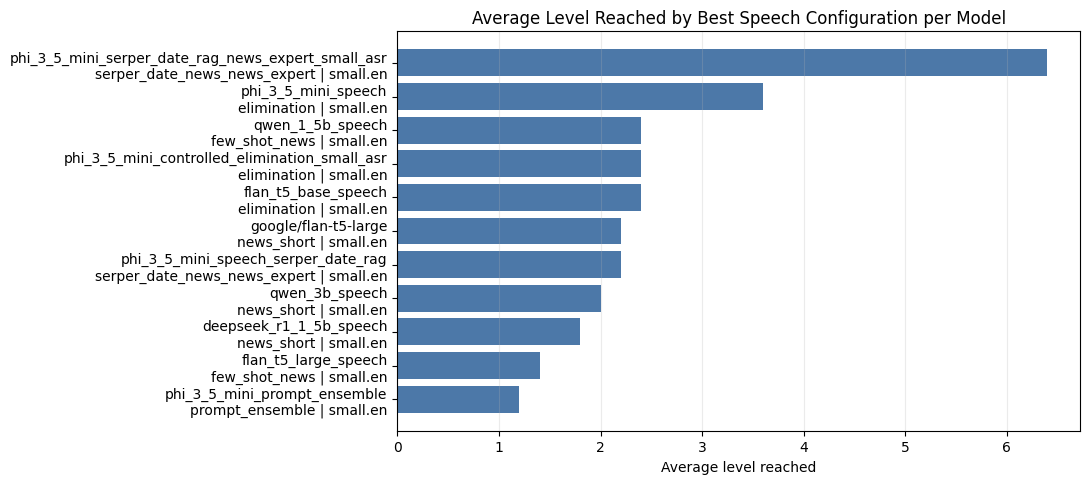

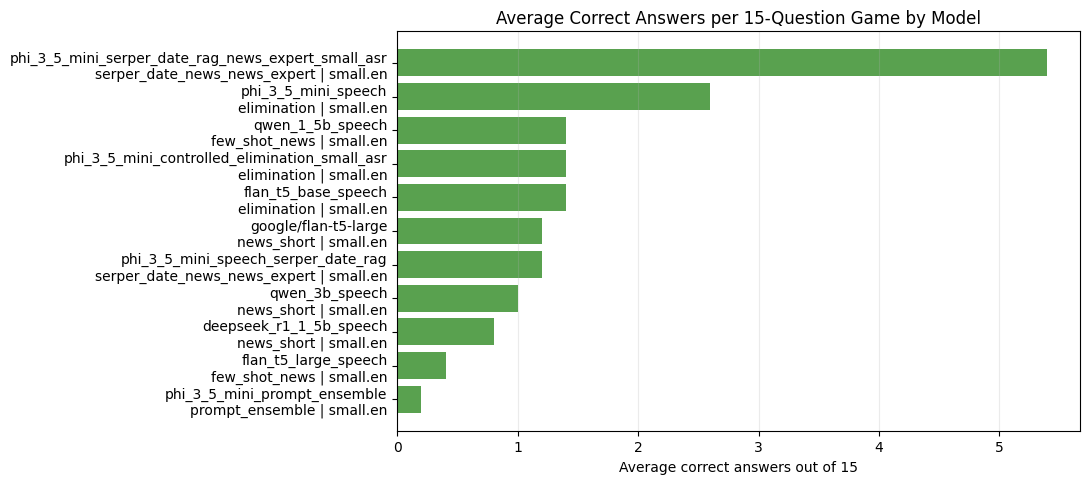

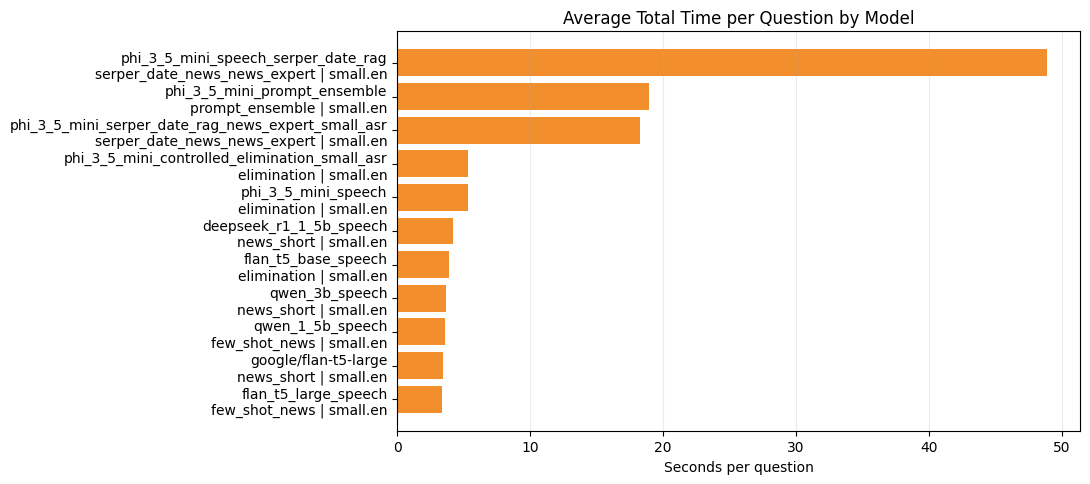

Saved clean CSV and PNG outputs in: speech_news_5run_comparison_outputs


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


SPEECH_COMPARISON_EXPECTED_RUNS = 5
SPEECH_COMPARISON_MIN_TOPIC_QUESTIONS = 2
SPEECH_COMPARISON_OUTPUT_DIR = Path("speech_news_5run_comparison_outputs")
SPEECH_COMPARISON_OUTPUT_DIR.mkdir(exist_ok=True)

SPEECH_COMPARABLE_LOG_NAMES = [
    "df_speech_prompt_benchmark",
    "df_speech_asr_comparison",
    "df_speech_answer_model_comparison",
    "df_speech_news_rag",
    "df_speech_rag",
    "df_speech_news_memory_first",
    "df_speech_memory_first",
    "df_speech_prompt_ensemble",
    "df_speech_controlled_final",
]

SPEECH_NAN_GUIDE = pd.DataFrame(
    [
        {
            "field_type": "RAG fields",
            "why_nan_appears": "Only RAG runs have retrieval scores, sources, and fallback reasons.",
            "what_to_do": "Compare RAG metrics only inside the RAG rows.",
        },
        {
            "field_type": "Memory fields",
            "why_nan_appears": "Only the final Speech News memory-first system logs memory hits.",
            "what_to_do": "Use memory_hit_rate to separate repeated-question cache gains from RAG gains.",
        },
        {
            "field_type": "WER fields",
            "why_nan_appears": "WER needs a reference question and the jiwer package.",
            "what_to_do": "Use ASR log probability and manual examples when WER is unavailable.",
        },
        {
            "field_type": "Legacy rows",
            "why_nan_appears": "Older quick tests did not log every enhanced column.",
            "what_to_do": "Use the clean tables in this section for the final report.",
        },
    ]
)

display(SPEECH_NAN_GUIDE)


def collect_comparable_speech_logs(include_legacy_speech_results=False):
    logs = []
    seen_dataframe_objects = set()

    for name in SPEECH_COMPARABLE_LOG_NAMES:
        value = globals().get(name)
        if isinstance(value, pd.DataFrame) and not value.empty and "correct" in value.columns:
            # Avoid double-counting legacy aliases that point to the same dataframe.
            value_id = id(value)
            if value_id in seen_dataframe_objects:
                continue
            seen_dataframe_objects.add(value_id)

            df_value = value.copy()
            df_value["source_table"] = name
            logs.append(df_value)

    if include_legacy_speech_results:
        value = globals().get("speech_results")
        if isinstance(value, pd.DataFrame) and not value.empty and "correct" in value.columns:
            df_value = value.copy()
            df_value["source_table"] = "speech_results_legacy"
            logs.append(df_value)

    if not logs:
        return pd.DataFrame()

    combined = pd.concat(logs, ignore_index=True, sort=False)

    if "mode" in combined.columns:
        mode_text = combined["mode"].fillna("speech").astype(str).str.lower()
        combined = combined[mode_text.eq("speech")].copy()

    return combined


def prepare_comparable_speech_logs(include_legacy_speech_results=False):
    raw_logs = collect_comparable_speech_logs(include_legacy_speech_results=include_legacy_speech_results)
    if raw_logs.empty:
        return pd.DataFrame()

    prepared = prepare_speech_question_level_analysis(raw_logs)
    if "source_table" not in prepared.columns:
        prepared["source_table"] = "unknown_source"

    for flag_column in ["correct", "valid_output", "used_fallback", "under_30_seconds", "near_timeout", "low_asr_confidence"]:
        if flag_column in prepared.columns:
            prepared[flag_column] = prepared[flag_column].fillna(False).astype(bool)

    for numeric_column in [
        "elapsed_seconds",
        "answer_elapsed_seconds",
        "question_asr_elapsed_seconds",
        "option_asr_elapsed_seconds",
        "question_wer",
        "rag_retrieval_score",
    ]:
        if numeric_column in prepared.columns:
            prepared[numeric_column] = pd.to_numeric(prepared[numeric_column], errors="coerce")

    prepared["comparison_config"] = (
        prepared["model_label"].astype(str)
        + " | "
        + prepared["prompt_type"].astype(str)
        + " | ASR="
        + prepared["asr_model"].astype(str)
    )
    prepared["comparison_run_key"] = (
        prepared["source_table"].astype(str)
        + "__"
        + prepared["model_label"].astype(str)
        + "__"
        + prepared["prompt_type"].astype(str)
        + "__"
        + prepared["asr_model"].astype(str)
        + "__run_"
        + prepared["run_id"].astype(str)
    )
    return prepared


def build_5run_model_comparison(prepared):
    if prepared.empty:
        return pd.DataFrame(), pd.DataFrame()

    run_level = prepared.groupby(
        ["source_table", "model_label", "prompt_type", "asr_model", "comparison_config", "comparison_run_key"]
    ).agg(
        level_reached=("correct", "count"),
        correct_answers=("correct", "sum"),
        final_earned_amount=("earned_amount", "max"),
        average_total_time_per_question=("elapsed_seconds", "mean"),
        max_total_time=("elapsed_seconds", "max"),
        average_answer_time=("answer_elapsed_seconds", "mean"),
        average_question_asr_time=("question_asr_elapsed_seconds", "mean"),
        average_option_asr_time=("option_asr_elapsed_seconds", "mean"),
        under_30_seconds_rate=("under_30_seconds", "mean"),
        valid_output_rate=("valid_output", "mean"),
        fallback_rate=("used_fallback", "mean"),
        near_timeout_rate=("near_timeout", "mean"),
        low_asr_confidence_count=("low_asr_confidence", "sum"),
        average_question_wer=("question_wer", "mean"),
    ).reset_index()

    config_summary = run_level.groupby(
        ["source_table", "model_label", "prompt_type", "asr_model", "comparison_config"]
    ).agg(
        runs_completed=("comparison_run_key", "nunique"),
        average_level_achieved=("level_reached", "mean"),
        best_level_achieved=("level_reached", "max"),
        average_correct_answers_in_game=("correct_answers", "mean"),
        best_correct_answers_in_game=("correct_answers", "max"),
        total_correct_answers=("correct_answers", "sum"),
        average_final_earned_amount=("final_earned_amount", "mean"),
        best_final_earned_amount=("final_earned_amount", "max"),
        average_total_time_per_question=("average_total_time_per_question", "mean"),
        max_total_time=("max_total_time", "max"),
        average_answer_time=("average_answer_time", "mean"),
        average_question_asr_time=("average_question_asr_time", "mean"),
        average_option_asr_time=("average_option_asr_time", "mean"),
        under_30_seconds_rate=("under_30_seconds_rate", "mean"),
        valid_output_rate=("valid_output_rate", "mean"),
        fallback_rate=("fallback_rate", "mean"),
        near_timeout_rate=("near_timeout_rate", "mean"),
        low_asr_confidence_count=("low_asr_confidence_count", "sum"),
        average_question_wer=("average_question_wer", "mean"),
    ).reset_index()

    config_summary["average_game_accuracy_out_of_15"] = (
        config_summary["average_correct_answers_in_game"] / MAX_GAME_QUESTIONS
    )
    config_summary["needs_more_runs"] = config_summary["runs_completed"] < SPEECH_COMPARISON_EXPECTED_RUNS
    config_summary = config_summary.sort_values(
        [
            "average_level_achieved",
            "average_correct_answers_in_game",
            "under_30_seconds_rate",
            "average_total_time_per_question",
        ],
        ascending=[False, False, False, True],
    ).reset_index(drop=True)
    config_summary.insert(0, "rank", range(1, len(config_summary) + 1))

    return config_summary, run_level


def choose_best_config_per_model(config_summary):
    if config_summary.empty:
        return pd.DataFrame()

    return (
        config_summary.sort_values(
            [
                "model_label",
                "average_level_achieved",
                "average_correct_answers_in_game",
                "under_30_seconds_rate",
                "average_total_time_per_question",
            ],
            ascending=[True, False, False, False, True],
        )
        .groupby("model_label")
        .head(1)
        .sort_values(
            ["average_level_achieved", "average_correct_answers_in_game", "under_30_seconds_rate"],
            ascending=False,
        )
        .reset_index(drop=True)
    )


def filter_to_best_model_configs(prepared, best_config_per_model):
    if prepared.empty or best_config_per_model.empty:
        return pd.DataFrame()

    keys = best_config_per_model[["source_table", "model_label", "prompt_type", "asr_model"]].drop_duplicates()
    return prepared.merge(keys, on=["source_table", "model_label", "prompt_type", "asr_model"], how="inner")


def build_subject_and_error_tables(best_logs):
    if best_logs.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    subject_model_summary = best_logs.groupby(["model_label", "topic"]).agg(
        subject_questions=("correct", "count"),
        subject_correct_answers=("correct", "sum"),
        subject_correct_rate=("correct", "mean"),
        subject_errors=("correct", lambda values: (~values.astype(bool)).sum()),
        average_total_time=("elapsed_seconds", "mean"),
        average_question_wer=("question_wer", "mean"),
        low_asr_confidence_count=("low_asr_confidence", "sum"),
    ).reset_index()
    subject_model_summary["subject_error_rate"] = (
        subject_model_summary["subject_errors"] / subject_model_summary["subject_questions"].clip(lower=1)
    )

    best_model_by_subject = (
        subject_model_summary[
            subject_model_summary["subject_questions"] >= SPEECH_COMPARISON_MIN_TOPIC_QUESTIONS
        ]
        .sort_values(
            ["topic", "subject_correct_rate", "subject_correct_answers", "subject_questions", "average_total_time"],
            ascending=[True, False, False, False, True],
        )
        .groupby("topic")
        .head(1)
        .reset_index(drop=True)
        .rename(columns={"model_label": "best_model_for_subject"})
    )

    error_by_model_subject_type = (
        best_logs[best_logs["correct"] == False]
        .groupby(["model_label", "topic", "error_type"])
        .size()
        .reset_index(name="error_count")
        .sort_values(["model_label", "topic", "error_count"], ascending=[True, True, False])
    )

    weak_subjects_by_model = (
        subject_model_summary[
            subject_model_summary["subject_questions"] >= SPEECH_COMPARISON_MIN_TOPIC_QUESTIONS
        ]
        .sort_values(
            ["model_label", "subject_error_rate", "subject_errors", "subject_questions"],
            ascending=[True, False, False, False],
        )
        .groupby("model_label")
        .head(3)
        .reset_index(drop=True)
    )

    return subject_model_summary, best_model_by_subject, error_by_model_subject_type, weak_subjects_by_model


def save_barh_plot(df, label_column, value_column, title, xlabel, filename, color="#4C78A8"):
    if df.empty or value_column not in df.columns:
        return

    plot_data = df[[label_column, value_column]].dropna().sort_values(value_column)
    if plot_data.empty:
        return

    height = max(4, 0.45 * len(plot_data))
    fig, ax = plt.subplots(figsize=(11, height))
    ax.barh(plot_data[label_column].astype(str), plot_data[value_column], color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(SPEECH_COMPARISON_OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()




speech_comparable_logs = prepare_comparable_speech_logs(include_legacy_speech_results=False)

if speech_comparable_logs.empty:
    print("No comparable enhanced speech logs found yet. Run the model/RAG/comparison cells above first.")
else:
    speech_5run_model_comparison, speech_5run_run_level = build_5run_model_comparison(speech_comparable_logs)
    speech_best_config_per_model = choose_best_config_per_model(speech_5run_model_comparison)
    speech_best_model_logs = filter_to_best_model_configs(speech_comparable_logs, speech_best_config_per_model)

    (
        speech_subject_model_summary,
        speech_best_model_by_subject,
        speech_error_by_model_subject_type,
        speech_weak_subjects_by_model,
    ) = build_subject_and_error_tables(speech_best_model_logs)

    speech_5run_model_comparison.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_news_clean_config_summary.csv", index=False)
    speech_5run_run_level.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_news_clean_run_level_summary.csv", index=False)
    speech_best_config_per_model.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_news_best_config_per_model.csv", index=False)
    speech_subject_model_summary.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_news_topic_summary.csv", index=False)
    speech_best_model_by_subject.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_news_best_model_by_topic.csv", index=False)
    speech_error_by_model_subject_type.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_news_error_summary.csv", index=False)
    speech_weak_subjects_by_model.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_news_weak_topics_by_model.csv", index=False)

    print("Clean 5-run model/configuration comparison")
    display(speech_5run_model_comparison)

    print("Best observed configuration per model")
    display(speech_best_config_per_model)

    print("Best model by subject")
    display(speech_best_model_by_subject)

    print("Weakest subjects for each model")
    display(speech_weak_subjects_by_model)

    print("Error analysis by model, subject, and error type")
    display(speech_error_by_model_subject_type)

    speech_best_config_per_model["model_config_label"] = (
        speech_best_config_per_model["model_label"].astype(str)
        + "\n"
        + speech_best_config_per_model["prompt_type"].astype(str)
        + " | "
        + speech_best_config_per_model["asr_model"].astype(str)
    )

    save_barh_plot(
        speech_best_config_per_model,
        "model_config_label",
        "average_level_achieved",
        "Average Level Reached by Best Speech Configuration per Model",
        "Average level reached",
        "speech_news_average_level_by_model.png",
    )

    save_barh_plot(
        speech_best_config_per_model,
        "model_config_label",
        "average_correct_answers_in_game",
        "Average Correct Answers per 15-Question Game by Model",
        "Average correct answers out of 15",
        "speech_news_average_correct_answers_by_model.png",
        color="#59A14F",
    )

    save_barh_plot(
        speech_best_config_per_model,
        "model_config_label",
        "average_total_time_per_question",
        "Average Total Time per Question by Model",
        "Seconds per question",
        "speech_news_average_time_by_model.png",
        color="#F28E2B",
    )


    print("Saved clean CSV and PNG outputs in:", SPEECH_COMPARISON_OUTPUT_DIR)


## Final report

### Aim of the Speech News section

In this section I tested the News quiz in a full speech pipeline. The system receives the question and answer options as audio, transcribes them with Whisper, sends the transcript to a local answer model, extracts one answer option, and submits the answer to the game.

This makes Speech News harder than the text News task. Errors can come from:

1. ASR transcription mistakes in names, dates, numbers, and organisations;
2. retrieval errors when the dated article evidence is weak or mixed;
3. answer-model reasoning errors;
4. invalid A/B/C/D extraction;
5. timeout risk when retrieval and generation are too slow.

The News competition is especially difficult because many questions refer to a specific article date. A model can fail even if it has good general knowledge, because the correct answer depends on a particular news report.

---

### Accuracy definition used in the report

For the final report, I use the full-game denominator:

```text
game accuracy = average correct answers / 15
```

This is the fairest metric for the game because each run can reach up to 15 questions. I do not rely on observed-question accuracy only, because that can make a model look better when it loses early after seeing only a few questions.

So the main metric in this report is:

```text
average correct answers out of 15
```

---

## Main result

### Best overall Speech News system

The best overall configuration in the clean 5-run comparison was:

```text
Phi-3.5-mini + Serper exact-date News RAG + news_expert prompt + Whisper small.en
```

In the notebook this appears as:

```text
phi_3_5_mini_serper_date_rag_news_expert_small_asr
```

This configuration achieved:

- average questions reached: **6.4**
- best questions reached: **12**
- average correct answers: **5.4 / 15**
- best correct answers: **11 / 15**
- game accuracy out of 15: **0.360**
- best game accuracy out of 15: **0.733**
- valid-output rate: **1.00**
- under-30-second rate: **0.982**
- near-timeout rate: **0.086**
- low-ASR-confidence count: **0**
- `rag_used_rate`: **1.00**
- average RAG retrieval score: **3.150**

This was the strongest Speech News result because it combined a stronger answer model with article-date retrieval. Unlike Science and Psychology, where the best final systems were non-RAG Phi systems, the News task benefited most from Serper exact-date RAG.

The top configurations in the clean table were:

| Rank | Configuration | Average questions reached | Best questions reached | Average correct / 15 | Game accuracy |
|---:|---|---:|---:|---:|---:|
| 1 | Phi-3.5-mini + Serper date RAG + news_expert + small.en | 6.4 | 12 | 5.4 / 15 | 0.360 |
| 2 | Phi-3.5-mini + elimination + small.en | 3.6 | 12 | 2.6 / 15 | 0.173 |
| 3 | Qwen 1.5B + few_shot_news + small.en | 2.4 | 3 | 1.4 / 15 | 0.093 |
| 4 | FLAN-T5-base + elimination + small.en | 2.4 | 4 | 1.4 / 15 | 0.093 |
| 5 | Controlled Phi-3.5-mini + elimination + small.en | 2.4 | 4 | 1.4 / 15 | 0.093 |
| 6 | FLAN-T5-large + news_short + small.en | 2.2 | 4 | 1.2 / 15 | 0.080 |

The main conclusion is that the fixed Serper RAG row was clearly better than the non-RAG systems. It more than doubled the average correct answers compared with the best non-RAG Phi row.

---

## Prompt comparison

Prompting affected performance, but the best prompt depended on whether retrieval was used.

In the FLAN-T5-large prompt benchmark with Whisper `small.en`, the best prompt types were:

| Prompt | Average questions reached | Best questions reached | Average correct / 15 |
|---|---:|---:|---:|
| `few_shot_news` | 1.8 | 3 | 0.8 |
| `news_expert` | 1.8 | 3 | 0.8 |
| `chain_of_thought` | 1.6 | 4 | 0.6 |
| `baseline` | 1.2 | 2 | 0.2 |
| `elimination` | 1.0 | 1 | 0.0 |
| `news_short` | 1.0 | 1 | 0.0 |

For Phi-3.5-mini without RAG, the best prompt was `elimination`:

| Phi configuration | Average questions reached | Best questions reached | Average correct / 15 |
|---|---:|---:|---:|
| Phi-3.5-mini + `elimination` | 3.6 | 12 | 2.6 |
| Phi-3.5-mini + `few_shot_news` | 1.8 | 3 | 0.8 |
| Phi-3.5-mini + `chain_of_thought` | 1.6 | 2 | 0.6 |
| Phi-3.5-mini + `news_expert` | 1.6 | 3 | 0.6 |
| Phi-3.5-mini + `baseline` | 1.4 | 2 | 0.4 |
| Phi-3.5-mini + `news_short` | 1.0 | 1 | 0.0 |

So the best non-RAG prompt for Phi was still `elimination`. This makes sense because elimination helps the model compare the answer options carefully.

However, the final best system used `news_expert` inside Serper RAG. In the RAG setting, the model has retrieved evidence, so the prompt needs to make the model use the evidence carefully rather than just eliminate options from memory.

---

## ASR comparison

The ASR comparison changed the Whisper model while keeping the answer model and prompt fixed.

The output showed:

| ASR model | Average questions reached | Best questions reached | Average correct / 15 | Game accuracy |
|---|---:|---:|---:|---:|
| `small.en` | 2.2 | 4 | 1.2 / 15 | 0.080 |
| `tiny.en` | 1.6 | 3 | 0.6 / 15 | 0.040 |
| `base.en` | 1.4 | 2 | 0.4 / 15 | 0.027 |

In this notebook, Whisper `small.en` was the best ASR setting for Speech News. This is why the final controlled systems used `small.en`.

Timing was not the main ASR problem. All three ASR rows had an under-30-second rate of **1.00**. The bigger issue was transcript quality: News questions contain names, dates, quoted statements, and organisations, and small ASR errors can damage retrieval or make the options harder to match.

---

## Answer-model comparison

The answer-model comparison showed that Speech News was much harder than Speech Science and Speech Psychology.

The best non-RAG answer-model row was:

```text
phi_3_5_mini_speech + elimination + small.en
```

It reached:

- average questions reached: **3.6**
- best questions reached: **12**
- average correct answers: **2.6 / 15**
- game accuracy out of 15: **0.173**
- valid-output rate: **1.00**
- under-30-second rate: **1.00**

This was the strongest non-RAG model result, but it was still much weaker than the fixed Serper RAG system.

The next best non-RAG rows were:

- `qwen_1_5b_speech + few_shot_news + small.en`: **1.4 / 15**
- `flan_t5_base_speech + elimination + small.en`: **1.4 / 15**
- `qwen_3b_speech + news_short + small.en`: **1.0 / 15**
- `deepseek_r1_1_5b_speech + news_short + small.en`: **0.8 / 15**

This shows that local model knowledge alone was not enough for the dated News quiz. The answer model still matters, but retrieval mattered more in this section.

---

## RAG result

The fixed Serper exact-date RAG system was the best final Speech News system.

The first Serper RAG run reached only **1.2 / 15** correct answers, even though `rag_used_rate` was **1.00**. It also had a lower valid-output rate (**0.933**) and a higher near-timeout rate (**0.167**). This showed that simply adding retrieval was not enough.

The controlled fixed RAG run was much better:

```text
Phi-3.5-mini + Serper exact-date RAG + news_expert + small.en
```

It achieved:

- average questions reached: **6.4**
- best questions reached: **12**
- average correct answers: **5.4 / 15**
- game accuracy out of 15: **0.360**
- `rag_used_rate`: **1.00**
- average retrieval score: **3.150**
- valid-output rate: **1.00**

The Serper diagnostics also showed:

- **35** Serper requests;
- **0** Serper errors;
- **9** exact-date searches;
- **7** exact-date hits;
- **0** empty Serper retrievals;
- **0** direct evidence answers.

This means retrieval was available and direct mention-count answering was not used. The model answered using retrieved evidence rather than an unsafe direct rule.

Because the fixed RAG row outperformed the best non-RAG Phi row (**5.4 / 15** vs **2.6 / 15**), RAG is the best final approach for Speech News.

---

## Prompt ensemble result

The prompt ensemble was tested as an optional speech experiment, but it did not help Speech News.

It reached:

- average questions reached: **1.2**
- best questions reached: **2**
- average correct answers: **0.2 / 15**
- game accuracy out of 15: **0.013**

This was much weaker than both the best non-RAG Phi row and the fixed Serper RAG row. Therefore, I would not use the prompt ensemble as the final News speech system.

---

## Topic analysis

The topic table shows that the best system varied by subject. This is expected because News questions cover politics, business, health, conflict, finance, and general current affairs.

The best observed model by topic was:

| Topic | Best observed model | Correct answers | Correct rate |
|---|---|---:|---:|
| Business & technology | Phi-3.5-mini Serper RAG | 2 / 2 | 1.00 |
| Economy & finance | FLAN-T5-base | 1 / 2 | 0.50 |
| Health & public policy | Phi-3.5-mini Serper RAG | 2 / 2 | 1.00 |
| International relations & conflict | Phi-3.5-mini Serper RAG | 4 / 4 | 1.00 |
| Other news/current affairs | Controlled Phi-3.5-mini elimination | 5 / 5 | 1.00 |
| Politics & government | Phi-3.5-mini Serper RAG | 3 / 4 | 0.75 |

This supports the final choice of RAG. The Serper RAG system was strongest in several of the most date-sensitive News areas, especially business/technology, international relations, and politics.

However, these topic counts are small, so the topic analysis should be used for interpretation rather than as a definitive ranking.

---

## Error analysis

The strongest fixed RAG system did not mainly fail because of invalid output. Its valid-output rate was **1.00**, and the low-ASR-confidence count was **0**.

The remaining errors for the fixed RAG system were:

| Topic | Error type | Error count |
|---|---|---:|
| Health & public policy | `rag_used_but_wrong` | 1 |
| Other news/current affairs | `rag_used_but_wrong` | 3 |
| Politics & government | `timeout_risk` | 1 |

This means the main remaining issue was not whether RAG was used. The retrieved evidence was used, but the model still sometimes selected the wrong option.

For News, this is understandable. A retrieved article can mention several people, organisations, or events. The model has to identify the exact relation asked by the question, not only find which option appears in the evidence.

The old Serper RAG row also had `invalid_or_unparsed_model_output` and more timeout risk, but the controlled fixed RAG row improved these problems.

---

## Final conclusion

The best final Speech News system in this notebook is:

```text
Phi-3.5-mini + Serper exact-date News RAG + news_expert prompt + Whisper small.en
```

It achieved **5.4 correct answers out of 15** on average, reached **6.4 questions** on average, and reached **12 questions** in its best run. It also had a valid-output rate of **1.00** and used retrieved evidence in every RAG attempt.

This result is not perfect, but it is clearly stronger than the best non-RAG system, which achieved **2.6 / 15** correct answers. Therefore, for Speech News, the final system should be the fixed Serper RAG pipeline rather than a pure local-model answerer.

The main reason is that News questions are date-specific. Local open-weight models often do not know the exact article details, while Serper retrieval can provide external evidence from the relevant date window.

For future work, I would improve this section by adding better evidence reranking, stricter handling of negation and relation questions, and more robust ASR repair for names, dates, and organisations. This should reduce the remaining `rag_used_but_wrong` errors and make the Speech News system more reliable.
